# Systematic publication results · version 4

**Main reporting focus:** five-fold CV ensembles evaluated on the fixed held-out cohort.
Best-validation-fold checkpoints and full-development refits are supplementary sensitivity analyses.
This notebook reads only `Systematic_Methodology` artifacts; it does not train, load checkpoints,
generate inference, tune prompts, or modify source results. Run every cell from top to bottom.
This version integrates the completed run set and the radiologist's exploratory reread.

**Version boundary:** `Publication_Results_4.ipynb` → `output_4/`; deliverable filenames use `_4`.
Future notebook versions should use a new numbered notebook and export folder.

**Version-4 scope:** 13 supervised pipelines, including both 3DINO linear probing and LoRA.
The publication-derived Merlin full-network addition (FullFineTune CV_2) is retained alongside
its frozen and corrected adapter pipelines. Figures 3a and 3b separate partial adaptation/frozen
comparators from full-network Merlin/MedicalNet fine-tuning and DenseNet training from scratch.
All five sizes and all available checkpoint routes are included. Earlier notebooks remain unchanged.
The previous omission of 3DINO linear probing was an analysis-scope omission, not a failed run.
COLIPRI native pooling is not uniformly a strict linear probe. Source provenance and method-specific
CV identities are preserved; historical Merlin full-fine-tuning grids and pre-fix adapters are excluded.
Only COLIPRI, FlexiCT, Merlin and Pillar-0 enter the separate zero-shot supplement.
DenseNet uses random initialization. No inference, retraining or reference-label changes are performed.

The earlier project documentation/statistical plan used refit as primary. Ensemble-centered reporting
was requested after existing results were available. This is a documented reporting change, not a
prospectively registered primary analysis. Inferential comparisons below are exploratory and conditional
on the fitted models. Test-sample confidence intervals do not measure optimization-seed variability.

[RSNA author instructions](https://pubs.rsna.org/page/ai/author-instructions) were checked in the previous release on 2026-10-18; the editorial package retains four main tables
and six numbered main figures, with Figure 3 split into panels a and b.
[CLAIM 2024](https://pubs.rsna.org/doi/10.1148/ryai.240300) guides the reporting checklist at the end.

## 1. Imports
Only analysis libraries are required. Install `requirements_4.txt` in the notebook environment if needed.
The small companion modules contain ingestion, statistics and reusable plotting functions; each
scientific calculation, table and figure is introduced and run separately below.

In [1]:
import sys
import json
import platform
import html
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix

## 2. Locate the systematic workspace
Inputs are discovered under `Results/` and `Dataset/Splits/`. Generated results stay beside this
notebook, following the existing notebook-local export convention.

In [2]:
def locate_root(start):
    for parent in (start.resolve(), *start.resolve().parents):
        for candidate in (parent, parent / 'Systematic_Methodology'):
            if (candidate / 'Dataset' / 'Splits').is_dir() and (candidate / 'Notebooks').is_dir():
                return candidate
    raise FileNotFoundError('Cannot locate Systematic_Methodology')

ROOT = locate_root(Path.cwd())
NOTEBOOK_DIR = ROOT / 'Notebooks' / 'Publication_Results'
sys.path.insert(0, str(NOTEBOOK_DIR))
import analysis_helpers_4 as ah
import plot_helpers_4 as ph
EXPORT_ROOT = NOTEBOOK_DIR / 'output_4'
print('Inputs:', ROOT / 'Results')
print('Outputs:', EXPORT_ROOT)

## 3. Analysis configuration
Macro-F1 is the headline endpoint. Balanced accuracy and macro average precision are key supporting
endpoints. AP is the non-interpolated average-precision summary, **not trapezoidal PR area**.
AUROC is the unweighted mean of five one-vs-rest AUCs. Classification uses probability argmax;
undefined class F1 is zero. Precision with no positive predictions is displayed as missing.

Bootstrap: 10,000 class-stratified patient samples, percentile 95% intervals, identical resamples
for every model. This fixes observed class counts; PPV/AP/calibration remain cohort-prevalence dependent.
Permutation tests swap paired predictions within patient and test macro-F1 differences, two-sided.
Holm adjustment uses the full configured comparison-family size, including pending comparisons.

In [3]:
ANALYSIS_VERSION = 4
BOOTSTRAP_REPLICATES = 10_000
PERMUTATION_REPLICATES = 10_000
SEED = 20260928
CALIBRATION_BINS = 10
PRIMARY_SOURCE = 'cv_ensemble'
MAIN_PERCENTAGE = 100
FIGURE_DPI = 300
RUN_OVERRIDES = {}  # 'Model|Method|100|cv_ensemble': exact run_id, never chosen by test score
EXPORT_PATIENT_LEVEL = False  # publication exports are aggregate by default
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False})
sns.set_palette('colorblind')
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_rows', 30)

### Export helpers
Every artifact is registered with a caption and checksum in the final manifest. The manifest and index
define the current export set; old unreferenced files from earlier executions are not current results.
Bootstrap caches are keyed by source hashes, analysis-code hash, seed, and settings.

In [4]:
ARTIFACTS = []
for sub in ['main/tables', 'main/figures', 'supplementary/tables', 'supplementary/figures', 'audit', 'cache']:
    (EXPORT_ROOT / sub).mkdir(parents=True, exist_ok=True)

def record_artifact(path, caption):
    ARTIFACTS.append({'path': path.relative_to(EXPORT_ROOT).as_posix(),
                      'caption': caption, 'sha256': ah.digest(path)})

def save_table(frame, stem, caption, section='supplementary'):
    folder = EXPORT_ROOT / ('audit' if section == 'audit' else section + '/tables')
    path = folder / f'{stem}_4.csv'
    frame.to_csv(path, index=False)
    record_artifact(path, caption)
    page = path.with_suffix('.html')
    page.write_text('<!doctype html><meta charset="utf-8"><style>body{font-family:Arial;margin:32px;color:#172b3a}table{border-collapse:collapse;font-size:12px}th,td{padding:8px;border-bottom:1px solid #ddd;text-align:left}th{background:#eef3f7}caption{text-align:left;font-size:16px;padding:12px 0}</style>' + '<h2>' + html.escape(stem.replace('_',' ')) + '</h2><p>' + html.escape(caption) + '</p>' + frame.to_html(index=False,escape=True,float_format=lambda x:f'{x:.4f}'),encoding='utf-8')
    record_artifact(page, caption)
    return frame

def save_figure(fig, stem, caption, section='supplementary'):
    for extension in ['png', 'pdf']:
        path = EXPORT_ROOT / section / 'figures' / f'{stem}_4.{extension}'
        fig.savefig(path, dpi=FIGURE_DPI, bbox_inches='tight', facecolor='white')
        record_artifact(path, caption)
    plt.show()
    plt.close(fig)
    display(Markdown('**Caption.** ' + caption))

## 4. Import split manifests
The JSON manifests are authoritative. Historical 70/30 planning rows in the text plan are not the
current five-fold protocol. Preserve string patient IDs, including leading zeros.

In [5]:
splits, cohort, split_audit, patient_ids, y_true = ah.load_splits(ROOT)
DEVELOPMENT_COUNTS = {p: splits[p]['cross_validation']['development_total'] for p in ah.PERCENTAGES}
N_TEST = len(patient_ids)
display(split_audit)
save_table(split_audit, 'split_integrity', 'Manifest hashes and patient partition checks.', 'audit');

### Table 1. Cohort composition
The percentages refer to the development-sampling policy. Perforation remains at 40 development
patients, so the 20% subset contains 248/1,080 development patients. Each ensemble member trains on
four development folds; the ensemble as a whole draws on the complete selected development pool.
`Sigmoid` retains the stored category name: its clinical definition requires manuscript confirmation.
Age, sex and scanner characteristics are not inferred from labels or fabricated.

In [6]:
table1 = cohort.rename(columns={'Cholezystitis': 'Cholecystitis'})
display(save_table(table1, 'Table_1_cohort',
    'Development and fixed held-out patient counts by class. Perforation is fixed across development sizes.', 'main'))

,cohort,percentage,Appendicitis,Cholecystitis,Normal,Perforation,Sigmoid,total
0,20% development,20,38,30,72,40,68,248
1,40% development,40,76,59,144,40,137,456
2,60% development,60,114,89,216,40,205,664
3,80% development,80,152,118,288,40,274,872
4,100% development,100,190,148,360,40,342,1080
5,Fixed held-out test,0,47,37,90,18,86,278


### Figure 1. Available cohort and evaluation design
This is a partition diagram, not a recruitment/exclusion flowchart; upstream screening counts and
reference-standard details must be supplied from the clinical study records.

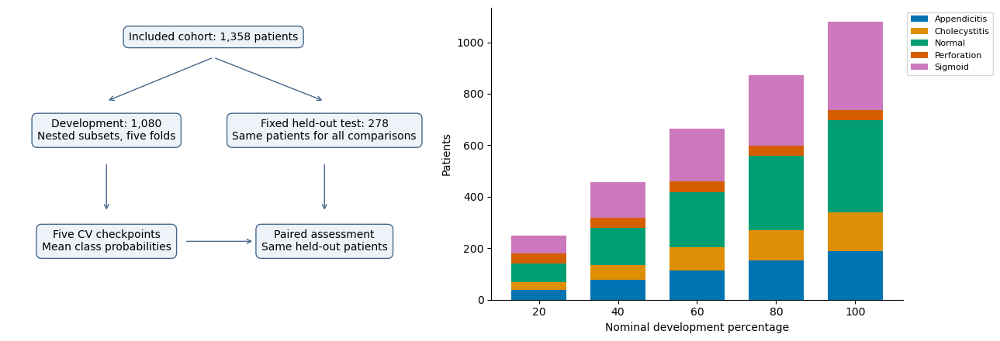

**Caption.** Included cohort partition and nested development subsets. The same 278 held-out patients are evaluated throughout. Perforation development support remains 40.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].axis('off')
boxes = [(0.5, .9, f'Included cohort: {DEVELOPMENT_COUNTS[100] + N_TEST:,} patients'),
         (.24, .58, f'Development: {DEVELOPMENT_COUNTS[100]:,}\nNested subsets, five folds'),
         (.77, .58, f'Fixed held-out test: {N_TEST}\nSame patients for all comparisons'),
         (.24, .2, 'Five CV checkpoints\nMean class probabilities'),
         (.77, .2, 'Paired assessment\nSame held-out patients')]
for x, yy, text in boxes:
    axes[0].text(x, yy, text, ha='center', va='center', fontsize=10,
                 bbox=dict(boxstyle='round,pad=.5', facecolor='#edf3f8', edgecolor='#47688c'))
for a, b in [((.5,.83),(.24,.68)), ((.5,.83),(.77,.68)), ((.24,.47),(.24,.3)), ((.77,.47),(.77,.3)), ((.43,.2),(.60,.2))]:
    axes[0].annotate('', xy=b, xytext=a, arrowprops=dict(arrowstyle='->', color='#47688c'))
development = cohort[cohort.percentage > 0].set_index('percentage')[ah.CLASSES]
development.rename(columns=dict(zip(ah.CLASSES, ah.DISPLAY_CLASSES))).plot.bar(stacked=True, ax=axes[1], width=.7)
axes[1].set(xlabel='Nominal development percentage', ylabel='Patients')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1,1))
fig.tight_layout()
save_figure(fig, 'Figure_1_cohort_design',
    f'Included cohort partition and nested development subsets. The same {N_TEST} held-out patients are evaluated throughout. Perforation development support remains 40.', 'main')

## 5. Discover saved test artifacts
Discovery is restricted to configured production method/Test paths. Archives, backup directories,
grid-validation outputs, caches, smoke tests, and outside-folder historical DenseNet results are excluded
by path. Zero-shot protocols are read separately for the four foundation-model families only.
Excluded methods and non-publication foundation-model configurations receive `scope_excluded`
audit entries and never enter performance tables or statistics.

Integrity validation checks all canonical files, completion hashes where the pipeline supplies them,
the exact manifest patient set and truths, CSV/JSON agreement, class mapping, finite probabilities,
normalization, and saved-prediction/argmax agreement. Older Merlin/Pillar-0 unsealed artifacts receive
the explicit status `legacy_unsealed_content_validated`; this is not equivalent to a verified seal.

In [8]:
inventory, predictions, discovery_audit, stored_metrics, input_hashes = ah.discover(ROOT, patient_ids, y_true)
if inventory.empty:
    raise RuntimeError('No valid held-out results found. Review discovery_audit before continuing.')
display(discovery_audit.groupby(['status', 'reason'], dropna=False).size().rename('runs').reset_index())
save_table(discovery_audit, 'discovery_audit', 'Accepted and excluded artifacts with reasons.', 'audit')
save_table(inventory, 'all_run_provenance', 'Exact provenance for every valid result; no score-based selection.', 'audit');

## 6. Recompute point estimates from patient predictions
Stored summary metrics are a cross-check rather than the analytical source of truth. A mismatch beyond
1e-6 or a different confusion matrix stops the notebook for review; no failed check is silently repaired.

In [9]:
point_rows, class_rows, matrices, metric_checks = [], [], {}, []
for run in inventory.itertuples():
    p, pred = predictions[run.run_id]
    estimates = ah.point_metrics(y_true, p, CALIBRATION_BINS)
    point_rows.append({'run_id': run.run_id, **estimates})
    classes, matrix = ah.class_metrics(y_true, p)
    class_rows.extend({'run_id': run.run_id, **row} for row in classes)
    matrices[run.run_id] = matrix
    stored = stored_metrics[run.run_id]
    for name in ['accuracy', 'balanced_accuracy', 'f1_macro', 'average_precision_macro']:
        if name in stored:
            metric_checks.append({'run_id': run.run_id, 'metric': name,
                'recomputed': estimates[name], 'stored': stored[name],
                'passed': bool(np.isclose(estimates[name], stored[name], atol=1e-6, rtol=0))})
    if 'confusion_matrix' in stored:
        metric_checks.append({'run_id': run.run_id, 'metric': 'confusion_matrix',
                             'passed': bool(np.array_equal(matrix, stored['confusion_matrix']))})
points = pd.DataFrame(point_rows)
class_results = pd.DataFrame(class_rows).merge(inventory, on='run_id', validate='many_to_one')
checks = pd.DataFrame(metric_checks)
save_table(checks, 'recomputed_metric_checks', 'Patient-derived estimates versus source summaries.', 'audit')
assert checks.passed.all(), 'Summary mismatch: inspect recomputed_metric_checks_4.csv'
print(f'Recomputed {len(points)} runs; all {len(checks)} summary checks passed.')

## 7. Define comparable runs without consulting test scores
Foundation-model supervised runs require publication-derived provenance; unrelated grid/default runs
cannot replace missing eligible results. Native publication-defined grid searches remain eligible.
For reference-model pipelines, prefer publication settings, then development-selected grids,
then defaults, retaining the actual evidence label. Multiple candidates at the same preferred level remain
unresolved unless an explicit provenance-based override is configured. Unknown origins are not
automatically promoted. CV IDs may change across percentages and are never assumed interchangeable.
Only in-scope alternatives remain in supplementary tables; excluded methods are not retained there.

This is a comparison of model-specific adaptation pipelines, not a controlled architecture-only
experiment: input processing, pretrained data, readout and tuning budgets differ.

In [10]:
selected, selection_audit = ah.choose_runs(inventory, RUN_OVERRIDES)
coverage = ah.coverage_table(inventory, selected, discovery_audit)
save_table(selection_audit, 'run_selection_rules', 'Configuration-based inclusion; unresolved cells are explicit.', 'audit')
save_table(coverage, 'run_coverage', 'Expected model/method/percentage/source combinations and current status.', 'audit')
display(coverage[coverage.source == PRIMARY_SOURCE].pivot_table(
    index=['model', 'method'], columns='percentage', values='status', aggfunc='first'))

### Table 2. Model and adaptation methods
The table lists planned methods, including pending methods. The detailed provenance export supplies
exact parameters and profile signatures. Publication-derived settings do not imply an exact replication
of the original paper on this five-class abdominal task.

In [11]:
method_rows = []
for model, methods in ah.METHODS.items():
    for method in methods:
        chosen = selected[(selected.model == model) & (selected.method == method) & (selected.source == PRIMARY_SOURCE)]
        method_rows.append({'model': model, 'method': ah.METHOD_LABELS[method],
            'initialization': 'Random initialization' if model == 'DenseNet' else 'Pretrained encoder',
            'available_ensemble_percentages': ', '.join(map(str, sorted(chosen.percentage))) or 'Pending',
            'parameter_origins': ', '.join(sorted(chosen.source_family.unique())) or 'Pending',
            'comparison_group': 'Foundation-model pipeline' if model in ah.FOUNDATION_MODELS else 'Reference pipeline',
            'evidence_note': ah.EVIDENCE_NOTES[(model, method)]})
display(save_table(pd.DataFrame(method_rows), 'Table_2_methods',
    'Planned model/adaptation methods, initialization and available CV-ensemble coverage.', 'main'))

,model,method,initialization,available_ensemble_percentages,parameter_origins,comparison_group,evidence_note
0,3DINO,Frozen features,Pretrained encoder,"20, 40, 60, 80, 100",publication,Reference pipeline,Publication-derived frozen-encoder linear probe: native 52-candidate search over learn...
1,3DINO,LoRA,Pretrained encoder,"20, 40, 60, 80, 100",default,Reference pipeline,"Project-adapted 3DINO LoRA classification; pretrained backbone with adapters, not full..."
2,COLIPRI,Frozen + native pooling,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,Publication-derived native pooling search; learned pooling is not uniformly a strict l...
3,COLIPRI,Final block,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,Publication-anchored downstream schedule/LR; final-block scope and five-class head are...
4,FlexiCT,Frozen features,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,Publication-derived frozen projected features and model-native classifier search
5,FlexiCT,Final block,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,Publication-anchored optimizer/LR/scheduler; final-block classification scope and stop...
6,Merlin,Frozen features,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,Publication-derived frozen image encoder with a task-adapted five-class linear head
7,Merlin,ConvLoRA + LLRD,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,Publication-inspired image-only ConvLoRA with layer-wise learning-rate decay; task-ada...
8,Merlin,Full fine-tuning,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,"Retrospective publication-derived full-network addition, FullFineTune CV_2; distinct f..."
9,Pillar0,Frozen features,Pretrained encoder,"20, 40, 60, 80, 100",publication,Foundation-model pipeline,Publication-derived frozen-feature linear head; five-class loss and labels are task ad...


### Completed reference-pipeline coverage
The completed DenseNet and MedicalNet ensembles are verified across all five fractions. No training
or evaluation command is run by this notebook.

In [12]:
cnn_status = coverage[(coverage.model.isin(['DenseNet','MedicalNet'])) & (coverage.source == PRIMARY_SOURCE)]
display(cnn_status[['model','percentage','status']])
assert (cnn_status.status == 'available').all()

,model,percentage,status
165,MedicalNet,20,available
168,MedicalNet,40,available
171,MedicalNet,60,available
174,MedicalNet,80,available
177,MedicalNet,100,available
180,DenseNet,20,available
183,DenseNet,40,available
186,DenseNet,60,available
189,DenseNet,80,available
192,DenseNet,100,available


## 8. Define paired comparison families
The 100% exploratory comparison family is fixed below: each retained frozen and adapted foundation
method versus DenseNet, each retained adaptation versus its frozen method, and MedicalNet full fine-tuning versus DenseNet. Version 4 adds 3DINO probe contrasts and
three Merlin full-network contrasts. All 19 tests are recalculated and Holm-adjusted as one expanded
exploratory family; adjusted P values from version 3 are not reused.
Unavailable pairs are exported as pending. No test-score winner is selected. Comparisons at smaller
development sizes and alternative checkpoint sources are descriptive sensitivity analyses.

In [13]:
FROZEN_METHODS = ah.FROZEN_METHODS
PAIR_PLAN = []
for model, frozen in FROZEN_METHODS.items():
    PAIR_PLAN.append((model, frozen, 'DenseNet', 'FromScratch', 'foundation_vs_scratch'))
    adapted = ah.ADAPTATION_METHODS[model]
    PAIR_PLAN.append((model, adapted, model, frozen, 'within_model_adaptation'))
    PAIR_PLAN.append((model, adapted, 'DenseNet', 'FromScratch', 'adapted_foundation_vs_scratch'))
for model in ['MedicalNet']:
    PAIR_PLAN.append((model, 'LoRA' if model == '3DINO' else 'FullFineTune', 'DenseNet', 'FromScratch', 'reference_baselines'))
PAIR_PLAN.extend([
    ('Merlin','FullFineTune','DenseNet','FromScratch','full_network_addition'),
    ('Merlin','FullFineTune','Merlin','ConvLoRA_LLRD','full_network_addition'),
    ('Merlin','FullFineTune','Merlin','LinearProbe','full_network_addition')])
assert len(PAIR_PLAN)==19 and len({p[:4] for p in PAIR_PLAN})==19
pair_plan = pd.DataFrame(PAIR_PLAN, columns=['model_a','method_a','model_b','method_b','family'])
save_table(pair_plan, 'planned_comparisons', 'All configured 100% ensemble comparisons, including pending pairs.', 'audit')
display(pair_plan)

## 9. Patient-level bootstrap uncertainty
Use identical stratified multinomial weights for all runs, equivalent to resampling patients with
replacement within each reference class. Vectorized AP calculations account for tied scores.
The first execution computes intervals for every valid run; subsequent executions reuse only
hash-matching caches. Changing predictions or statistical settings invalidates the relevant cache.

In [14]:
bootstrap_weights = ah.stratified_weights(y_true, BOOTSTRAP_REPLICATES, SEED)
assert np.all(bootstrap_weights.sum(axis=1) == N_TEST)
bootstrap = {}
for number, run in enumerate(inventory.itertuples(), 1):
    bootstrap[run.run_id] = ah.bootstrap_cached(run, y_true, predictions[run.run_id][0],
        bootstrap_weights, EXPORT_ROOT / 'cache', SEED, CALIBRATION_BINS)
    if number % 20 == 0 or number == len(inventory):
        print(f'Bootstrap complete: {number}/{len(inventory)} runs', flush=True)

Bootstrap complete: 20/192 runs
Bootstrap complete: 40/192 runs
Bootstrap complete: 60/192 runs
Bootstrap complete: 80/192 runs
Bootstrap complete: 100/192 runs
Bootstrap complete: 120/192 runs
Bootstrap complete: 140/192 runs
Bootstrap complete: 160/192 runs
Bootstrap complete: 180/192 runs
Bootstrap complete: 192/192 runs


### Assemble interval tables
Point estimates and intervals are kept in numeric columns for reproducibility; rounded publication
tables are derived from these columns. Display ordering follows the configured model/method order,
not held-out performance.

In [15]:
interval_rows = []
for run_id, samples in bootstrap.items():
    row = {'run_id': run_id}
    for metric, values in samples.items():
        row[metric + '_low'], row[metric + '_high'] = np.quantile(values, [.025, .975])
    interval_rows.append(row)
results = inventory.merge(points, on='run_id', validate='one_to_one').merge(pd.DataFrame(interval_rows), on='run_id', validate='one_to_one')
chosen_results = results[results.run_id.isin(selected.run_id)].copy()
ensembles = chosen_results[chosen_results.source == PRIMARY_SOURCE].copy()
main = ensembles[ensembles.percentage == MAIN_PERCENTAGE].copy()
order = {(m, method): i for i, (m, method) in enumerate((m, t) for m, ts in ah.METHODS.items() for t in ts)}
main = main.assign(display_order=[order[(r.model,r.method)] for r in main.itertuples()]).sort_values('display_order')
save_table(results, 'Table_S1_all_numeric_results', 'All valid runs, point estimates and patient-bootstrap 95% CIs.')

Out[15]: 
                                                                                        run_id  ...  ece_high
0                                         3DINO/LinearProbe/Test/CV_1/best_cv_fold/100_percent  ...  0.276920
1                                          3DINO/LinearProbe/Test/CV_1/cv_ensemble/100_percent  ...  0.200599
2                               3DINO/LinearProbe/Test/CV_1/refit_full_development/100_percent  ...  0.217799
3                                          3DINO/LinearProbe/Test/CV_2/best_cv_fold/80_percent  ...  0.322614
4                                           3DINO/LinearProbe/Test/CV_2/cv_ensemble/80_percent  ...  0.240153
..                                                                                         ...  ...       ...
187                            Pillar0/LinearProbe/Test/CV_1/refit_full_development/20_percent  ...  0.294095
188                            Pillar0/LinearProbe/Test/CV_1/refit_full_development/40_percent  ...  0.278806


## 10. Main CV-ensemble performance
### Table 3. Full development pool
The table uses the same held-out patients for every row. Full provenance is in Table S1 and the audit;
refit results never fill a missing ensemble cell.

In [16]:
table3 = ah.formatted_table(main, ['f1_macro','balanced_accuracy','average_precision_macro','roc_auc_macro','accuracy'])
table3['status'] = 'Available'
pending_main = coverage[(coverage.source == PRIMARY_SOURCE) & (coverage.percentage == MAIN_PERCENTAGE) & (coverage.status != 'available')]
for row in pending_main.itertuples():
    table3 = pd.concat([table3, pd.DataFrame([{'model':row.model,'method':row.method,
        'percentage':MAIN_PERCENTAGE,'source':PRIMARY_SOURCE,'status':row.status}])], ignore_index=True)
table3 = table3[['model','method','n_test'] + [c for c in table3 if '(95% CI)' in c]].copy()
table3['method'] = table3.method.map(ah.METHOD_LABELS)
table3['model'] = table3.model.replace({'Pillar0':'Pillar-0'})
table3 = table3.rename(columns={'model':'Model','method':'Method','n_test':'Test patients'})
display(save_table(table3, 'Table_3_main_performance',
    f'CV ensembles at the full development pool on {N_TEST} held-out patients; estimates with 95% stratified patient-bootstrap CIs. Merlin ConvLoRA+LLRD uses the corrected CV_2 implementation; 3DINO includes linear probing and LoRA; Merlin full-network CV_2 is separately identified. Full provenance: Table S1.', 'main'))

,Model,Method,Test patients,Macro F1 (95% CI),Balanced accuracy (95% CI),Macro average precision (95% CI),Macro OvR AUROC (95% CI),Accuracy (95% CI)
1,3DINO,Frozen features,278,"0.489 (0.416, 0.557)","0.473 (0.408, 0.541)","0.522 (0.464, 0.597)","0.786 (0.747, 0.823)","0.525 (0.468, 0.583)"
20,3DINO,LoRA,278,"0.403 (0.357, 0.449)","0.423 (0.377, 0.470)","0.543 (0.493, 0.620)","0.819 (0.786, 0.851)","0.543 (0.493, 0.594)"
33,COLIPRI,Frozen + native pooling,278,"0.548 (0.478, 0.613)","0.541 (0.472, 0.608)","0.595 (0.536, 0.671)","0.837 (0.804, 0.869)","0.561 (0.504, 0.619)"
48,COLIPRI,Final block,278,"0.665 (0.594, 0.728)","0.643 (0.574, 0.710)","0.737 (0.677, 0.801)","0.903 (0.876, 0.927)","0.683 (0.629, 0.737)"
91,FlexiCT,Frozen features,278,"0.809 (0.750, 0.863)","0.802 (0.742, 0.860)","0.888 (0.842, 0.931)","0.968 (0.953, 0.980)","0.849 (0.806, 0.888)"
76,FlexiCT,Final block,278,"0.920 (0.881, 0.954)","0.919 (0.876, 0.956)","0.957 (0.929, 0.980)","0.988 (0.979, 0.994)","0.928 (0.896, 0.957)"
150,Merlin,Frozen features,278,"0.299 (0.259, 0.342)","0.346 (0.315, 0.380)","0.543 (0.491, 0.615)","0.830 (0.801, 0.858)","0.525 (0.486, 0.565)"
125,Merlin,ConvLoRA + LLRD,278,"0.646 (0.578, 0.712)","0.631 (0.565, 0.699)","0.720 (0.662, 0.789)","0.901 (0.875, 0.926)","0.687 (0.633, 0.741)"
140,Merlin,Full fine-tuning,278,"0.746 (0.680, 0.806)","0.730 (0.668, 0.793)","0.815 (0.762, 0.879)","0.941 (0.918, 0.961)","0.788 (0.741, 0.835)"
181,Pillar-0,Frozen features,278,"0.724 (0.667, 0.781)","0.742 (0.681, 0.802)","0.797 (0.748, 0.863)","0.939 (0.920, 0.956)","0.755 (0.705, 0.802)"


### Figure 2. Performance with uncertainty
Overlapping individual confidence intervals do not test a paired difference; use the paired analysis
below for comparisons. Rows are not ranked by test score.

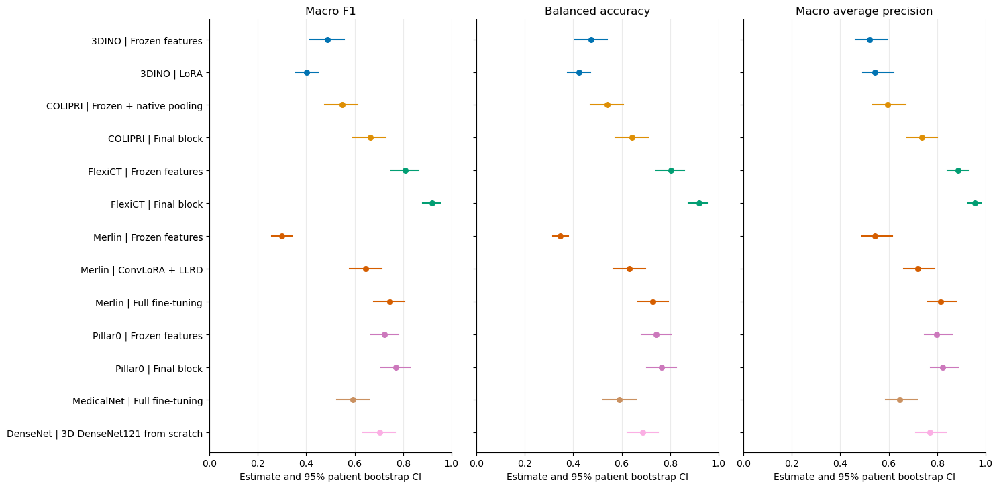

**Caption.** Full-development CV-ensemble performance on 278 matched held-out patients. Points and lines show estimates and 95% class-stratified patient-bootstrap intervals; rows follow configuration order.

In [17]:
fig = ph.intervals(main, ['f1_macro','balanced_accuracy','average_precision_macro'])
save_figure(fig, 'Figure_2_main_performance',
    f'Full-development CV-ensemble performance on {N_TEST} matched held-out patients. Points and lines show estimates and 95% class-stratified patient-bootstrap intervals; rows follow configuration order.', 'main')

## 11. Data efficiency: Figures 3a and 3b
Figure 3a includes partial adaptation and frozen-encoder comparators, including the 3DINO linear probe.
Figure 3b compares full-network Merlin and MedicalNet fine-tuning with DenseNet trained from scratch.
The horizontal axis uses actual development counts. Points are observed ensemble estimates;
lines only connect observations. No smoothing, monotonic fit, extrapolation or confidence bands are
shown. Source-specific hyperparameters and identities remain in the provenance audit.

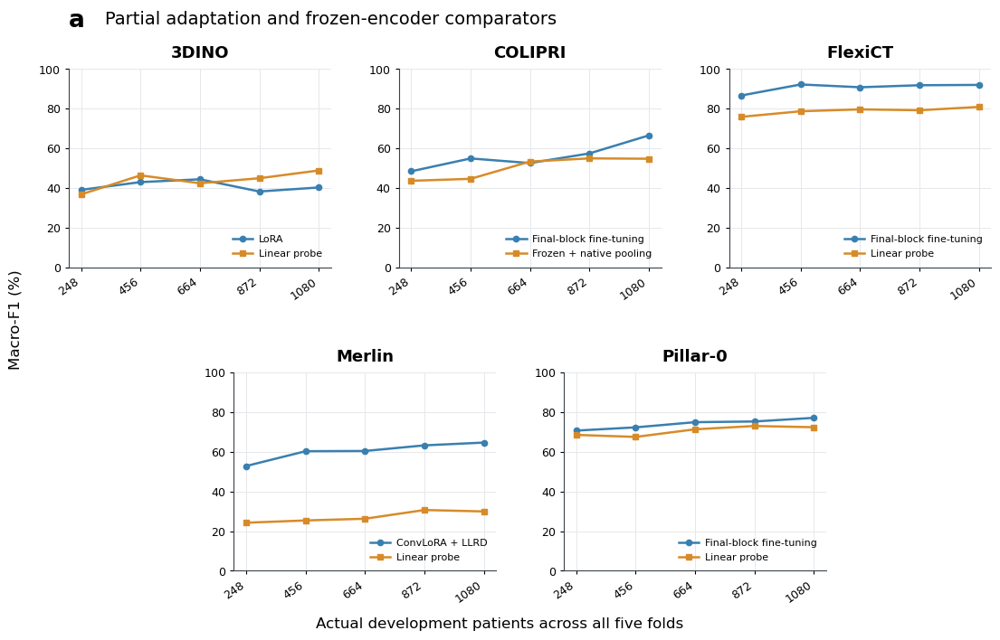

**Caption.** Figure 3a. Partial adaptation and frozen-encoder performance across development-set sizes. Macro-F1 is shown for 3DINO, COLIPRI, FlexiCT, Merlin, and Pillar-0 using five-fold CV ensembles at actual development-set sizes of 248, 456, 664, 872, and 1080 patients. Partial adaptation comprises 3DINO LoRA, final-block fine-tuning for COLIPRI, FlexiCT, and Pillar-0, and corrected Merlin ConvLoRA with layer-wise learning-rate decay (LLRD). Frozen-encoder comparators use linear probing, except COLIPRI, which uses its native pooling and classifier procedure. The completed 3DINO linear-probe results are included. Points are observed ensemble estimates, and lines connect them for readability; no monotonic model or extrapolation was fitted. The same 278-patient test cohort was used throughout. Perforation support in development remained 40 patients at every size, so both total sample size and class composition changed. Curves show point estimates without confidence bands. Full-network Merlin fine-tuning is reported separately in Figure 3b.

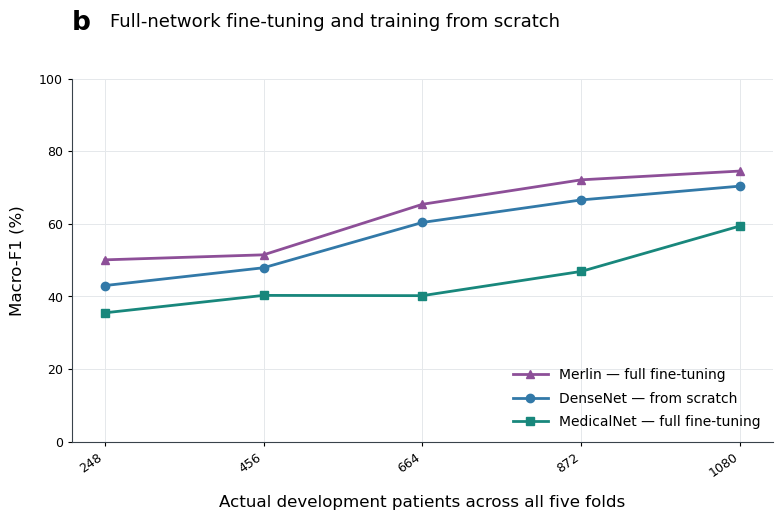

**Caption.** Figure 3b. Full-network fine-tuning and training from scratch across development-set sizes. Macro-F1 is compared for pretrained Merlin and MedicalNet with full-network fine-tuning and DenseNet trained from scratch, using five-fold CV ensembles at actual development-set sizes of 248, 456, 664, 872, and 1080 patients. The Merlin curve is the retrospective publication-derived full-network addition (FullFineTune CV_2). Points are observed ensemble estimates, and lines connect them for readability; no monotonic model or extrapolation was fitted. The same 278-patient test cohort was used throughout. Perforation support in development remained 40 patients at every size, so both total sample size and class composition changed. Curves show point estimates without confidence bands. These are comparisons of complete model-specific training recipes, not an isolated test of architecture or pretraining.

In [18]:
figure3_data=ensembles.copy()
figure3_data['development_n']=figure3_data.percentage.map(DEVELOPMENT_COUNTS)
figure3_data['macro_f1_percent']=100*figure3_data.f1_macro
assert len(figure3_data)==65
save_table(figure3_data[['model','method','percentage','development_n','f1_macro','cv_id','run_id']],
    'Figure_3_source_data','Exact Figure 3 values and provenance.','audit')
def save_figure3_variants(fig,stem,caption):
    variants=[('.png',300,{}),('_600dpi.png',600,{}),('.pdf',300,{}),('.svg',300,{}),
        ('.jpg',300,{'pil_kwargs':{'quality':95,'subsampling':0}}),
        ('.tiff',600,{'pil_kwargs':{'compression':'tiff_lzw'}})]
    for suffix,dpi,kwargs in variants:
        path=EXPORT_ROOT/'main/figures'/(stem+'_4'+suffix)
        fig.savefig(path,dpi=dpi,facecolor='white',**kwargs)
        record_artifact(path,caption)
    plt.show();plt.close(fig)
    display(Markdown('**Caption.** '+caption))
save_figure3_variants(ph.draw_a(figure3_data),'Figure_3a_partial_adaptation_and_linear_probes',ph.CAPTIONS['Figure_3a'])
save_figure3_variants(ph.draw_b(figure3_data),'Figure_3b_full_network_comparison',ph.CAPTIONS['Figure_3b'])
caption_path=EXPORT_ROOT/'Figure_3_captions_4.txt'
caption_path.write_text('\n\n'.join(ph.CAPTIONS.values()),encoding='utf-8')
record_artifact(caption_path,'Updated individual and combined captions for Figure 3a/b.')

### Supplementary learning endpoints
Balanced accuracy emphasizes equal class recall; average precision summarizes ranking at the observed
test prevalence. These complement the macro-F1 learning curves.

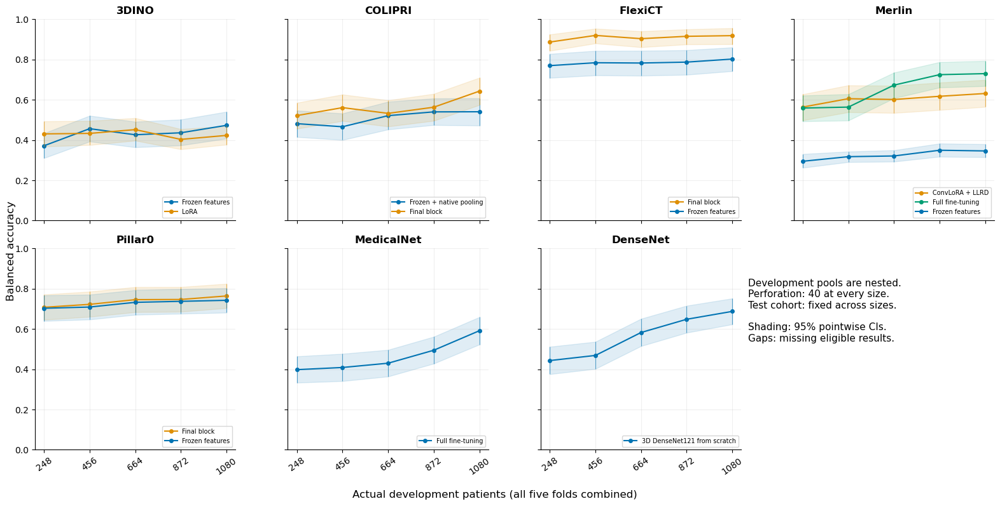

**Caption.** Balanced accuracy across nested development pools; same fixed test cohort, pointwise 95% patient-bootstrap intervals.

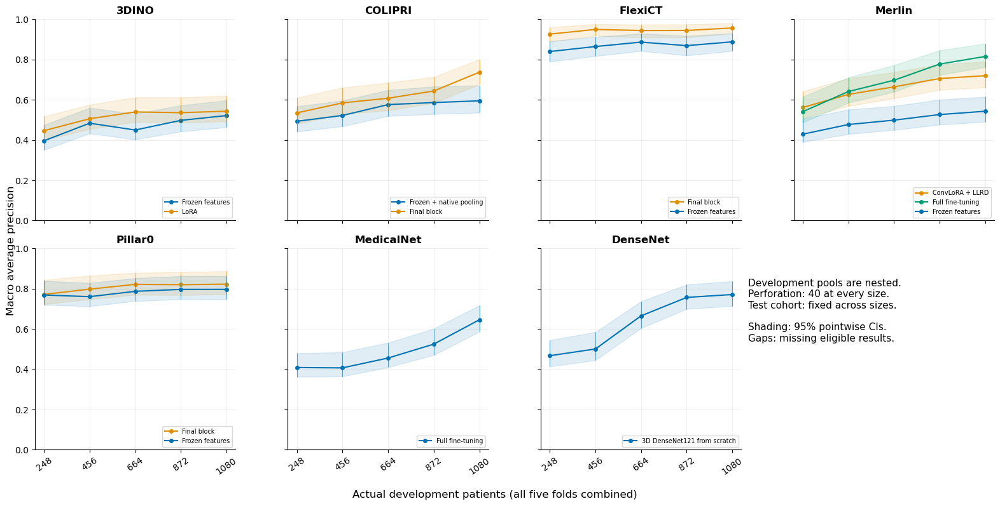

**Caption.** Macro average precision across nested development pools; same fixed test cohort, pointwise 95% patient-bootstrap intervals.

In [19]:
for metric, number in [('balanced_accuracy','S1'), ('average_precision_macro','S2')]:
    fig = ph.learning_panels(ensembles, metric, DEVELOPMENT_COUNTS)
    save_figure(fig, f'Figure_{number}_learning_{metric}',
        f'{ah.METRIC_LABELS[metric]} across nested development pools; same fixed test cohort, pointwise 95% patient-bootstrap intervals.')

### Reduced-data differences and area under the learning curve
Within-method differences use paired resamples against that method's 100% result. AULC is the trapezoidal
integral of macro-F1 over **actual development counts**, divided by the count span. It is calculated only
when all five sizes exist; missing curves are not interpolated. These are descriptive data-efficiency
summaries, not noninferiority tests or estimates of the minimum clinically sufficient sample size.

In [20]:
retention_rows, aulc_rows = [], []
for (model, method), group in ensembles.groupby(['model','method']):
    group = group.set_index('percentage')
    if 100 not in group.index:
        continue
    reference = group.loc[100]
    for pct, run in group.iterrows():
        if pct == 100:
            continue
        delta = bootstrap[run.run_id]['f1_macro'] - bootstrap[reference.run_id]['f1_macro']
        lo, hi = np.quantile(delta, [.025,.975])
        retention_rows.append({'model':model,'method':method,'percentage':pct,
            'development_n':DEVELOPMENT_COUNTS[pct], 'difference_vs_100':run.f1_macro-reference.f1_macro,
            'ci_low':lo,'ci_high':hi,'fraction_of_100_f1':run.f1_macro/reference.f1_macro if reference.f1_macro else np.nan})
    if set(group.index) == set(ah.PERCENTAGES) and group.source_family.nunique() == 1:
        ordered = group.loc[ah.PERCENTAGES]
        x = np.array(list(DEVELOPMENT_COUNTS.values()), dtype=float)
        dx = np.diff(x) / (x[-1]-x[0])
        samples = np.stack([bootstrap[r]['f1_macro'] for r in ordered.run_id])
        values = np.sum((samples[:-1]+samples[1:]) / 2 * dx[:,None], axis=0)
        estimate = np.sum((ordered.f1_macro.to_numpy()[:-1]+ordered.f1_macro.to_numpy()[1:])/2*dx)
        lo, hi = np.quantile(values,[.025,.975])
        aulc_rows.append({'model':model,'method':method,'normalized_macro_f1_aulc':estimate,'ci_low':lo,'ci_high':hi})
save_table(pd.DataFrame(retention_rows), 'Table_S2_reduced_data_differences', 'Paired macro-F1 differences versus each method at 100% development.')
display(save_table(pd.DataFrame(aulc_rows), 'Table_S3_learning_curve_area', 'Normalized macro-F1 AULC over actual development counts; complete five-size curves only.'))

,model,method,normalized_macro_f1_aulc,ci_low,ci_high
0,3DINO,LinearProbe,0.441482,0.383641,0.495988
1,3DINO,LoRA,0.413381,0.363645,0.462475
2,COLIPRI,PoolingOptimisedLinearProbe,0.505447,0.452378,0.555749
3,COLIPRI,PrimusMFinalBlockFineTune,0.556188,0.499431,0.608808
4,DenseNet,FromScratch,0.579084,0.523616,0.631482
5,FlexiCT,FinalBlockFineTune,0.910638,0.876339,0.940771
6,FlexiCT,LinearProbe,0.790107,0.737047,0.838591
7,MedicalNet,FullFineTune,0.437285,0.391261,0.482893
8,Merlin,ConvLoRA_LLRD,0.606630,0.549469,0.661285
9,Merlin,FullFineTune,0.628378,0.580471,0.673106


## 12. Paired method comparisons
### Calculate differences before hypothesis tests
Each pair uses the exact same patients and bootstrap draws. Positive differences favor method A.
The direction and membership of each pair come from the configuration, never from the observed scores.

In [21]:
paired_rows, paired_samples = [], {}
for pair_index, (ma, ta, mb, tb, family) in enumerate(PAIR_PLAN):
    a = main[(main.model==ma)&(main.method==ta)]
    b = main[(main.model==mb)&(main.method==tb)]
    label = f'{ma} {ah.METHOD_LABELS[ta]} − {mb} {ah.METHOD_LABELS[tb]}'
    row = {'pair_index':pair_index,'comparison':label,'family':family,'status':'pending',
           'model_a':ma,'method_a':ta,'model_b':mb,'method_b':tb}
    if len(a)==1 and len(b)==1:
        a,b = a.iloc[0],b.iloc[0]
        delta = bootstrap[a.run_id]['f1_macro']-bootstrap[b.run_id]['f1_macro']
        lo,hi = np.quantile(delta,[.025,.975])
        row.update(status='available',run_a=a.run_id,run_b=b.run_id,
                   difference=a.f1_macro-b.f1_macro,ci_low=lo,ci_high=hi)
        paired_samples[pair_index] = delta
    paired_rows.append(row)
paired = pd.DataFrame(paired_rows)
display(paired[['comparison','status']])

,comparison,status
0,3DINO Frozen features − DenseNet 3D DenseNet121 from scratch,available
1,3DINO LoRA − 3DINO Frozen features,available
2,3DINO LoRA − DenseNet 3D DenseNet121 from scratch,available
3,COLIPRI Frozen + native pooling − DenseNet 3D DenseNet121 from scratch,available
4,COLIPRI Final block − COLIPRI Frozen + native pooling,available
5,COLIPRI Final block − DenseNet 3D DenseNet121 from scratch,available
6,FlexiCT Frozen features − DenseNet 3D DenseNet121 from scratch,available
7,FlexiCT Final block − FlexiCT Frozen features,available
8,FlexiCT Final block − DenseNet 3D DenseNet121 from scratch,available
9,Merlin Frozen features − DenseNet 3D DenseNet121 from scratch,available


### Permutation tests and multiplicity
Macro-F1 uses 10,000 paired permutations. Exact McNemar tests describe discordant correctness as a
supporting analysis; they do not test macro-F1. Both sets of P values receive Holm adjustment over the
full planned family. Unadjusted confidence intervals remain effect-size summaries. No bootstrap
sign proportion is mislabeled as a P value or a posterior probability of superiority.

In [22]:
for idx, row in paired[paired.status=='available'].iterrows():
    tests = ah.paired_test(y_true, predictions[row.run_a][1], predictions[row.run_b][1],
                           PERMUTATION_REPLICATES, SEED + int(row.pair_index))
    for name,value in tests.items():
        paired.loc[idx,name] = value
available_mask = paired.status=='available'
for name in ['permutation_p','mcnemar_p']:
    if name in paired:
        paired.loc[available_mask,name+'_holm'] = ah.holm(paired.loc[available_mask,name], len(PAIR_PLAN))
save_table(paired, 'Table_S4_paired_comparisons',
    'Exploratory paired differences and two-sided tests at 100% development. Holm family includes every planned comparison, including pending pairs.')
display(paired[available_mask])

,pair_index,comparison,family,status,model_a,method_a,model_b,method_b,run_a,run_b,difference,ci_low,ci_high,permutation_p,mcnemar_p,a_only_correct,b_only_correct,both_wrong,both_correct,permutation_p_holm,mcnemar_p_holm
0,0,3DINO Frozen features − DenseNet 3D DenseNet121 from scratch,foundation_vs_scratch,available,3DINO,LinearProbe,DenseNet,FromScratch,3DINO/LinearProbe/Test/CV_1/cv_ensemble/100_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/100_percent,-0.215482,-0.302142,-0.129640,0.000100,1.617953e-09,22.0,83.0,49.0,124.0,0.001900,2.750520e-08
1,1,3DINO LoRA − 3DINO Frozen features,within_model_adaptation,available,3DINO,LoRA,3DINO,LinearProbe,3DINO/LoRA/Test/CV_1/cv_ensemble/100_percent,3DINO/LinearProbe/Test/CV_1/cv_ensemble/100_percent,-0.085863,-0.154091,-0.014354,0.065893,6.201448e-01,35.0,30.0,97.0,116.0,0.395360,1.000000e+00
2,2,3DINO LoRA − DenseNet 3D DenseNet121 from scratch,adapted_foundation_vs_scratch,available,3DINO,LoRA,DenseNet,FromScratch,3DINO/LoRA/Test/CV_1/cv_ensemble/100_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/100_percent,-0.301345,-0.372150,-0.225492,0.000100,4.818144e-09,19.0,75.0,52.0,132.0,0.001900,7.709031e-08
3,3,COLIPRI Frozen + native pooling − DenseNet 3D DenseNet121 from scratch,foundation_vs_scratch,available,COLIPRI,PoolingOptimisedLinearProbe,DenseNet,FromScratch,COLIPRI/PoolingOptimisedLinearProbe/Test/CV_1/cv_ensemble/100_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/100_percent,-0.156300,-0.229378,-0.080369,0.000100,1.462982e-07,22.0,73.0,49.0,134.0,0.001900,2.048175e-06
4,4,COLIPRI Final block − COLIPRI Frozen + native pooling,within_model_adaptation,available,COLIPRI,PrimusMFinalBlockFineTune,COLIPRI,PoolingOptimisedLinearProbe,COLIPRI/PrimusMFinalBlockFineTune/Test/CV_2/cv_ensemble/100_percent,COLIPRI/PoolingOptimisedLinearProbe/Test/CV_1/cv_ensemble/100_percent,0.117653,0.058341,0.174581,0.000200,1.206291e-04,55.0,21.0,67.0,135.0,0.002200,1.206291e-03
5,5,COLIPRI Final block − DenseNet 3D DenseNet121 from scratch,adapted_foundation_vs_scratch,available,COLIPRI,PrimusMFinalBlockFineTune,DenseNet,FromScratch,COLIPRI/PrimusMFinalBlockFineTune/Test/CV_2/cv_ensemble/100_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/100_percent,-0.038647,-0.105506,0.027283,0.257974,5.328936e-02,26.0,43.0,45.0,164.0,0.750725,3.197362e-01
6,6,FlexiCT Frozen features − DenseNet 3D DenseNet121 from scratch,foundation_vs_scratch,available,FlexiCT,LinearProbe,DenseNet,FromScratch,FlexiCT/LinearProbe/Test/CV_1/cv_ensemble/100_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/100_percent,0.105086,0.036637,0.176972,0.003700,3.367093e-04,46.0,17.0,25.0,190.0,0.033297,3.030384e-03
7,7,FlexiCT Final block − FlexiCT Frozen features,within_model_adaptation,available,FlexiCT,FinalBlockFineTune,FlexiCT,LinearProbe,FlexiCT/FinalBlockFineTune/Test/CV_1/cv_ensemble/100_percent,FlexiCT/LinearProbe/Test/CV_1/cv_ensemble/100_percent,0.110889,0.065067,0.160778,0.000100,5.947612e-05,26.0,4.0,16.0,232.0,0.001900,7.019457e-04
8,8,FlexiCT Final block − DenseNet 3D DenseNet121 from scratch,adapted_foundation_vs_scratch,available,FlexiCT,FinalBlockFineTune,DenseNet,FromScratch,FlexiCT/FinalBlockFineTune/Test/CV_1/cv_ensemble/100_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/100_percent,0.215974,0.152531,0.285667,0.000100,1.016749e-10,59.0,8.0,12.0,199.0,0.001900,1.830147e-09
9,9,Merlin Frozen features − DenseNet 3D DenseNet121 from scratch,foundation_vs_scratch,available,Merlin,LinearProbe,DenseNet,FromScratch,Merlin/LinearProbe/Test/CV_1/cv_ensemble/100_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/100_percent,-0.404925,-0.478054,-0.326487,0.000100,9.925612e-09,27.0,88.0,44.0,119.0,0.001900,1.488842e-07


### Figure 4. Adaptation effects
The figure includes available configured exploratory comparisons. All completed DenseNet contrasts are included.

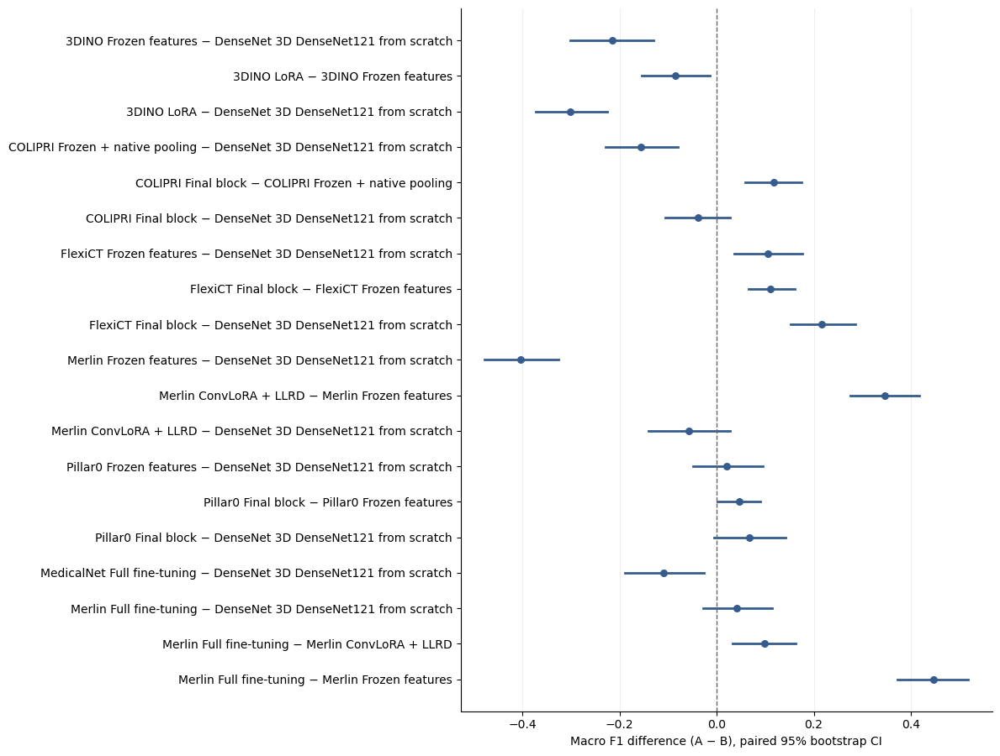

**Caption.** Macro-F1 differences (A minus B) for configured 100% CV-ensemble comparisons, with paired 95% patient-bootstrap intervals. Comparisons are exploratory; adjusted P values and pending pairs appear in Table S4.

In [23]:
fig = ph.difference_plot(paired[paired.status=='available'])
save_figure(fig, 'Figure_4_paired_effects',
    'Macro-F1 differences (A minus B) for configured 100% CV-ensemble comparisons, with paired 95% patient-bootstrap intervals. Comparisons are exploratory; adjusted P values and pending pairs appear in Table S4.', 'main')

### Supplementary paired effects at smaller development sizes
These matched-size comparisons extend the adaptation and CNN contrasts across the learning curves.
They report paired effect estimates and intervals without adding a large family of hypothesis tests.
Unavailable combinations remain pending; no interpolation or substitution of refit predictions occurs.

In [24]:
size_pair_rows = []
for pct in [20,40,60,80]:
    subset = ensembles[ensembles.percentage==pct]
    for ma,ta,mb,tb,family in PAIR_PLAN:
        a = subset[(subset.model==ma)&(subset.method==ta)]
        b = subset[(subset.model==mb)&(subset.method==tb)]
        row = {'percentage':pct,'development_n':DEVELOPMENT_COUNTS[pct],
               'model_a':ma,'method_a':ta,'model_b':mb,'method_b':tb,'status':'pending'}
        if len(a)==1 and len(b)==1:
            a,b = a.iloc[0],b.iloc[0]
            delta = bootstrap[a.run_id]['f1_macro']-bootstrap[b.run_id]['f1_macro']
            lo,hi = np.quantile(delta,[.025,.975])
            row.update(status='available',run_a=a.run_id,run_b=b.run_id,
                       difference=a.f1_macro-b.f1_macro,ci_low=lo,ci_high=hi)
        size_pair_rows.append(row)
save_table(pd.DataFrame(size_pair_rows),'Table_S15_paired_effects_by_size',
    'Exploratory paired macro-F1 differences at matched reduced development sizes; 95% intervals and explicit pending combinations.');

### Tables S16–S17. Full-network Merlin and 3DINO probe comparisons
Matched fractions and checkpoint routes are compared using the same patient resamples. These are
comparisons of complete selected pipelines, whose native hyperparameters can differ. Pointwise
intervals are descriptive; the 100% ensemble macro-F1 tests are part of Table S4's 19-test family.

In [25]:
def all_route_contrast(ma,ta,mb,tb):
    rows=[]
    for pct in ah.PERCENTAGES:
        for route in ah.SOURCES:
            q=chosen_results[(chosen_results.percentage==pct)&(chosen_results.source==route)]
            a=q[(q.model==ma)&(q.method==ta)];b=q[(q.model==mb)&(q.method==tb)]
            assert len(a)==1 and len(b)==1
            a,b=a.iloc[0],b.iloc[0]
            for metric in ['f1_macro','accuracy','balanced_accuracy']:
                lo,hi=np.quantile(bootstrap[a.run_id][metric]-bootstrap[b.run_id][metric],[.025,.975])
                rows.append(dict(percentage=pct,development_n=DEVELOPMENT_COUNTS[pct],source=route,
                    model_a=ma,method_a=ta,model_b=mb,method_b=tb,metric=metric,
                    estimate_a=a[metric],estimate_b=b[metric],difference=a[metric]-b[metric],
                    ci_low=lo,ci_high=hi,run_a=a.run_id,run_b=b.run_id))
    return pd.DataFrame(rows)
full_network_comparison=all_route_contrast('Merlin','FullFineTune','DenseNet','FromScratch')
probe_comparison=all_route_contrast('3DINO','LinearProbe','3DINO','LoRA')
display(save_table(full_network_comparison,'Table_S16_Merlin_full_network_vs_DenseNet',
    'Merlin full fine-tuning versus DenseNet from scratch at every matched size and route; paired 95% pointwise intervals.'))
display(save_table(probe_comparison,'Table_S17_3DINO_linear_probe_vs_LoRA',
    '3DINO linear probing versus LoRA at every matched size and route; paired 95% pointwise intervals.'))

,percentage,development_n,source,model_a,method_a,model_b,method_b,metric,estimate_a,estimate_b,difference,ci_low,ci_high,run_a,run_b
0,20,248,cv_ensemble,Merlin,FullFineTune,DenseNet,FromScratch,f1_macro,0.500938,0.430086,0.070852,-0.005490,0.147587,Merlin/FullFineTune/Test/CV_2/cv_ensemble/20_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/20_percent
1,20,248,cv_ensemble,Merlin,FullFineTune,DenseNet,FromScratch,accuracy,0.539568,0.482014,0.057554,-0.010791,0.125989,Merlin/FullFineTune/Test/CV_2/cv_ensemble/20_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/20_percent
2,20,248,cv_ensemble,Merlin,FullFineTune,DenseNet,FromScratch,balanced_accuracy,0.559004,0.443122,0.115882,0.030983,0.199002,Merlin/FullFineTune/Test/CV_2/cv_ensemble/20_percent,DenseNet/FromScratch/Test/CV_1/cv_ensemble/20_percent
3,20,248,best_cv_fold,Merlin,FullFineTune,DenseNet,FromScratch,f1_macro,0.477397,0.407294,0.070103,-0.011790,0.151565,Merlin/FullFineTune/Test/CV_2/best_cv_fold/20_percent,DenseNet/FromScratch/Test/CV_1/best_cv_fold/20_percent
4,20,248,best_cv_fold,Merlin,FullFineTune,DenseNet,FromScratch,accuracy,0.510791,0.453237,0.057554,-0.010791,0.125899,Merlin/FullFineTune/Test/CV_2/best_cv_fold/20_percent,DenseNet/FromScratch/Test/CV_1/best_cv_fold/20_percent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,100,1080,best_cv_fold,Merlin,FullFineTune,DenseNet,FromScratch,accuracy,0.701439,0.701439,0.000000,-0.061151,0.061151,Merlin/FullFineTune/Test/CV_2/best_cv_fold/100_percent,DenseNet/FromScratch/Test/CV_1/best_cv_fold/100_percent
41,100,1080,best_cv_fold,Merlin,FullFineTune,DenseNet,FromScratch,balanced_accuracy,0.682873,0.640463,0.042411,-0.036714,0.121819,Merlin/FullFineTune/Test/CV_2/best_cv_fold/100_percent,DenseNet/FromScratch/Test/CV_1/best_cv_fold/100_percent
42,100,1080,refit_full_development,Merlin,FullFineTune,DenseNet,FromScratch,f1_macro,0.728064,0.429721,0.298343,0.222778,0.370474,Merlin/FullFineTune/Test/CV_2/refit_full_development/100_percent,DenseNet/FromScratch/Test/CV_1/refit_full_development/100_percent
43,100,1080,refit_full_development,Merlin,FullFineTune,DenseNet,FromScratch,accuracy,0.741007,0.535971,0.205036,0.140288,0.269784,Merlin/FullFineTune/Test/CV_2/refit_full_development/100_percent,DenseNet/FromScratch/Test/CV_1/refit_full_development/100_percent


,percentage,development_n,source,model_a,method_a,model_b,method_b,metric,estimate_a,estimate_b,difference,ci_low,ci_high,run_a,run_b
0,20,248,cv_ensemble,3DINO,LinearProbe,3DINO,LoRA,f1_macro,0.368132,0.390882,-0.022750,-0.088657,0.038920,3DINO/LinearProbe/Test/CV_5/cv_ensemble/20_percent,3DINO/LoRA/Test/CV_1/cv_ensemble/20_percent
1,20,248,cv_ensemble,3DINO,LinearProbe,3DINO,LoRA,accuracy,0.438849,0.474820,-0.035971,-0.093525,0.021583,3DINO/LinearProbe/Test/CV_5/cv_ensemble/20_percent,3DINO/LoRA/Test/CV_1/cv_ensemble/20_percent
2,20,248,cv_ensemble,3DINO,LinearProbe,3DINO,LoRA,balanced_accuracy,0.371666,0.430688,-0.059022,-0.121970,0.001311,3DINO/LinearProbe/Test/CV_5/cv_ensemble/20_percent,3DINO/LoRA/Test/CV_1/cv_ensemble/20_percent
3,20,248,best_cv_fold,3DINO,LinearProbe,3DINO,LoRA,f1_macro,0.327403,0.394347,-0.066944,-0.131909,-0.003647,3DINO/LinearProbe/Test/CV_5/best_cv_fold/20_percent,3DINO/LoRA/Test/CV_1/best_cv_fold/20_percent
4,20,248,best_cv_fold,3DINO,LinearProbe,3DINO,LoRA,accuracy,0.420863,0.489209,-0.068345,-0.125899,-0.010791,3DINO/LinearProbe/Test/CV_5/best_cv_fold/20_percent,3DINO/LoRA/Test/CV_1/best_cv_fold/20_percent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,100,1080,best_cv_fold,3DINO,LinearProbe,3DINO,LoRA,accuracy,0.478417,0.539568,-0.061151,-0.118705,-0.007194,3DINO/LinearProbe/Test/CV_1/best_cv_fold/100_percent,3DINO/LoRA/Test/CV_1/best_cv_fold/100_percent
41,100,1080,best_cv_fold,3DINO,LinearProbe,3DINO,LoRA,balanced_accuracy,0.413363,0.420510,-0.007147,-0.070333,0.055796,3DINO/LinearProbe/Test/CV_1/best_cv_fold/100_percent,3DINO/LoRA/Test/CV_1/best_cv_fold/100_percent
42,100,1080,refit_full_development,3DINO,LinearProbe,3DINO,LoRA,f1_macro,0.477785,0.383584,0.094201,0.019441,0.163279,3DINO/LinearProbe/Test/CV_1/refit_full_development/100_percent,3DINO/LoRA/Test/CV_1/refit_full_development/100_percent
43,100,1080,refit_full_development,3DINO,LinearProbe,3DINO,LoRA,accuracy,0.521583,0.521583,0.000000,-0.057554,0.057554,3DINO/LinearProbe/Test/CV_1/refit_full_development/100_percent,3DINO/LoRA/Test/CV_1/refit_full_development/100_percent


## 13. Class-specific performance
### Table 4. Class sensitivity with uncertainty
The compact main table gives one row per method and one sensitivity column per class; full diagnostic
metrics and denominators are retained in Table S5.
Sensitivity, specificity and precision receive Wilson 95% intervals. Perforation sensitivity also has
an exact binomial interval in the numeric supplement. Every denominator is exported. F1, class AP and
class AUROC are point estimates here and are not presented with binomial intervals.

In [26]:
main_class = class_results[class_results.run_id.isin(main.run_id)].copy()
main_class['Sensitivity (95% CI)'] = main_class.apply(lambda r:
    f'{r.sensitivity:.3f} ({r.sensitivity_low:.3f}, {r.sensitivity_high:.3f})', axis=1)
table4 = main_class.pivot(index=['model','method'],columns='display_class',values='Sensitivity (95% CI)').reindex(columns=ah.DISPLAY_CLASSES).reset_index()
table4 = table4.set_index(['model','method']).reindex(pd.MultiIndex.from_frame(main[['model','method']])).reset_index()
table4['method'] = table4.method.map(ah.METHOD_LABELS)
table4['model'] = table4.model.replace({'Pillar0':'Pillar-0'})
table4 = table4.rename(columns={'model':'Model','method':'Method'})
display(save_table(table4, 'Table_4_class_performance',
    'Class sensitivities with Wilson 95% intervals for 100% CV ensembles. Supports: Appendicitis 47, Cholecystitis 37, Normal 90, Perforation 18, Sigmoid 86. Table S5 supplies specificity, precision, F1, AP, AUROC and all confusion-count denominators.', 'main'))
save_table(class_results, 'Table_S5_all_class_metrics', 'All valid runs: class metrics, counts, Wilson intervals and exact Perforation sensitivity intervals.');

display_class,Model,Method,Appendicitis,Cholecystitis,Normal,Perforation,Sigmoid
0,3DINO,Frozen features,"0.277 (0.169, 0.418)","0.541 (0.384, 0.690)","0.622 (0.519, 0.715)","0.333 (0.163, 0.563)","0.593 (0.487, 0.691)"
1,3DINO,LoRA,"0.149 (0.074, 0.277)","0.568 (0.409, 0.713)","0.667 (0.564, 0.755)","0.000 (0.000, 0.176)","0.733 (0.631, 0.815)"
2,COLIPRI,Frozen + native pooling,"0.468 (0.333, 0.608)","0.622 (0.461, 0.759)","0.622 (0.519, 0.715)","0.444 (0.246, 0.663)","0.547 (0.442, 0.647)"
3,COLIPRI,Final block,"0.532 (0.392, 0.667)","0.703 (0.542, 0.825)","0.689 (0.587, 0.775)","0.500 (0.290, 0.710)","0.791 (0.693, 0.863)"
4,FlexiCT,Frozen features,"0.809 (0.675, 0.896)","0.730 (0.570, 0.846)","0.911 (0.834, 0.954)","0.667 (0.437, 0.837)","0.895 (0.813, 0.944)"
5,FlexiCT,Final block,"0.936 (0.828, 0.978)","0.892 (0.753, 0.957)","0.911 (0.834, 0.954)","0.889 (0.672, 0.969)","0.965 (0.902, 0.988)"
6,Merlin,Frozen features,"0.021 (0.004, 0.111)","0.108 (0.043, 0.247)","0.833 (0.743, 0.896)","0.000 (0.000, 0.176)","0.767 (0.668, 0.844)"
7,Merlin,ConvLoRA + LLRD,"0.553 (0.412, 0.686)","0.568 (0.409, 0.713)","0.733 (0.634, 0.814)","0.500 (0.290, 0.710)","0.802 (0.706, 0.873)"
8,Merlin,Full fine-tuning,"0.723 (0.582, 0.831)","0.811 (0.658, 0.905)","0.822 (0.731, 0.888)","0.444 (0.246, 0.663)","0.849 (0.758, 0.909)"
9,Pillar-0,Frozen features,"0.660 (0.517, 0.778)","0.838 (0.689, 0.923)","0.722 (0.622, 0.804)","0.667 (0.437, 0.837)","0.826 (0.732, 0.891)"


### Figure 5. Class sensitivity and average precision
The two panels distinguish correct classification from probability ranking. Perforation estimates
are based on 18 test patients; see Table 4 for uncertainty rather than interpreting color alone.

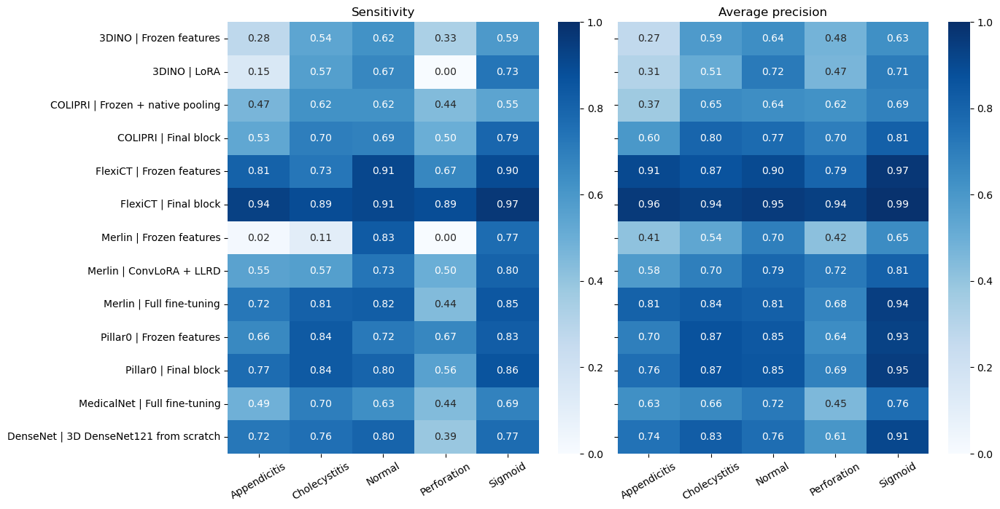

**Caption.** Sensitivity and class average precision for full-development CV ensembles. Class supports: Appendicitis n=47, Cholecystitis n=37, Normal n=90, Perforation n=18, Sigmoid n=86. See Table 4 for sensitivity intervals.

In [27]:
fig, axes = plt.subplots(1,2,figsize=(14,max(4,len(main)*.43+1.5)))
for ax, metric, title in zip(axes, ['sensitivity','average_precision'], ['Sensitivity','Average precision']):
    heat = main_class.pivot(index='label',columns='display_class',values=metric).reindex(index=main.label,columns=ah.DISPLAY_CLASSES)
    if heat.empty:
        ph.empty_panel(ax)
    else:
        sns.heatmap(heat,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',ax=ax,cbar=True)
    ax.set_title(title);ax.set_xlabel('');ax.set_ylabel('');ax.tick_params(axis='x',rotation=30)
axes[1].set_yticklabels([])
fig.tight_layout()
save_figure(fig, 'Figure_5_class_performance',
    'Sensitivity and class average precision for full-development CV ensembles. Class supports: '+
    ', '.join(f'{c} n={int((y_true==i).sum())}' for i,c in enumerate(ah.DISPLAY_CLASSES))+'. See Table 4 for sensitivity intervals.', 'main')

### Supplementary confusion matrices
Counts preserve denominators. Row normalization answers which predicted class each reference class
was assigned to. All available main-analysis methods are shown, not only the best-performing method.

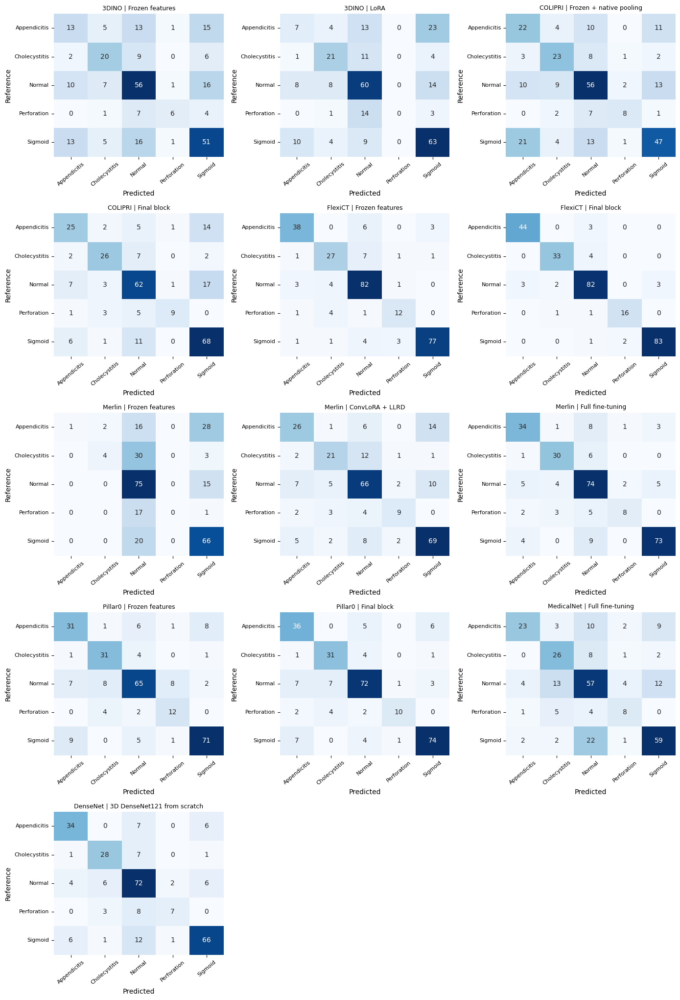

**Caption.** Full-development CV-ensemble confusion matrices (counts); rows are reference classes, columns predicted classes.

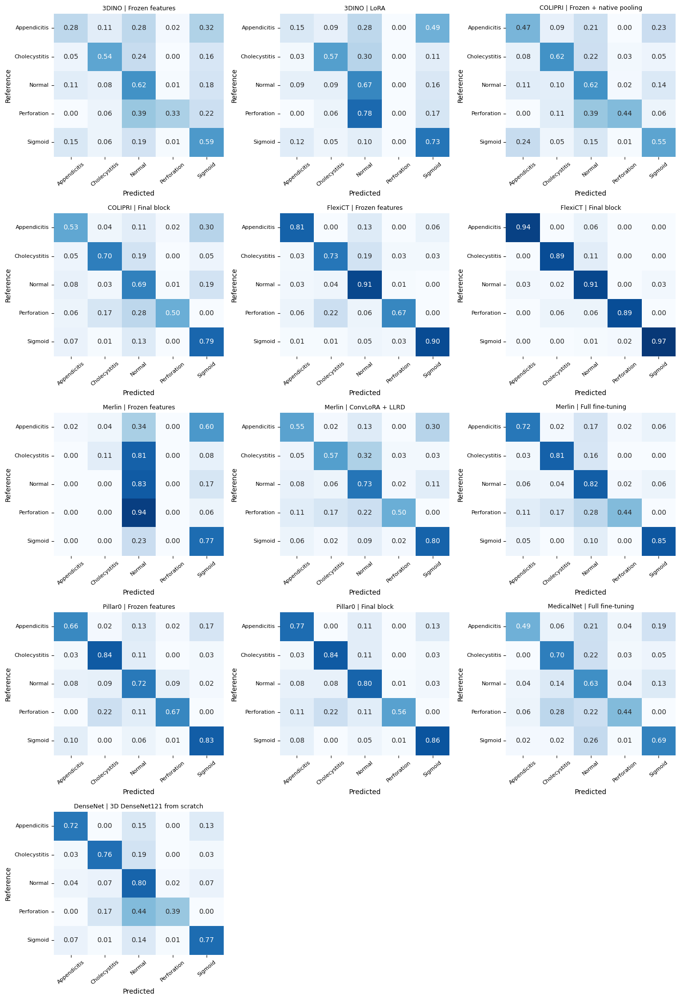

**Caption.** Full-development CV-ensemble confusion matrices (row normalized); rows are reference classes, columns predicted classes.

In [28]:
for normalized, suffix in [(False,'counts'), (True,'row_normalized')]:
    fig = ph.confusion_panels(main, matrices, normalize=normalized)
    save_figure(fig, f'Figure_S3_confusion_{suffix}',
        f'Full-development CV-ensemble confusion matrices ({suffix.replace("_"," ")}); rows are reference classes, columns predicted classes.')

### Supplementary precision–recall and ROC curves
These curves use one-versus-rest truth for the mutually exclusive five-class task. PR baselines equal
the class prevalence in this fixed cohort. Curve values and thresholds are exported for reproducibility.

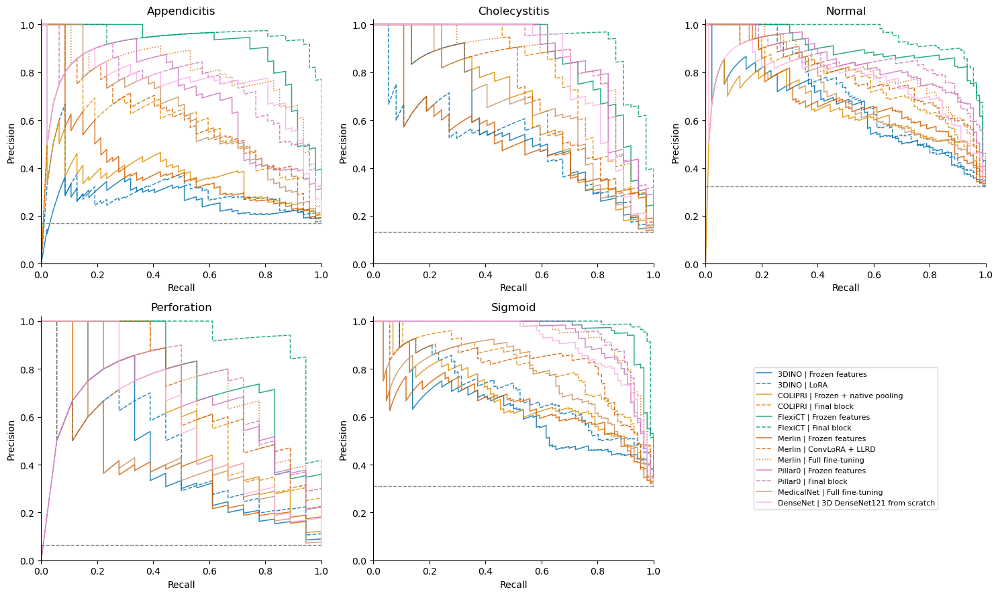

**Caption.** One-versus-rest PR curves for 100% CV ensembles; fixed patient cohort. Dashed lines show the relevant no-skill baseline.

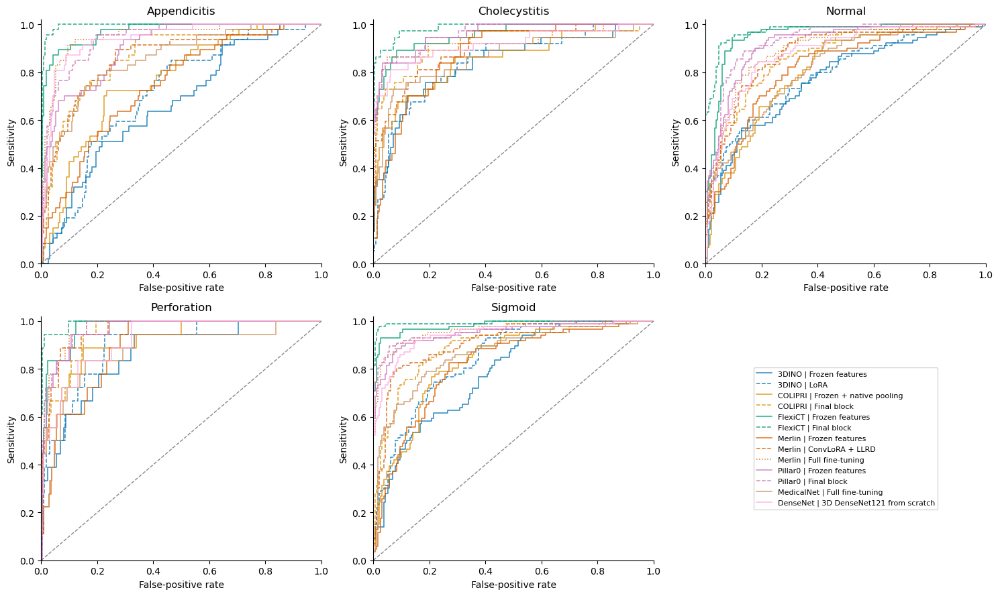

**Caption.** One-versus-rest ROC curves for 100% CV ensembles; fixed patient cohort. Dashed lines show the relevant no-skill baseline.

In [29]:
curve_rows = []
for kind in ['PR','ROC']:
    fig, axes = plt.subplots(2,3,figsize=(15,9))
    for k, ax in enumerate(list(axes.flat)[:5]):
        for run in main.itertuples():
            scores = predictions[run.run_id][0][:,k]
            if kind == 'PR':
                precision, recall, thresholds = precision_recall_curve(y_true==k, scores)
                x, yy = recall, precision
                thresholds = np.r_[thresholds, np.nan]
            else:
                x, yy, thresholds = roc_curve(y_true==k,scores)
            method_index = ah.METHODS[run.model].index(run.method)
            ax.plot(x, yy, label=run.label, lw=1.1, alpha=.85, color=ph.COLORS[run.model],
                    linestyle=['-','--',':','-.'][method_index % 4])
            curve_rows.extend({'run_id':run.run_id,'class':ah.CLASSES[k],'curve':kind,
                               'x':xx,'y':vv,'threshold':tt} for xx,vv,tt in zip(x,yy,thresholds))
        if kind == 'PR':
            ax.axhline((y_true==k).mean(),ls='--',color='#888',lw=1)
            ax.set(xlabel='Recall',ylabel='Precision')
        else:
            ax.plot([0,1],[0,1],ls='--',color='#888',lw=1)
            ax.set(xlabel='False-positive rate',ylabel='Sensitivity')
        ax.set_title(ah.DISPLAY_CLASSES[k]);ax.set_xlim(0,1);ax.set_ylim(0,1.02)
    axes.flat[-1].axis('off')
    handles,labels = axes.flat[0].get_legend_handles_labels()
    axes.flat[-1].legend(handles,labels,loc='center',fontsize=8)
    fig.tight_layout()
    save_figure(fig,f'Figure_S4_{kind}_curves',f'One-versus-rest {kind} curves for 100% CV ensembles; fixed patient cohort. Dashed lines show the relevant no-skill baseline.')
save_table(pd.DataFrame(curve_rows), 'curve_coordinates', 'Patient-probability-derived PR/ROC coordinates and thresholds.');

## 14. Calibration
Assess raw probabilities without fitting calibration on the held-out test set. Multiclass Brier score
is the mean **sum** of five squared errors (range 0–2); log loss uses natural logarithms and clips true-class
probabilities at 1e-15. Top-label ECE uses ten fixed equal-width confidence bins.
Calibration metrics depend on cohort prevalence and are not evidence of deployment readiness.

In [30]:
calibration_table = ah.formatted_table(main, ['brier_multiclass','log_loss','ece'])
display(save_table(calibration_table, 'Table_S6_calibration', 'Raw-probability calibration metrics with patient-bootstrap intervals; no test-set recalibration.'))
reliability_rows = []
for run in main.itertuples():
    bins = ah.reliability(y_true,predictions[run.run_id][0],CALIBRATION_BINS)
    bins['run_id'] = run.run_id
    reliability_rows.append(bins)
reliability_data = pd.concat(reliability_rows,ignore_index=True) if reliability_rows else pd.DataFrame()
save_table(reliability_data,'reliability_bins','Fixed-bin confidence, accuracy, support and Wilson accuracy intervals.');

,model,method,percentage,source,cv_id,source_family,integrity,n_test,Multiclass Brier score (95% CI),Log loss (95% CI),Top-label ECE (95% CI)
1,3DINO,LinearProbe,100,cv_ensemble,CV_1,publication,hash_seal_verified,278,"0.640 (0.578, 0.705)","1.306 (1.158, 1.462)","0.137 (0.098, 0.201)"
20,3DINO,LoRA,100,cv_ensemble,CV_1,default,hash_seal_verified,278,"0.579 (0.546, 0.613)","1.118 (1.056, 1.179)","0.069 (0.047, 0.127)"
33,COLIPRI,PoolingOptimisedLinearProbe,100,cv_ensemble,CV_1,publication,hash_seal_verified,278,"0.590 (0.525, 0.655)","1.172 (1.014, 1.336)","0.139 (0.099, 0.200)"
48,COLIPRI,PrimusMFinalBlockFineTune,100,cv_ensemble,CV_2,publication,hash_seal_verified,278,"0.455 (0.388, 0.523)","1.114 (0.878, 1.370)","0.106 (0.072, 0.161)"
91,FlexiCT,LinearProbe,100,cv_ensemble,CV_1,publication,hash_seal_verified,278,"0.235 (0.175, 0.299)","0.658 (0.442, 0.902)","0.074 (0.054, 0.119)"
76,FlexiCT,FinalBlockFineTune,100,cv_ensemble,CV_1,publication,hash_seal_verified,278,"0.132 (0.089, 0.182)","0.294 (0.186, 0.420)","0.044 (0.026, 0.076)"
150,Merlin,LinearProbe,100,cv_ensemble,CV_1,publication,legacy_unsealed_content_validated,278,"0.653 (0.638, 0.667)","1.265 (1.237, 1.292)","0.139 (0.102, 0.180)"
125,Merlin,ConvLoRA_LLRD,100,cv_ensemble,CV_2,publication,legacy_unsealed_content_validated,278,"0.438 (0.380, 0.495)","0.858 (0.736, 0.985)","0.061 (0.044, 0.118)"
140,Merlin,FullFineTune,100,cv_ensemble,CV_2,publication,legacy_unsealed_content_validated,278,"0.327 (0.278, 0.378)","0.654 (0.555, 0.758)","0.058 (0.041, 0.111)"
181,Pillar0,LinearProbe,100,cv_ensemble,CV_1,publication,legacy_unsealed_content_validated,278,"0.433 (0.400, 0.466)","0.874 (0.817, 0.931)","0.249 (0.208, 0.297)"


### Supplementary Figure S8. Reliability by model family
Bins with no observations are omitted. Small-bin estimates are uncertain; point size indicates bin
support, and exported bin tables include Wilson intervals. The diagonal denotes perfect top-label
calibration. Zero-shot relative scores are kept outside this main calibration analysis.

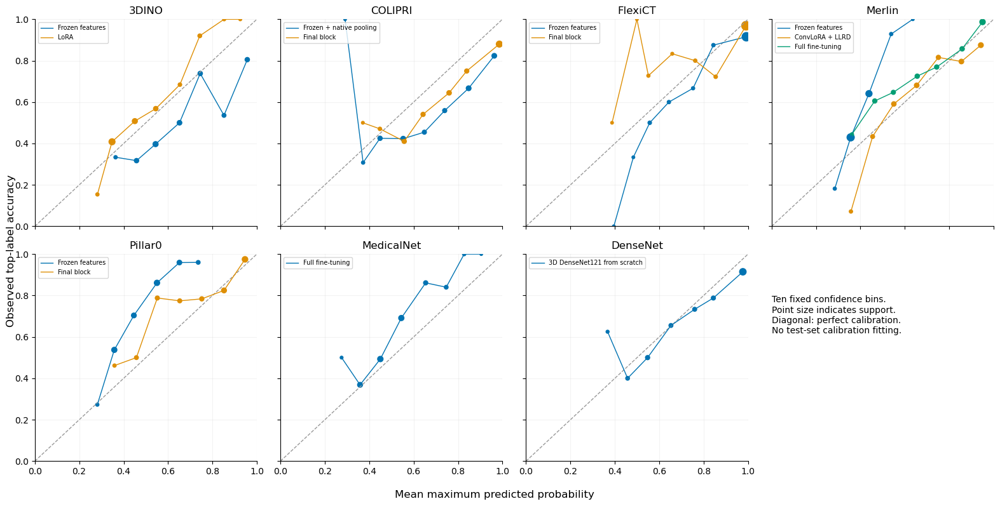

**Caption.** Top-label reliability diagrams for raw 100% CV-ensemble probabilities. Ten equal-width bins; marker area indicates support. Empty bins are omitted; bin uncertainty is supplied in the exported table.

In [31]:
fig, axes = plt.subplots(2,4,figsize=(16,8),sharex=True,sharey=True)
for ax, model in zip(axes.flat, ah.METHODS):
    group = main[main.model==model]
    ax.plot([0,1],[0,1],ls='--',color='#999',lw=1)
    if group.empty:
        ph.empty_panel(ax)
    for j, run in enumerate(group.itertuples()):
        data = reliability_data[(reliability_data.run_id==run.run_id)&(reliability_data.n>0)]
        color = ph.METHOD_COLORS[(model,run.method)]
        ax.plot(data.confidence,data.accuracy,label=ah.METHOD_LABELS[run.method],color=color,lw=1)
        ax.scatter(data.confidence,data.accuracy,s=10+data.n*.4,color=color)
    ax.set_title(model);ax.set_xlim(0,1);ax.set_ylim(0,1);ax.grid(alpha=.15)
    if not group.empty:
        ax.legend(fontsize=7,loc='upper left')
axes.flat[-1].axis('off')
axes.flat[-1].text(0,.8,'Ten fixed confidence bins.\nPoint size indicates support.\nDiagonal: perfect calibration.\nNo test-set calibration fitting.',va='top')
fig.supxlabel('Mean maximum predicted probability');fig.supylabel('Observed top-label accuracy')
fig.tight_layout()
save_figure(fig,'Figure_S8_reliability',
    'Top-label reliability diagrams for raw 100% CV-ensemble probabilities. Ten equal-width bins; marker area indicates support. Empty bins are omitted; bin uncertainty is supplied in the exported table.')

## 15. Error overlap and ranking uncertainty (exploratory)
Error overlap describes whether methods fail on the same patients. No cross-model ensemble is tuned
on test labels. Bootstrap rank frequencies describe sensitivity to resampling this cohort; they are not
posterior probabilities that a model is truly best.

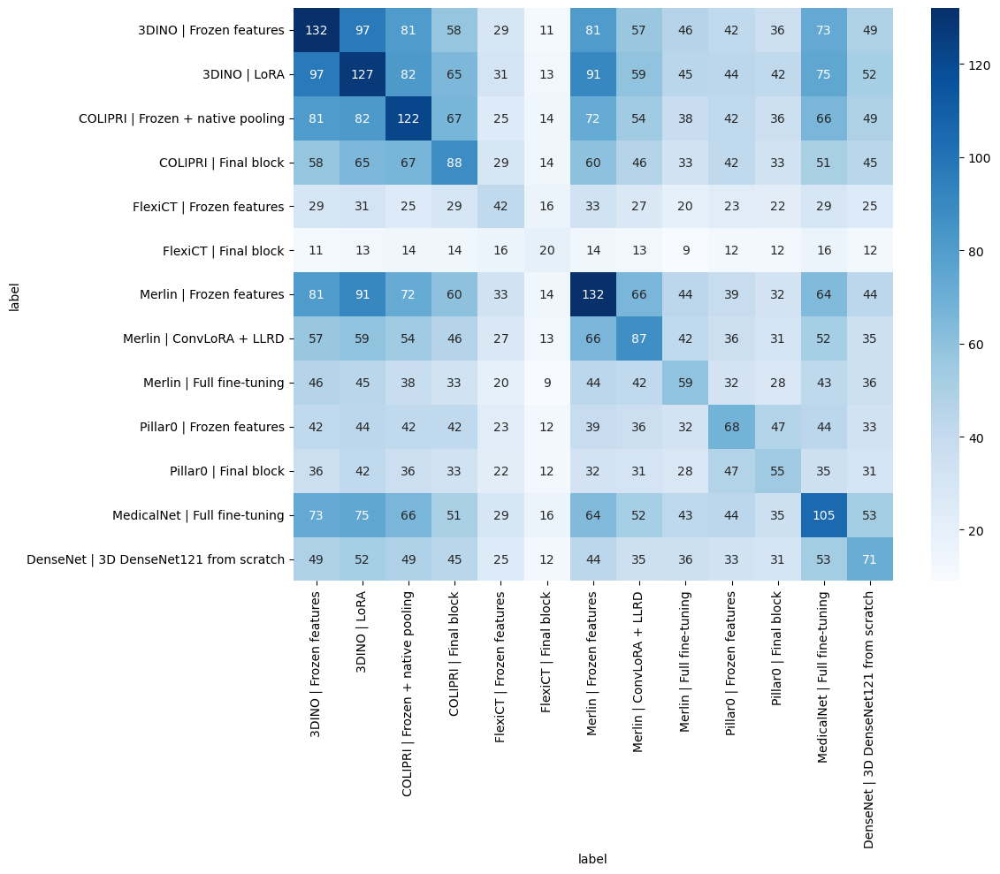

**Caption.** Pairwise overlap in misclassified patients at 100% development; diagonal entries are total errors per method.

In [32]:
overlap = np.zeros((len(main),len(main)),dtype=int)
for i,a in enumerate(main.itertuples()):
    for j,b in enumerate(main.itertuples()):
        overlap[i,j] = np.sum((predictions[a.run_id][1]!=y_true)&(predictions[b.run_id][1]!=y_true))
overlap_table = pd.DataFrame(overlap,index=main.label,columns=main.label)
save_table(overlap_table.rename_axis('model_method').reset_index(),'Table_S7_error_overlap',
           'Number of held-out patients misclassified by both methods; diagonal is each method error count.')
fig,ax = plt.subplots(figsize=(12,10))
if len(main):
    sns.heatmap(overlap_table,annot=True,fmt='d',cmap='Blues',ax=ax)
else:
    ph.empty_panel(ax)
fig.tight_layout()
save_figure(fig,'Figure_S5_error_overlap','Pairwise overlap in misclassified patients at 100% development; diagonal entries are total errors per method.')

In [33]:
rank_rows = []
if len(main):
    scores = np.stack([bootstrap[r]['f1_macro'] for r in main.run_id],axis=1)
    ranks = pd.DataFrame(scores).rank(axis=1,ascending=False,method='average').to_numpy()
    tied_best = np.isclose(scores,scores.max(1,keepdims=True),atol=1e-12,rtol=0)
    best_share = tied_best / tied_best.sum(1,keepdims=True)
    for j,run in enumerate(main.itertuples()):
        rank_rows.append({'run_id':run.run_id,'label':run.label,'median_bootstrap_rank':np.median(ranks[:,j]),
            'fractional_best_frequency':best_share[:,j].mean(),
            'within_0_02_of_best_frequency':(scores[:,j]>=scores.max(1)-.02).mean(),
            'comparison_set_n':len(main)})
display(save_table(pd.DataFrame(rank_rows),'Table_S8_rank_stability',
    'Descriptive cohort-bootstrap rank stability among the 13 included 100% ensemble methods; ties share best frequency.'))

,run_id,label,median_bootstrap_rank,fractional_best_frequency,within_0_02_of_best_frequency,comparison_set_n
0,3DINO/LinearProbe/Test/CV_1/cv_ensemble/100_percent,3DINO | Frozen features,11.0,0.0,0.0,13
1,3DINO/LoRA/Test/CV_1/cv_ensemble/100_percent,3DINO | LoRA,12.0,0.0,0.0,13
2,COLIPRI/PoolingOptimisedLinearProbe/Test/CV_1/cv_ensemble/100_percent,COLIPRI | Frozen + native pooling,10.0,0.0,0.0,13
3,COLIPRI/PrimusMFinalBlockFineTune/Test/CV_2/cv_ensemble/100_percent,COLIPRI | Final block,7.0,0.0,0.0,13
4,FlexiCT/LinearProbe/Test/CV_1/cv_ensemble/100_percent,FlexiCT | Frozen features,2.0,0.0,0.0,13
5,FlexiCT/FinalBlockFineTune/Test/CV_1/cv_ensemble/100_percent,FlexiCT | Final block,1.0,1.0,1.0,13
6,Merlin/LinearProbe/Test/CV_1/cv_ensemble/100_percent,Merlin | Frozen features,13.0,0.0,0.0,13
7,Merlin/ConvLoRA_LLRD/Test/CV_2/cv_ensemble/100_percent,Merlin | ConvLoRA + LLRD,8.0,0.0,0.0,13
8,Merlin/FullFineTune/Test/CV_2/cv_ensemble/100_percent,Merlin | Full fine-tuning,4.0,0.0,0.0,13
9,Pillar0/LinearProbe/Test/CV_1/cv_ensemble/100_percent,Pillar0 | Frozen features,5.0,0.0,0.0,13


## 16. Supplementary checkpoint-source sensitivity
Compare ensemble predictions with best-validation-fold and refit predictions only when model, method,
percentage, CV ID and effective parameter signature match. This isolates checkpoint source rather than
mixing different trained configurations. Best-fold means chosen by development validation, not test.
All source-specific performance values also appear in Table S1.

In [34]:
source_rows = []
for ensemble in ensembles.itertuples():
    alternatives = chosen_results[(chosen_results.model==ensemble.model)&(chosen_results.method==ensemble.method)&
        (chosen_results.percentage==ensemble.percentage)&(chosen_results.cv_id==ensemble.cv_id)&
        (chosen_results.parameter_signature==ensemble.parameter_signature)&
        (chosen_results.source.isin(['best_cv_fold','refit_full_development']))]
    for alternative in alternatives.itertuples():
        delta = bootstrap[ensemble.run_id]['f1_macro']-bootstrap[alternative.run_id]['f1_macro']
        lo,hi = np.quantile(delta,[.025,.975])
        source_rows.append({'model':ensemble.model,'method':ensemble.method,'percentage':ensemble.percentage,
            'comparison':f'{ensemble.label}: ensemble − {alternative.source}',
            'run_a':ensemble.run_id,'run_b':alternative.run_id,'alternative_source':alternative.source,
            'difference':ensemble.f1_macro-alternative.f1_macro,'ci_low':lo,'ci_high':hi})
source_sensitivity = pd.DataFrame(source_rows)
display(save_table(source_sensitivity,'Table_S9_checkpoint_source_sensitivity',
    'Paired ensemble-minus-alternative macro-F1 differences for identical CV identity and effective parameters.'))

,model,method,percentage,comparison,run_a,run_b,alternative_source,difference,ci_low,ci_high
0,3DINO,LinearProbe,100,3DINO | Frozen features: ensemble − best_cv_fold,3DINO/LinearProbe/Test/CV_1/cv_ensemble/100_percent,3DINO/LinearProbe/Test/CV_1/best_cv_fold/100_percent,best_cv_fold,0.061547,0.013723,0.112343
1,3DINO,LinearProbe,100,3DINO | Frozen features: ensemble − refit_full_development,3DINO/LinearProbe/Test/CV_1/cv_ensemble/100_percent,3DINO/LinearProbe/Test/CV_1/refit_full_development/100_percent,refit_full_development,0.010831,-0.033443,0.055314
2,3DINO,LinearProbe,80,3DINO | Frozen features: ensemble − best_cv_fold,3DINO/LinearProbe/Test/CV_2/cv_ensemble/80_percent,3DINO/LinearProbe/Test/CV_2/best_cv_fold/80_percent,best_cv_fold,0.039879,-0.016480,0.096507
3,3DINO,LinearProbe,80,3DINO | Frozen features: ensemble − refit_full_development,3DINO/LinearProbe/Test/CV_2/cv_ensemble/80_percent,3DINO/LinearProbe/Test/CV_2/refit_full_development/80_percent,refit_full_development,-0.028564,-0.081606,0.018654
4,3DINO,LinearProbe,60,3DINO | Frozen features: ensemble − best_cv_fold,3DINO/LinearProbe/Test/CV_3/cv_ensemble/60_percent,3DINO/LinearProbe/Test/CV_3/best_cv_fold/60_percent,best_cv_fold,0.038784,-0.017218,0.093354
...,...,...,...,...,...,...,...,...,...,...
118,Pillar0,LinearProbe,40,Pillar0 | Frozen features: ensemble − refit_full_development,Pillar0/LinearProbe/Test/CV_1/cv_ensemble/40_percent,Pillar0/LinearProbe/Test/CV_1/refit_full_development/40_percent,refit_full_development,0.008961,0.000000,0.023073
119,Pillar0,LinearProbe,60,Pillar0 | Frozen features: ensemble − best_cv_fold,Pillar0/LinearProbe/Test/CV_1/cv_ensemble/60_percent,Pillar0/LinearProbe/Test/CV_1/best_cv_fold/60_percent,best_cv_fold,0.002925,-0.033248,0.041143
120,Pillar0,LinearProbe,60,Pillar0 | Frozen features: ensemble − refit_full_development,Pillar0/LinearProbe/Test/CV_1/cv_ensemble/60_percent,Pillar0/LinearProbe/Test/CV_1/refit_full_development/60_percent,refit_full_development,0.010671,-0.021032,0.041203
121,Pillar0,LinearProbe,80,Pillar0 | Frozen features: ensemble − best_cv_fold,Pillar0/LinearProbe/Test/CV_1/cv_ensemble/80_percent,Pillar0/LinearProbe/Test/CV_1/best_cv_fold/80_percent,best_cv_fold,0.022100,-0.000312,0.046331


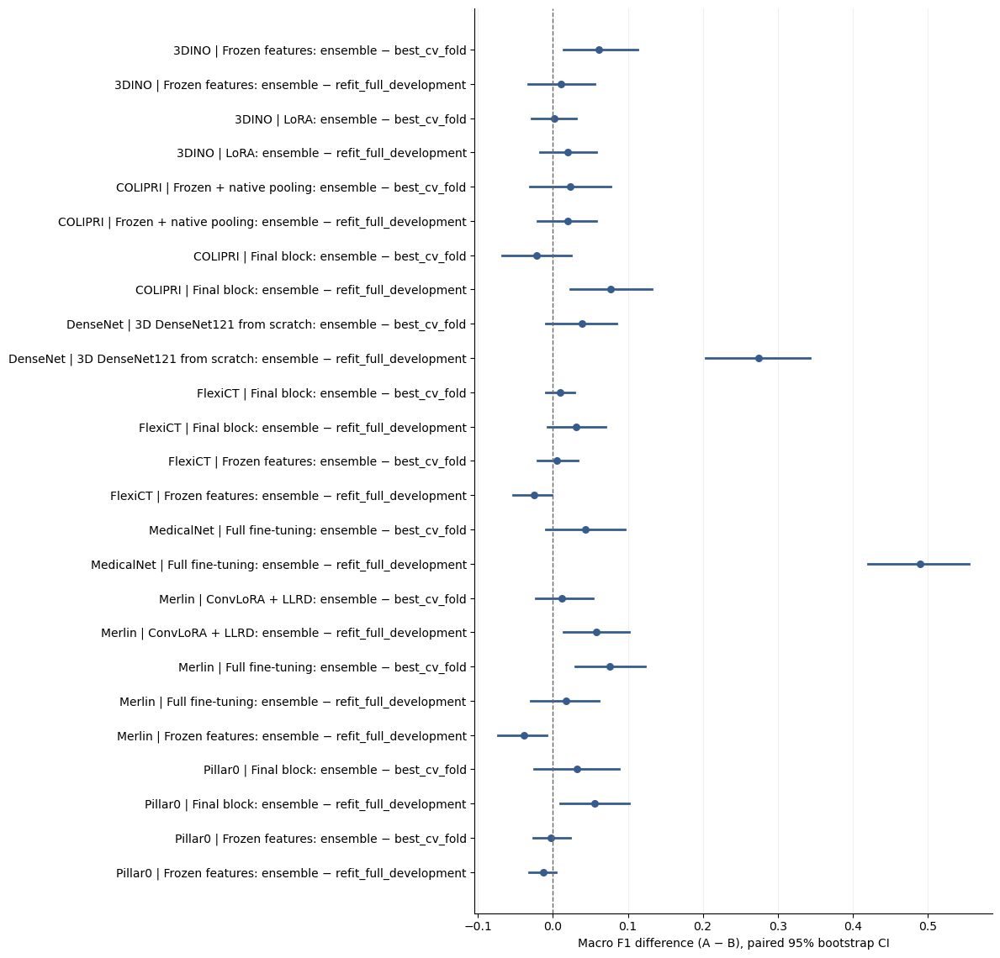

**Caption.** Paired macro-F1 differences between CV ensemble and matched best-fold/refit sources at 100% development, with 95% patient-bootstrap intervals.

In [35]:
source_100 = source_sensitivity[source_sensitivity.percentage==100] if len(source_sensitivity) else source_sensitivity
fig = ph.difference_plot(source_100)
save_figure(fig,'Figure_S6_checkpoint_sources',
    'Paired macro-F1 differences between CV ensemble and matched best-fold/refit sources at 100% development, with 95% patient-bootstrap intervals.')

### Legacy-artifact sensitivity
Legacy unsealed predictions pass content/summary checks but lack cryptographic completion evidence.
This table identifies the sealed subset of the main comparison without implying that removing an
entire model family is a fair model-performance test.

In [36]:
sealed_main = main[main.integrity=='hash_seal_verified']
save_table(ah.formatted_table(sealed_main,['f1_macro','balanced_accuracy','average_precision_macro']),
    'Table_S10_sealed_artifacts_only','Descriptive main-analysis subset with verified completion seals; legacy runs remain explicitly identified elsewhere.');

## 17. Zero-shot results (separate supplementary analysis)
Only COLIPRI, FlexiCT, Merlin and Pillar-0 enter this supplement. DenseNet, MedicalNet and 3DINO
are excluded from zero-shot discovery. No supervised checkpoint-source label is assigned to zero-shot runs. The five-class
task adaptations differ across models. Pillar-0's prompt-similarity task remains experimental and was
not demonstrated by its source study. Softmax/normalized relative scores are not assumed calibrated.
Zero-shot scores are not pooled with supervised results or used to choose prompts.

,model,method,percentage,source,cv_id,source_family,integrity,n_test,Macro F1 (95% CI),Balanced accuracy (95% CI),Macro average precision (95% CI),Macro OvR AUROC (95% CI),protocol,interpretation
58,COLIPRI,ZeroShot,0,zero_shot,Pretrained,zero_shot,hash_seal_verified,278,"0.144 (0.109, 0.181)","0.258 (0.196, 0.321)","0.246 (0.225, 0.301)","0.547 (0.499, 0.594)",colipri_publication_short_pairwise_five_class_v1,Model-specific five-class task adaptation
104,FlexiCT,ZeroShot,0,zero_shot,Pretrained,zero_shot,hash_seal_verified,278,"0.422 (0.369, 0.475)","0.489 (0.434, 0.542)","0.454 (0.420, 0.524)","0.781 (0.754, 0.809)",flexict_upstream_pairwise_five_class_v1,Model-specific five-class task adaptation
160,Merlin,ZeroShot,0,zero_shot,Pretrained,zero_shot,legacy_unsealed_content_validated,278,"0.436 (0.377, 0.495)","0.495 (0.433, 0.556)","0.485 (0.440, 0.562)","0.794 (0.763, 0.824)",merlin_publication_method_task_specific_v1,Model-specific five-class task adaptation
191,Pillar0,ZeroShot,0,zero_shot,Pretrained,zero_shot,legacy_unsealed_content_validated,278,"0.339 (0.285, 0.393)","0.383 (0.319, 0.449)","0.340 (0.311, 0.410)","0.686 (0.645, 0.727)",pillar0_qwen_findings_five_class_margin_v2,Experimental prompt similarity


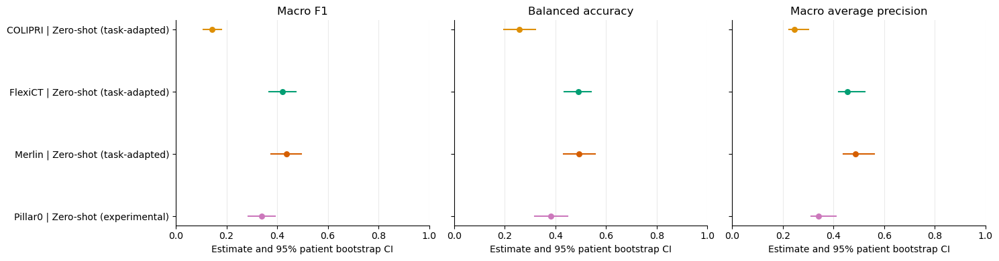

**Caption.** Separate zero-shot comparison with patient-bootstrap intervals. Pillar-0 is experimental; all methods use model-specific five-class adaptations.

In [37]:
zero_shot = results[results.zero_shot].copy()
zero_table = ah.formatted_table(zero_shot,['f1_macro','balanced_accuracy','average_precision_macro','roc_auc_macro'])
zero_table['protocol'] = zero_shot.run_id.str.split('/').str[-1]
zero_table['interpretation'] = ['Experimental prompt similarity' if m=='Pillar0' else 'Model-specific five-class task adaptation' for m in zero_table.model]
display(save_table(zero_table,'Table_S11_zero_shot','Separate five-class zero-shot results; relative score semantics and task adaptations differ.'))
fig = ph.intervals(zero_shot,['f1_macro','balanced_accuracy','average_precision_macro'])
save_figure(fig,'Figure_S7_zero_shot','Separate zero-shot comparison with patient-bootstrap intervals. Pillar-0 is experimental; all methods use model-specific five-class adaptations.')

## 18. Resource and clinical-reporting availability
Parameter counts, memory and timings require standardized measurements and hardware context before
an efficiency frontier can be interpreted. The notebook reports availability instead of synthesizing
missing values. Calibration fitting, metadata subgroups, external testing and reader comparisons are
not performed unless appropriate additional data and a specified analysis become available.

In [38]:
resource_rows = []
for run in main.itertuples():
    path = Path(run.directory) / 'resource_summary.json'
    resource_rows.append({'run_id':run.run_id,'label':run.label,
        'status':'available_for_schema_review' if path.exists() else 'standardized_resource_summary_missing',
        'resource_json':json.dumps(ah.read_json(path),sort_keys=True) if path.exists() else ''})
save_table(pd.DataFrame(resource_rows),'resource_availability','Availability of per-test standardized resource summaries; no incomparable timings are pooled.','audit')
reporting_gaps = pd.DataFrame([
    ('Recruitment and exclusions','Clinical records required; Figure 1 shows partition only'),
    ('Reference standard and label definitions','Document adjudication, readers, blinding; confirm Sigmoid category meaning'),
    ('Demographic/scanner subgroups','Linked patient metadata required; not inferred from filenames'),
    ('Pretraining overlap','Requires pretrained-cohort documentation; local disjointness alone cannot exclude overlap'),
    ('External testing','No external-cohort predictions loaded by this notebook'),
    ('Reader comparison / clinical utility','No reader or prospective workflow data loaded'),
    ('Training-seed robustness','Patient-bootstrap intervals do not substitute for repeated training seeds'),
    ('Calibration fitting','Not performed; requires leakage-safe development predictions and a specified fit procedure'),
    ('Historical test inspection','Document ensemble reporting change and prior result inspection in manuscript'),
],columns=['reporting_item','status'])
display(save_table(reporting_gaps,'reporting_gaps','Manuscript evidence requirements not supplied by saved predictions.','audit'))

## 19. CLAIM-oriented reporting map and limitations
This map locates notebook evidence; it does not certify that the clinical study satisfies every CLAIM
item. Cohort enrichment/class imbalance, the fixed Perforation pool, absence of external testing,
historical held-out inspection, differing preprocessing/tuning budgets and unmeasured seed variability
must be reflected in the manuscript. Neither aggregate accuracy nor calibration alone demonstrates
clinical benefit. The overall endpoint choice differs from the earlier plan's co-primary framing and
is recorded as part of version 4's exploratory analysis specification.

In [39]:
claim_map = pd.DataFrame([
    ('Data partitions / sample sizes','Table 1; Figure 1; split_integrity_4.csv'),
    ('Model methods / reproducibility','Table 2; all_run_provenance_4.csv; input hashes'),
    ('Missing or excluded results','run_coverage_4.csv; discovery_audit_4.csv'),
    ('Statistical uncertainty','Sections 3, 8–12; paired comparison plan and Table S4'),
    ('Diagnostic performance','Tables 3–4; Figures 2–5; Table S5'),
    ('Calibration / failures','Figure S8; Tables S6–S7; confusion matrices'),
    ('Sensitivity and reproducibility','Tables S9–S11; analysis manifest and source hashes'),
    ('Unavailable clinical evidence','reporting_gaps_4.csv; clinical records needed'),
], columns=['reporting_domain','evidence'])
save_table(claim_map,'claim_reporting_map','Notebook evidence map aligned to CLAIM reporting domains; not a completed submission checklist.','audit')
display(claim_map)

## 20. Optional local patient-level export
Disabled by default. Aggregate tables and figures do not expose patient IDs. If enabled for local
analysis, this file remains separate from the manuscript main/supplementary tables.

In [40]:
if EXPORT_PATIENT_LEVEL:
    patient_rows = []
    for run in inventory.itertuples():
        p,pred = predictions[run.run_id]
        for index,pid in enumerate(patient_ids):
            patient_rows.append({'run_id':run.run_id,'patient_id':pid,'true_class':ah.CLASSES[y_true[index]],
                'predicted_class':ah.CLASSES[pred[index]], **dict(zip(ah.CLASSES,p[index]))})
    save_table(pd.DataFrame(patient_rows),'local_patient_predictions','Local analytical export; not a manuscript table.','audit')
else:
    print('Patient-level export disabled; manuscript exports are aggregate.')

## 21. Radiologist reread: exploratory error analysis
    The source is the latest relevant forwarded work email, **WG: 20 Cases**, forwarded October 17,
    with radiologist comments dated October 9, 2026. It concerns all 20 disagreements of the
    **FlexiCT final-block, 100%, CV ensemble** with the original test labels.

    The reader's prose is summarized below; category coding is an analyst interpretation, not
    a blinded independent adjudication. No case is relabeled or excluded from performance calculations.
    The absence of a target disease does not establish a normal abdomen. There are no lesion annotations.

    **Case linkage:** 19 exact identifiers; source comment R20 has one unique unmatched candidate,
    Perforation_R20. The user considers that linkage plausible if unique; it remains explicitly
    provisional. Public-facing figures use R01–R20. Original IDs and verbatim email excerpts stay in
    the local audit folder. Do not distribute that audit folder as the supplement.

    **Pillar-0:** the comparator is the saved final Atlas block, 100%, CV ensemble. Its full-cohort
    performance belongs in Table 3. The selected 20-case comparison belongs in the supplement and
    cannot estimate an unbiased model-versus-model error rate.

In [41]:
import review_helpers_4 as rh
assert len(main) == 13 and len(ensembles) == 65 and pending_main.empty
review, manual_audit, replay_checks, review_input_hashes, review_base, flex_run, pillar_run = rh.load_review(
    ROOT, NOTEBOOK_DIR, main, predictions, patient_ids, y_true)
save_table(review, 'local_radiologist_linkage_and_verbatim',
    'LOCAL ONLY: original case IDs, source comments, analyst synthesis and provisional linkage.', 'audit')
save_table(manual_audit, 'pillar_manual_transcription_audit',
    'LOCAL ONLY: supplied values and blanks versus canonical Pillar-0 final-block CV-ensemble probabilities.', 'audit')
save_table(replay_checks, 'attribution_replay_checks',
    'Existing five-fold probabilities versus canonical predictions; original volume SHA-256 verified.', 'audit')
summary = review.groupby('review_category',sort=False).size().rename('cases').reset_index()
display(summary)
print('Exact ID links:', int((review.linkage_status == 'exact_id').sum()),
      '| Provisional links:', int((review.linkage_status != 'exact_id').sum()))
display(manual_audit[manual_audit.status == 'mismatch'][['review_id','field','user_value','saved_value']])
print('All original cohort labels and source prediction files are retained.')

### Supplementary Tables S12–S14
    Table S12 contains the narrative reread and original labels. Table S13 uses canonical Pillar-0
    predictions, while preserving the user's transcription in the local audit. The largest discrepancy
    concerns R08: the saved Pillar-0 model predicts Sigmoid, not Normal. Do not treat rounded table
    probabilities as more authoritative than the saved prediction vector.

    Table S14 reports existing explanation diagnostics. Fold agreement is descriptive because
    the folds share training patients. Only the final classifier of one fold was randomized;
    this is a limited check, not full-network attribution validation.

In [42]:
review_columns = ['review_id','true_class','predicted_class','predicted_probability',
    'true_probability','fold_votes_for_ensemble_prediction','review_category',
    'radiologist_summary','interpretation','linkage_status']
display(save_table(review[review_columns], 'Table_S12_radiologist_error_review',
    'All 20 FlexiCT-selected disagreements; original labels retained. Categories summarize a narrative reread with undocumented blinding and one provisional link.'))
pillar_columns = ['review_id','true_class','predicted_class','predicted_probability','true_probability',
    'pillar_predicted_class','pillar_predicted_probability','pillar_true_probability',
    'pillar_probability_flexict_class','pillar_matches_original_label','same_model_prediction']
display(save_table(review[pillar_columns], 'Table_S13_pillar_selected_case_comparison',
    'Canonical predictions on cases selected because FlexiCT disagreed with the original labels. Conditional descriptive counts only; full-cohort comparison is in Table 3.'))
diagnostic_columns = ['review_id','fold_votes_for_ensemble_prediction','mean_pairwise_fold_map_spearman',
    'randomized_head_map_spearman','top_mask_probability_drop','random_mask_mean_probability_drop',
    'air_fill_probability_drop','positive_drop_exceeds_random','masked_input_fraction',
    'attribution_fraction_below_minus900hu','crop_removed_xyz_mm']
display(save_table(review[diagnostic_columns], 'Table_S14_attribution_diagnostics',
    'Existing 3D token Grad-CAM and occlusion diagnostics. Masking changes input distribution; correlations do not establish clinical localization.'))

,review_id,true_class,predicted_class,predicted_probability,true_probability,fold_votes_for_ensemble_prediction,review_category,radiologist_summary,interpretation,linkage_status
0,R01,Normal,Appendicitis,0.999365,0.000143,5,Reference-label discrepancy,Clear appendicitis on reread; supports the model class.,Reconsider recorded Normal label,exact_id
1,R02,Normal,Sigmoid,0.995200,0.004087,5,Other disease / proposed exclusion,Colitis and jejunitis; neither normal nor appendicitis nor sigmoid diverticulitis.,Outside the five mutually exclusive labels,exact_id
2,R03,Normal,Cholezystitis,0.992336,0.007360,5,Other disease / proposed exclusion,Gallbladder-adjacent enhancing lesion ultimately considered a liver tumor mimicking in...,Reviewer recommends exclusion,exact_id
3,R04,Normal,Appendicitis,0.964739,0.029602,5,Other disease / proposed exclusion,Crohn disease exacerbation with surrounding inflammation and tumor infiltration.,Reviewer recommends exclusion,exact_id
4,R05,Sigmoid,Normal,0.954604,0.001733,5,Target diagnosis not supported,Incarcerated left inguinal hernia involving sigmoid; no clinical or operative proof of...,Absence of diverticulitis does not establish a normal abdomen,exact_id
5,R06,Appendicitis,Normal,0.947872,0.023118,5,Other disease / proposed exclusion,"Malignancy-associated rectal obstruction, splenomegaly and ascites; no appendicitis.",Reviewer recommends exclusion,exact_id
6,R07,Cholezystitis,Normal,0.918791,0.001955,5,Likely error / uncertain reference,Cholecystitis likely but not proven; nearby postoperative stoma may mimic inflammation.,Reviewer retains case; model likely wrong,exact_id
7,R08,Sigmoid,Perforation,0.893405,0.102834,5,Overlapping target diagnoses,Acute and chronic sigmoid diverticulitis with perforation.,Single-label task conflates coexisting diagnoses,exact_id
8,R09,Cholezystitis,Normal,0.873761,0.094810,5,Confirmed model error,"Subtle cholecystitis clinically proven, with cholestasis.",Recorded disease retained,exact_id
9,R10,Cholezystitis,Normal,0.870220,0.066142,5,Confirmed model error,"Proven cholecystitis with complex anatomy, displaced kidney, hernias, sarcopenia and c...",Recorded disease retained,exact_id


,review_id,true_class,predicted_class,predicted_probability,true_probability,pillar_predicted_class,pillar_predicted_probability,pillar_true_probability,pillar_probability_flexict_class,pillar_matches_original_label,same_model_prediction
0,R01,Normal,Appendicitis,0.999365,0.000143,Appendicitis,0.887240,0.015072,0.887240,False,True
1,R02,Normal,Sigmoid,0.995200,0.004087,Appendicitis,0.369136,0.282226,0.232272,False,False
2,R03,Normal,Cholezystitis,0.992336,0.007360,Cholezystitis,0.719382,0.206005,0.719382,False,True
3,R04,Normal,Appendicitis,0.964739,0.029602,Normal,0.596674,0.596674,0.281475,True,False
4,R05,Sigmoid,Normal,0.954604,0.001733,Normal,0.831028,0.034906,0.831028,False,True
5,R06,Appendicitis,Normal,0.947872,0.023118,Normal,0.698956,0.230063,0.698956,False,True
6,R07,Cholezystitis,Normal,0.918791,0.001955,Normal,0.542106,0.027902,0.542106,False,True
7,R08,Sigmoid,Perforation,0.893405,0.102834,Sigmoid,0.806523,0.806523,0.019938,True,False
8,R09,Cholezystitis,Normal,0.873761,0.094810,Normal,0.913831,0.025321,0.913831,False,True
9,R10,Cholezystitis,Normal,0.870220,0.066142,Normal,0.756529,0.072400,0.756529,False,True


,review_id,fold_votes_for_ensemble_prediction,mean_pairwise_fold_map_spearman,randomized_head_map_spearman,top_mask_probability_drop,random_mask_mean_probability_drop,air_fill_probability_drop,positive_drop_exceeds_random,masked_input_fraction,attribution_fraction_below_minus900hu,crop_removed_xyz_mm
0,R01,5,0.593558,-0.101374,0.987266,0.030251,0.339857,True,0.09375,0.206137,64/64/164
1,R02,5,0.535673,0.025278,0.994467,0.341125,0.994977,True,0.09375,0.150653,20/20/84
2,R03,5,0.596723,0.003305,0.991009,0.024934,0.991309,True,0.09375,0.049818,82/82/118
3,R04,5,0.662072,-0.064280,0.963040,0.534597,0.962789,True,0.09375,0.073225,38/38/88
4,R05,5,0.841155,-0.527526,-0.003344,-0.040509,0.001648,False,0.09375,0.502942,36/36/76
5,R06,5,0.738942,-0.368753,-0.006621,-0.037155,0.002002,False,0.09375,0.581437,0/0/96
6,R07,5,0.828425,-0.210595,-0.024769,-0.037424,0.008683,False,0.09375,0.776626,64/64/60
7,R08,5,0.572742,-0.283257,-0.018546,-0.042311,-0.052213,False,0.09375,0.299074,58/58/116
8,R09,5,0.719014,-0.276915,-0.097356,-0.110111,-0.033455,False,0.09375,0.237868,136/136/118
9,R10,5,0.826557,-0.264484,0.122516,0.021543,0.032560,True,0.09375,0.725052,44/44/32


### Main Figure 6. Four complementary disagreement mechanisms
    The four illustrative cases were chosen for distinct review categories: R01 (reference-label
    discrepancy), R13 (confirmed false positive), R08 (coexisting target diagnoses), and R14 (confirmed
    missed perforation). This is a qualitative editorial selection, not a representative sampling claim.

    Maps are reused from the executed error-review notebook. They target the class probability at
    the final transformer block's norm1 output, with a 3D token Grad-CAM adaptation. The native grid
    is 20³ at 16-mm spacing; interpolation is for display only. Raw fold maps are averaged before
    rectification; the resulting positive target maps are normalized independently. Contrast is the signed difference of raw maps.
    Slices pass through the predicted-map maximum, **not a radiologist-annotated lesion**.
    CT is the cropped 160³ model input in LPS orientation at 2-mm spacing, shown at WL 40/WW 400.
    Heatmap patterns cannot confirm the reader's proposed anatomical explanation.

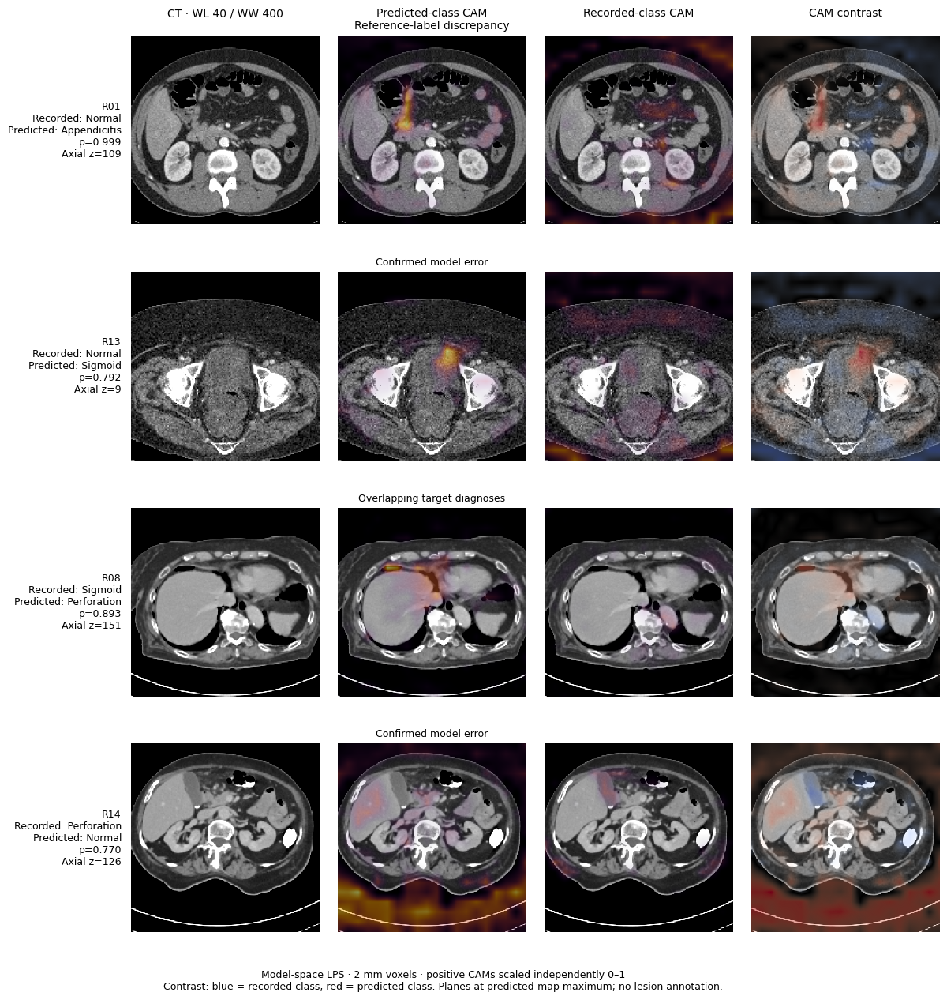

**Caption.** Four editorially selected disagreement mechanisms: R01 reread supports appendicitis; R13 confirmed false positive with a clip proposed as a mimic; R08 diverticulitis and perforation coexist; R14 surgically confirmed covered perforation missed as Normal. CT and maps share a plane at the predicted-map maximum. Independent positive scales 0–1; signed contrast red favors predicted class, blue recorded class. No lesion localization or causal interpretation is established.

In [43]:
representative_keys = ['Normal_R01','Normal_R13','Sigmoid_R08','Perforation_R14']
representative = review.set_index('case_key').loc[representative_keys].reset_index()
save_figure(rh.case_panel(representative,review_base), 'Figure_6_clinical_error_examples',
    'Four editorially selected disagreement mechanisms: R01 reread supports appendicitis; R13 confirmed false positive with a clip proposed as a mimic; R08 diverticulitis and perforation coexist; R14 surgically confirmed covered perforation missed as Normal. CT and maps share a plane at the predicted-map maximum. Independent positive scales 0–1; signed contrast red favors predicted class, blue recorded class. No lesion localization or causal interpretation is established.', 'main')

### Figure S9. Perturbation and attribution diagnostics
    Six 40³-voxel cubes (9.375% of the input) were masked using the predicted-class map. They were
    compared with the mean of three random masks and with air-filled masks. A positive change is a
    decrease in predicted-class probability. Negative values show why map intensity alone cannot
    be read as a causal explanation. The 80-mm cubes can cover multiple structures.

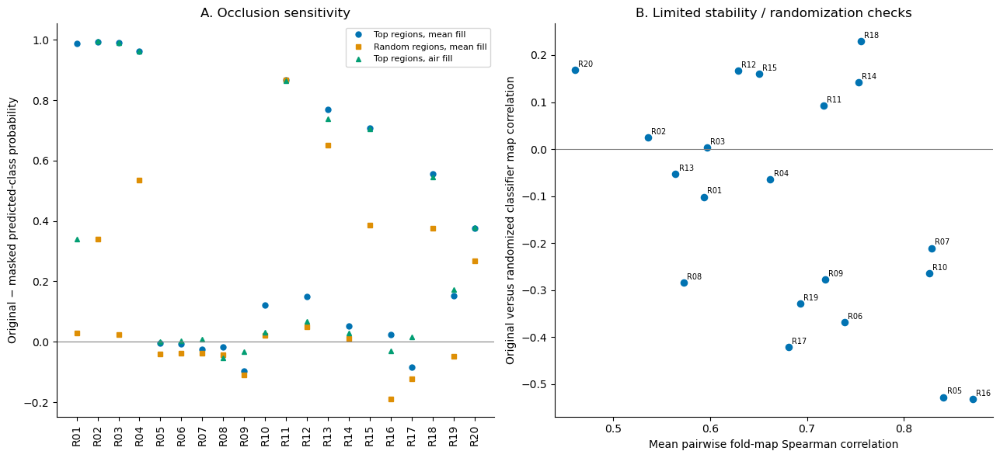

**Caption.** Existing occlusion and map diagnostics across the 20 selected disagreements. Randomization affects only fold 1 classifier; it does not validate localization. Mean-fill and air-fill are out-of-distribution interventions.

In [44]:
fig, axes = plt.subplots(1,2,figsize=(13,6))
x = np.arange(len(review))
for column,label,marker in [('top_mask_probability_drop','Top regions, mean fill','o'),
                           ('random_mask_mean_probability_drop','Random regions, mean fill','s'),
                           ('air_fill_probability_drop','Top regions, air fill','^')]:
    axes[0].plot(x,review[column],marker=marker,ls='',label=label,ms=5)
axes[0].axhline(0,color='gray',lw=.8)
axes[0].set(xticks=x,xticklabels=review.review_id,ylabel='Original − masked predicted-class probability')
axes[0].tick_params(axis='x',rotation=90); axes[0].legend(fontsize=8)
axes[0].set_title('A. Occlusion sensitivity')
axes[1].scatter(review.mean_pairwise_fold_map_spearman,review.randomized_head_map_spearman,s=35)
for row in review.itertuples():
    axes[1].annotate(row.review_id,(row.mean_pairwise_fold_map_spearman,row.randomized_head_map_spearman),xytext=(3,3),textcoords='offset points',fontsize=7)
axes[1].axhline(0,color='gray',lw=.8)
axes[1].set(xlabel='Mean pairwise fold-map Spearman correlation',
            ylabel='Original versus randomized classifier map correlation',
            title='B. Limited stability / randomization checks')
fig.tight_layout()
save_figure(fig,'Figure_S9_attribution_diagnostics',
    'Existing occlusion and map diagnostics across the 20 selected disagreements. Randomization affects only fold 1 classifier; it does not validate localization. Mean-fill and air-fill are out-of-distribution interventions.')

### Figures S10 and S11. Complete 20-case image atlas
    S10 provides CT, predicted-class CAM, recorded-class CAM and signed contrast in axial, coronal
    and sagittal planes for every case. S11 provides 12 axial slices through each cropped model input.
    The model crop may omit anatomy. R20 is the provisional original-source/cohort provisional linkage linkage. There are no lesion
    arrows because no verified lesion coordinates were supplied. The displayed anatomy is not used
    to infer a new diagnosis. PNG and PDF files are exported individually for editorial selection.

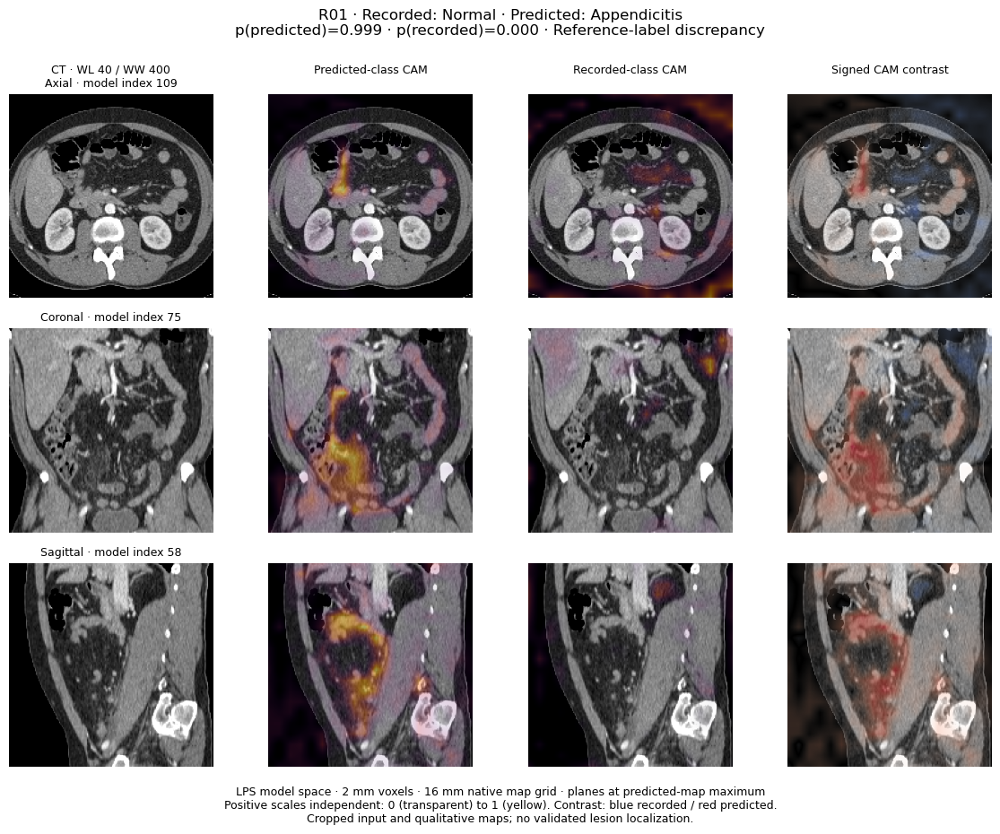

**Caption.** R01: Clear appendicitis on reread; supports the model class. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

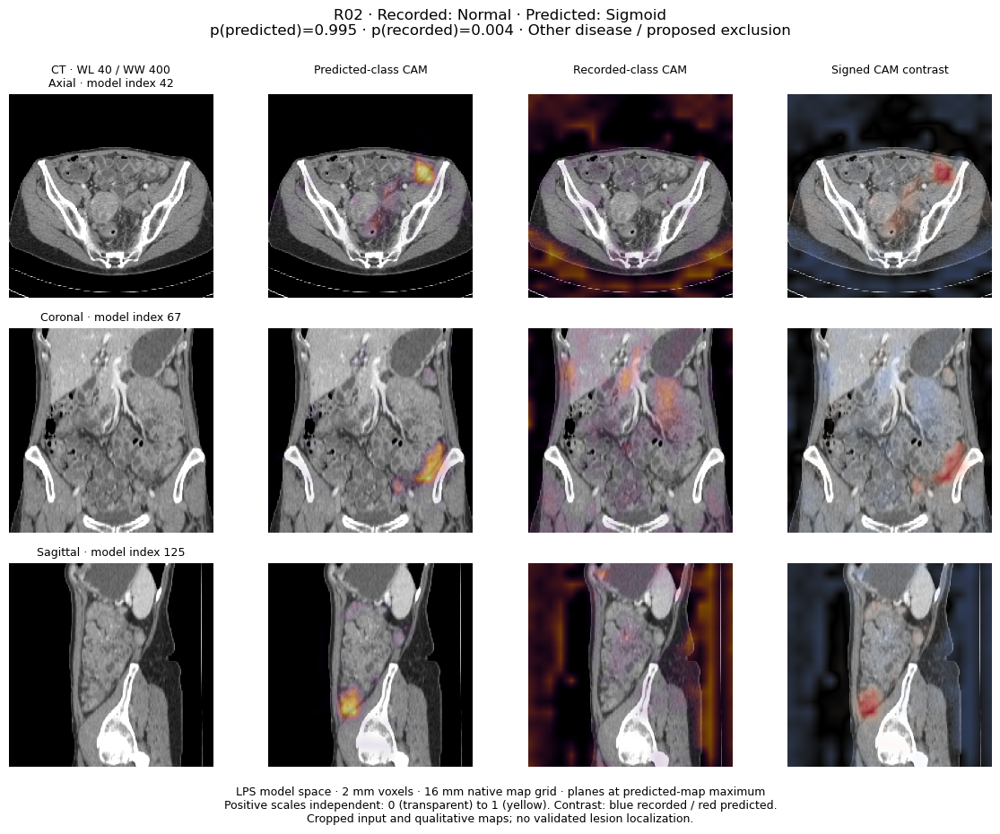

**Caption.** R02: Colitis and jejunitis; neither normal nor appendicitis nor sigmoid diverticulitis. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

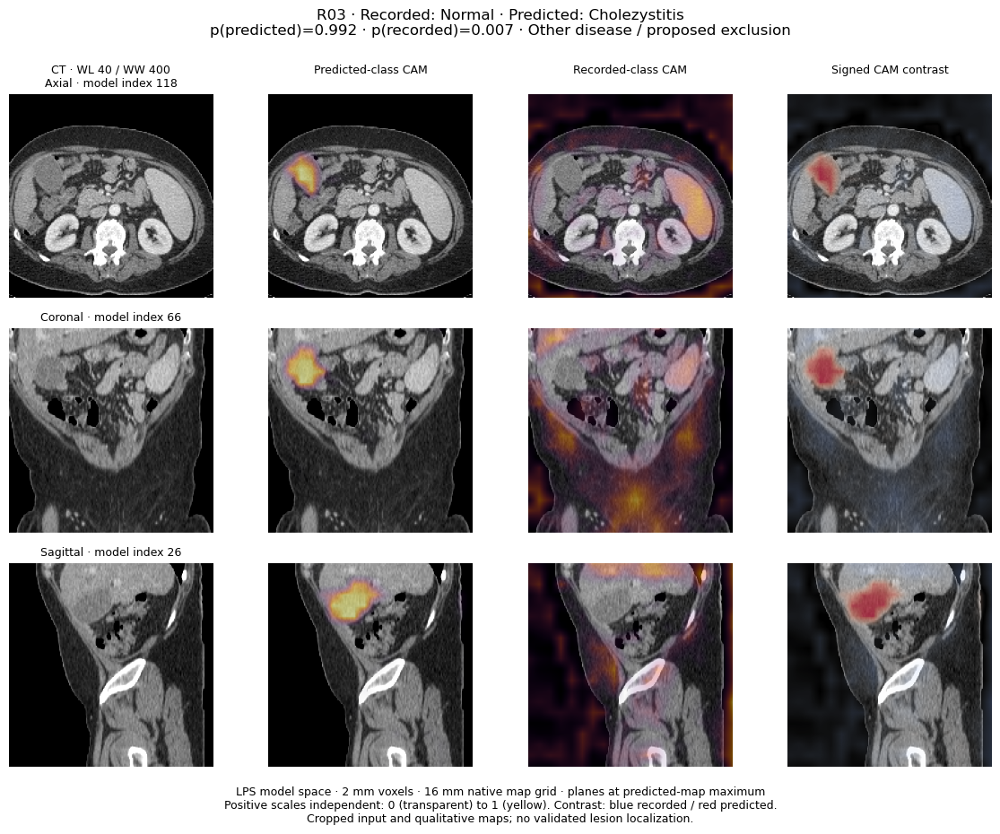

**Caption.** R03: Gallbladder-adjacent enhancing lesion ultimately considered a liver tumor mimicking inflammation. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

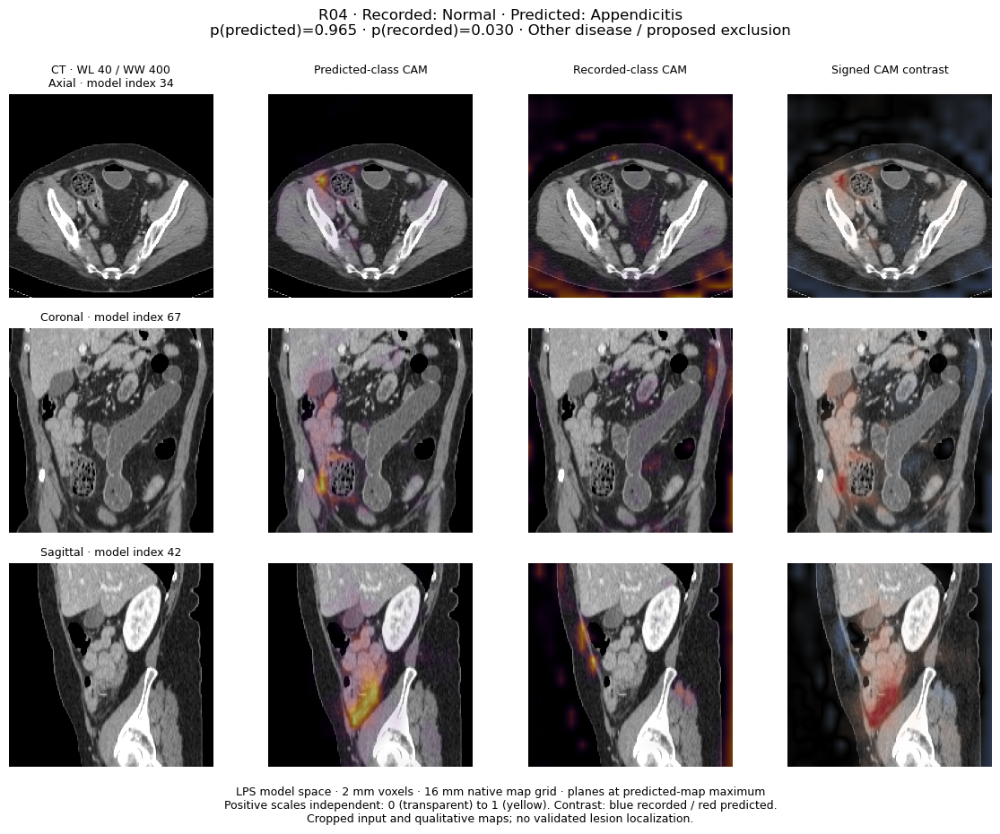

**Caption.** R04: Crohn disease exacerbation with surrounding inflammation and tumor infiltration. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

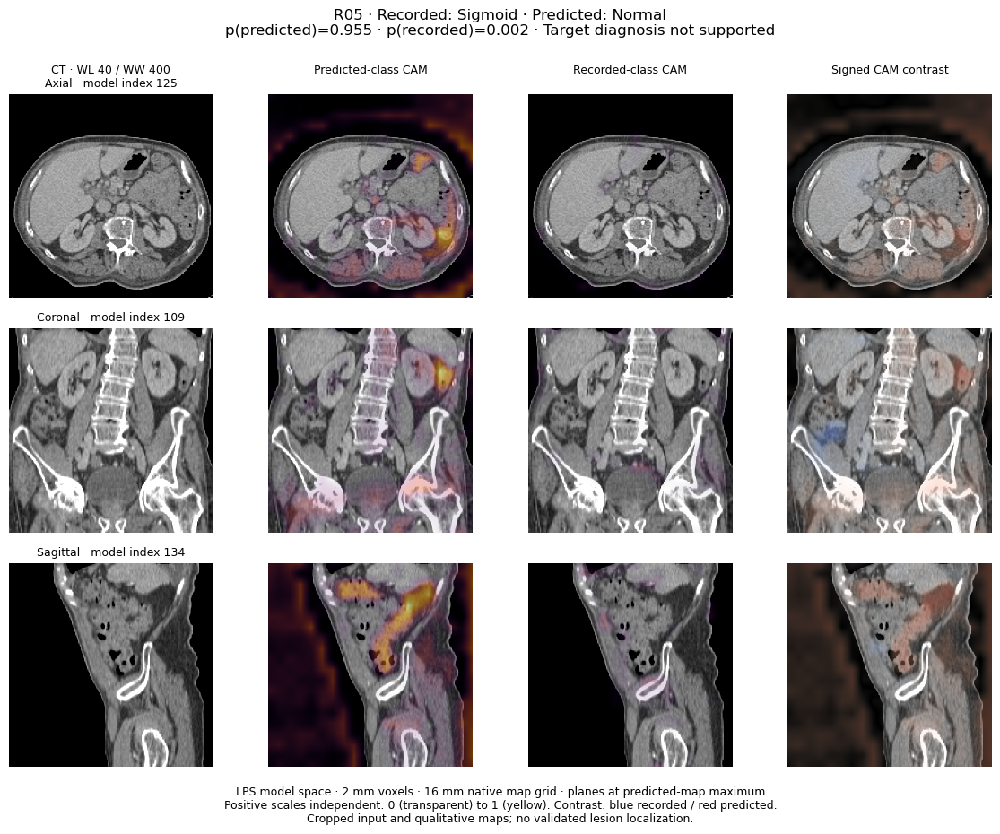

**Caption.** R05: Incarcerated left inguinal hernia involving sigmoid; no clinical or operative proof of diverticulitis. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

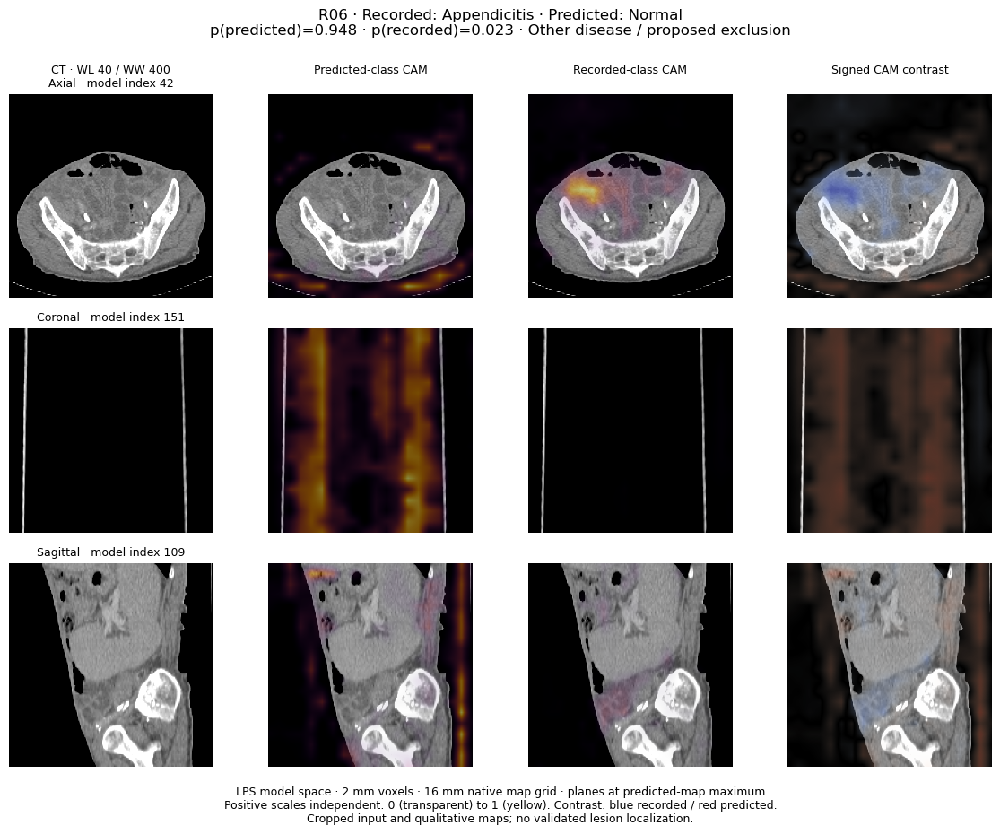

**Caption.** R06: Malignancy-associated rectal obstruction, splenomegaly and ascites; no appendicitis. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

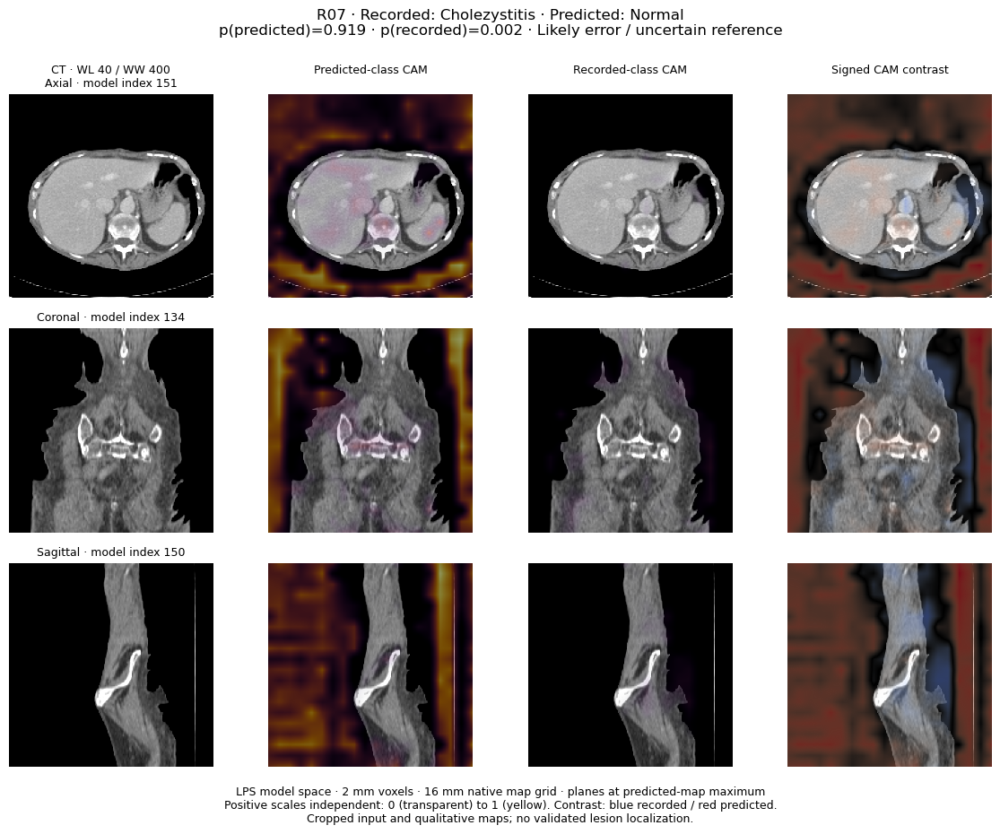

**Caption.** R07: Cholecystitis likely but not proven; nearby postoperative stoma may mimic inflammation. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

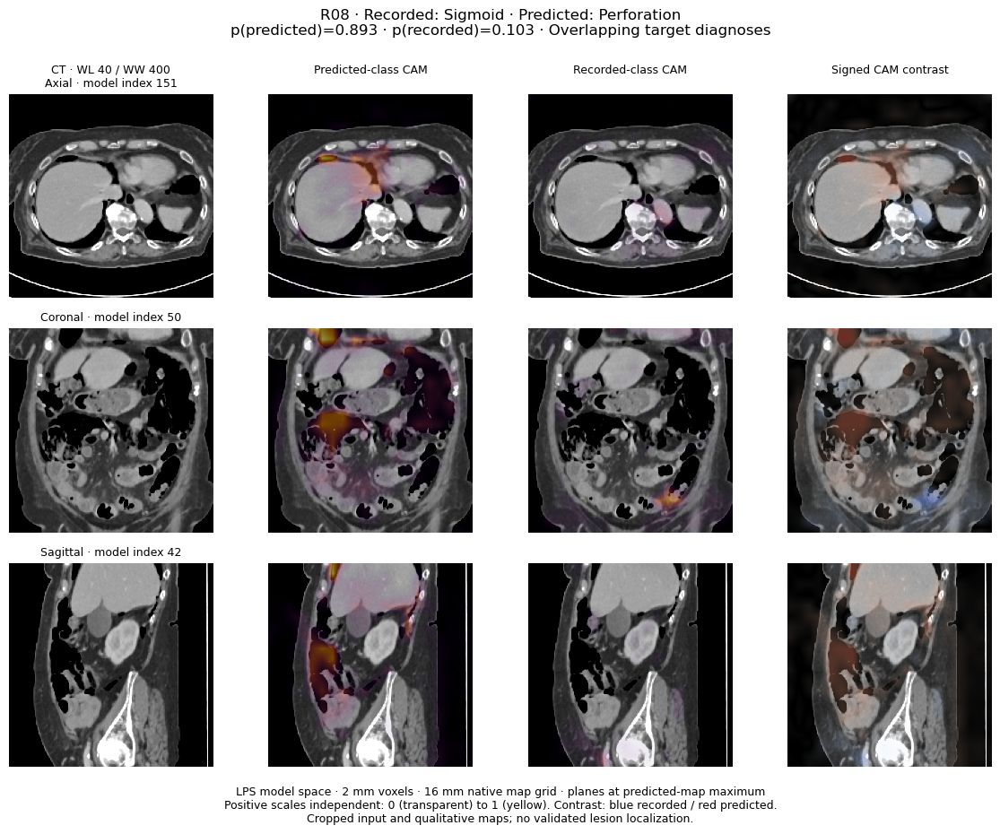

**Caption.** R08: Acute and chronic sigmoid diverticulitis with perforation. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

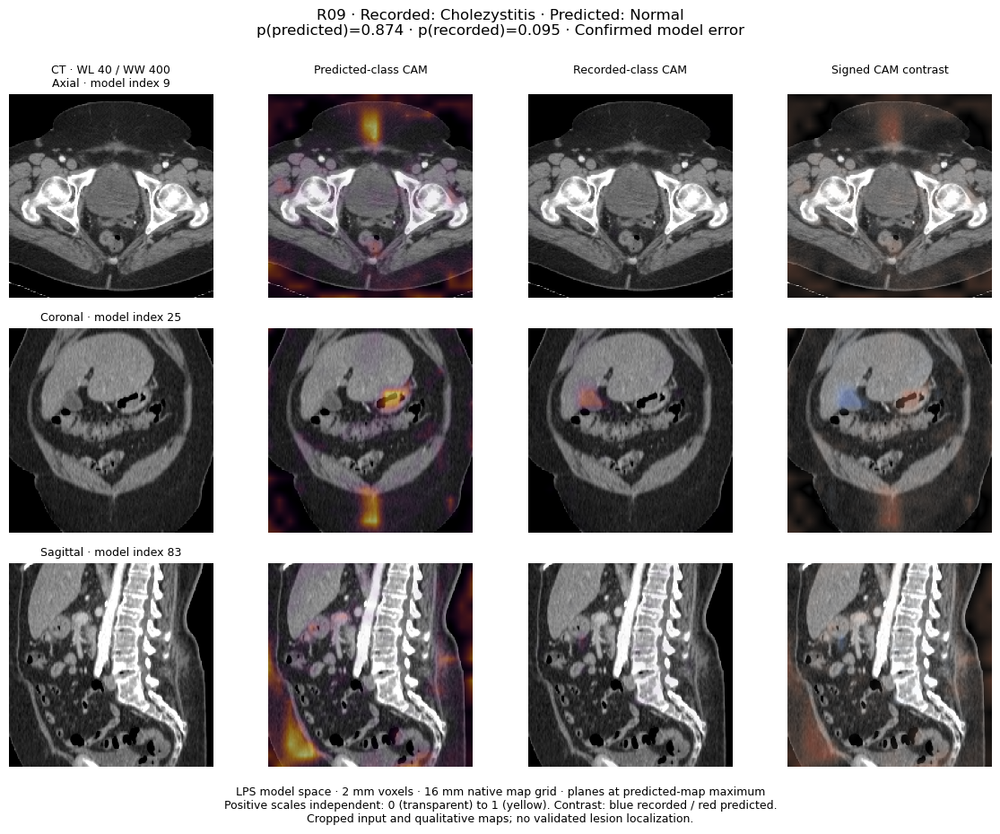

**Caption.** R09: Subtle cholecystitis clinically proven, with cholestasis. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

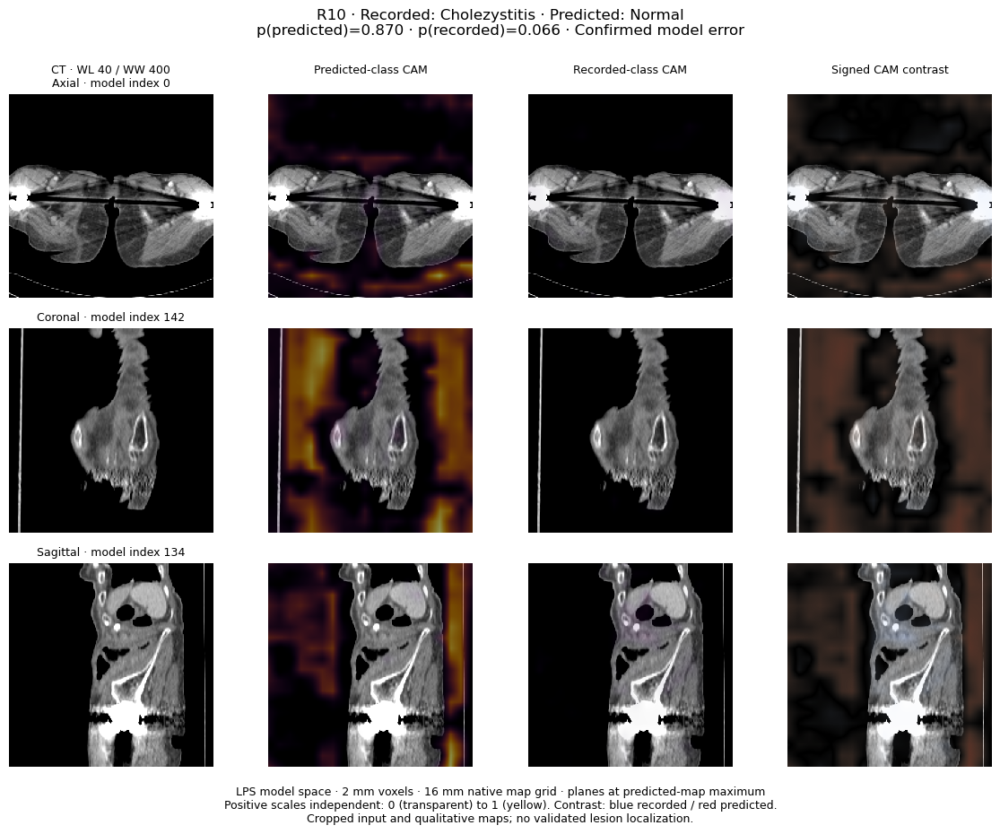

**Caption.** R10: Proven cholecystitis with complex anatomy, displaced kidney, hernias, sarcopenia and chronic inflammation. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

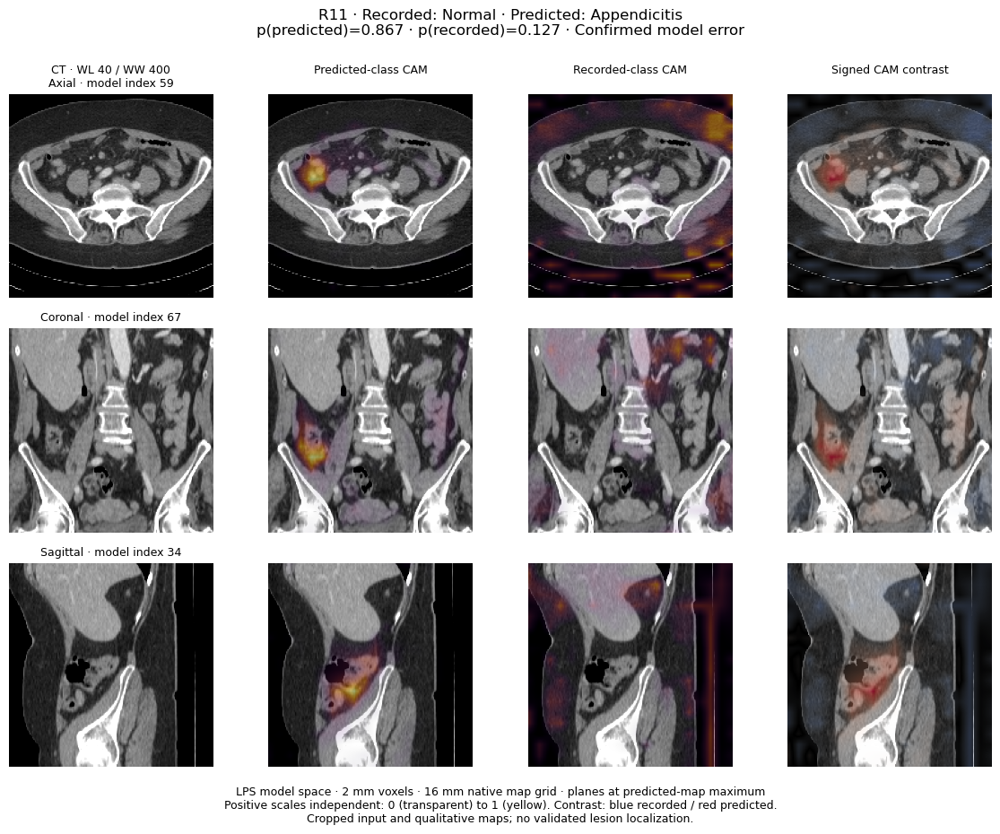

**Caption.** R11: No pathology on either review. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

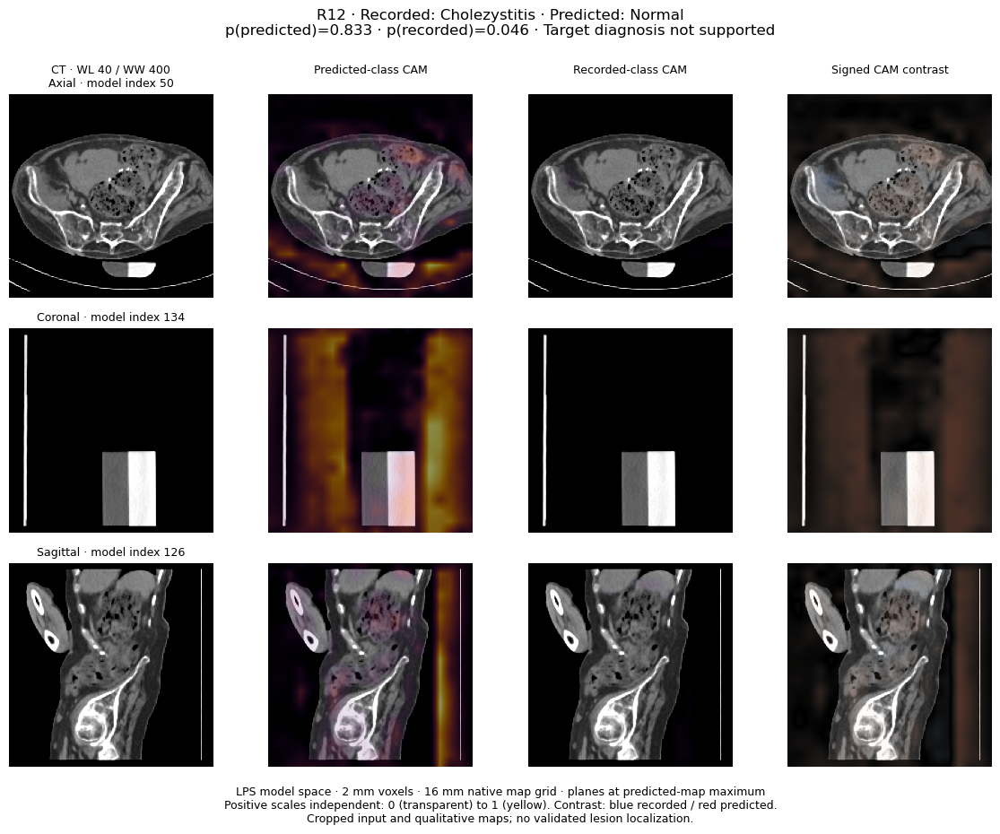

**Caption.** R12: Urosepsis and gallbladder hydrops; initial noncontrast CT diagnosis of cholecystitis was not supported. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

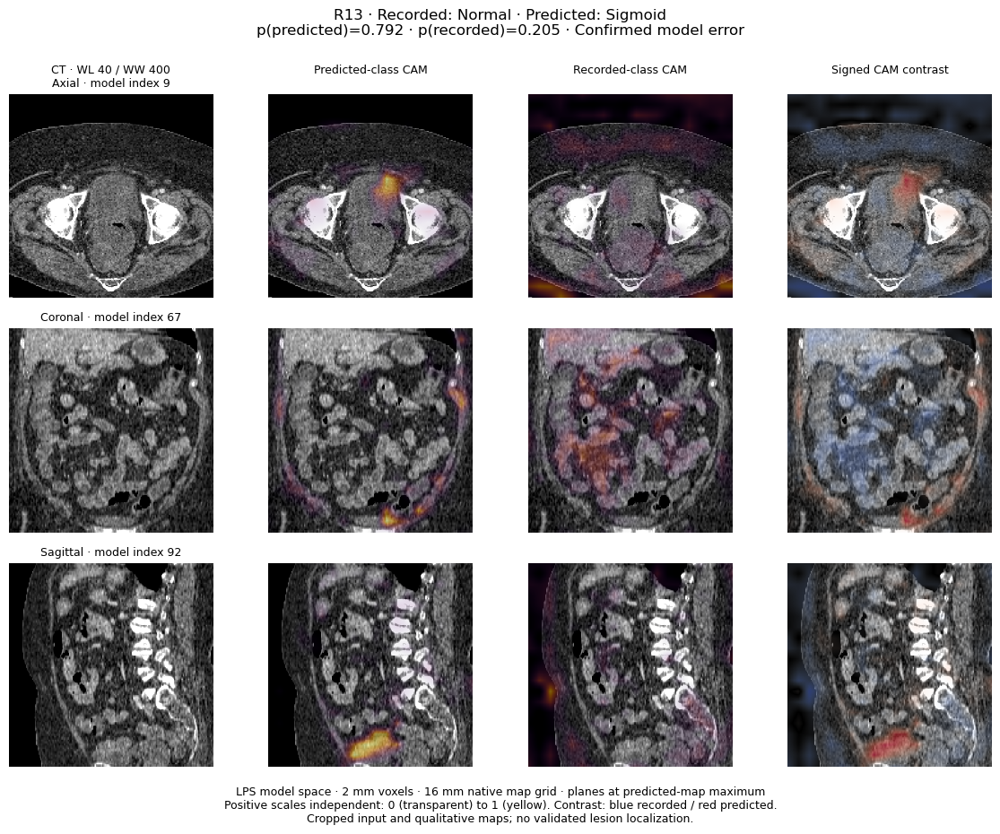

**Caption.** R13: No pathology on two reviews; a dense sigmoid clip is a proposed mimic. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

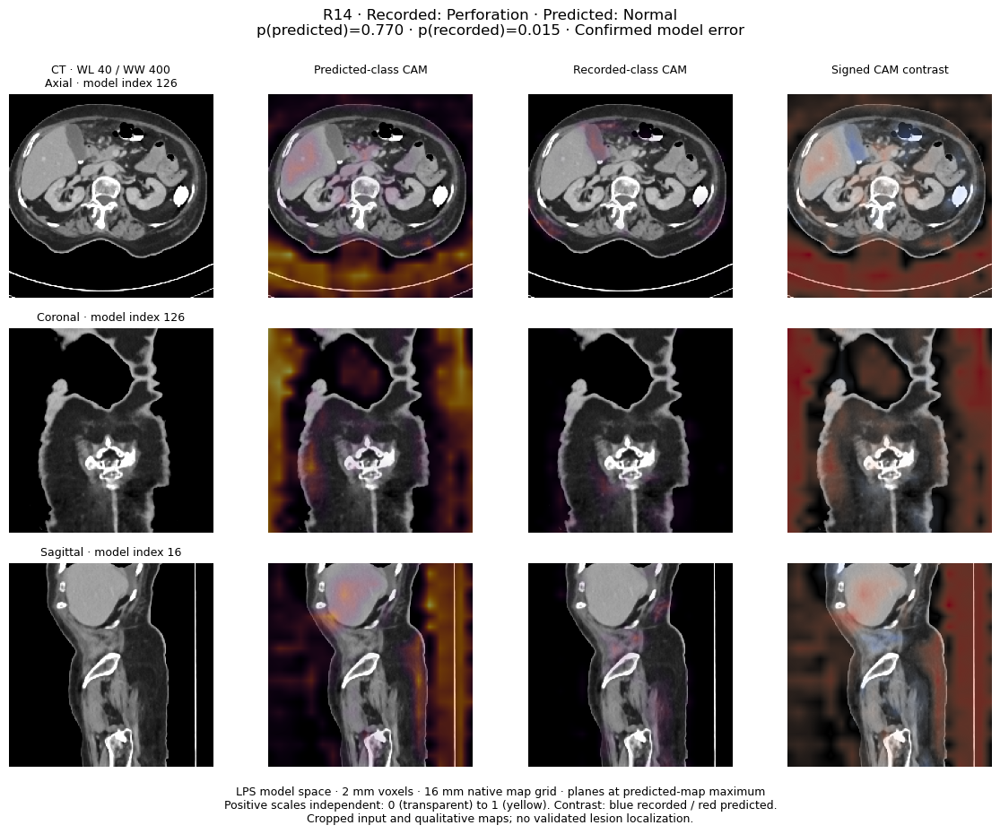

**Caption.** R14: Operatively confirmed covered duodenal perforation with large air/fluid collection and atypical anatomy. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

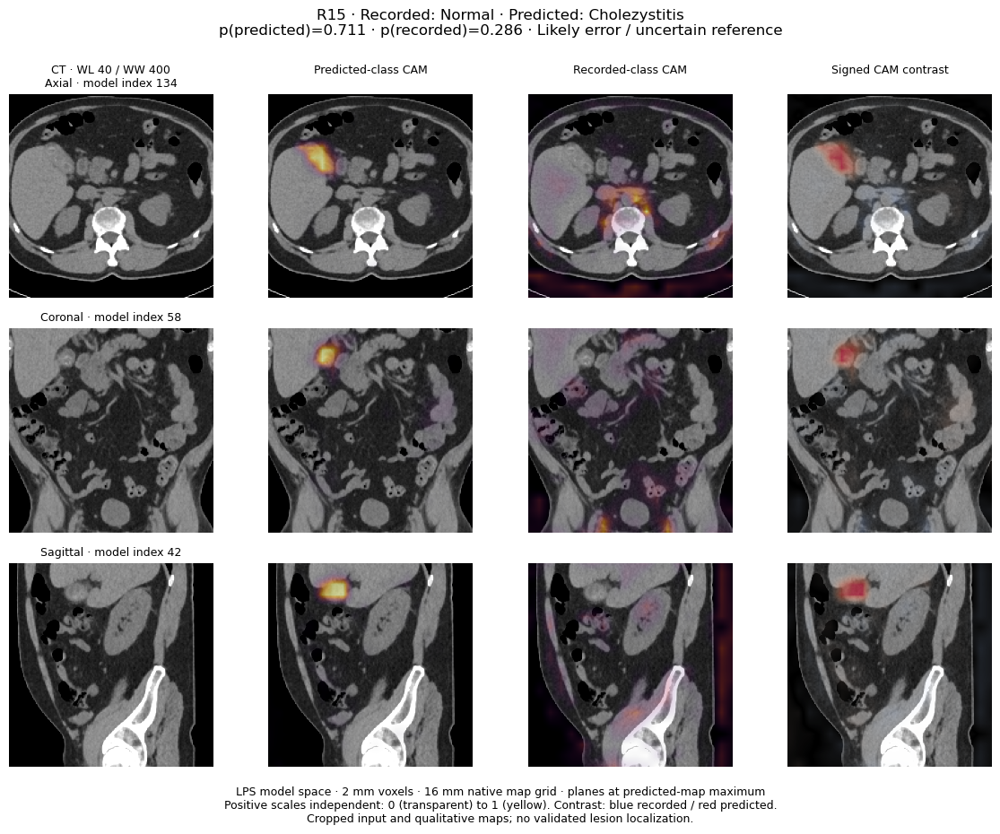

**Caption.** R15: Gallstones, chronic wall changes and symptoms improving with antibiotics; no definitive reference diagnosis. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

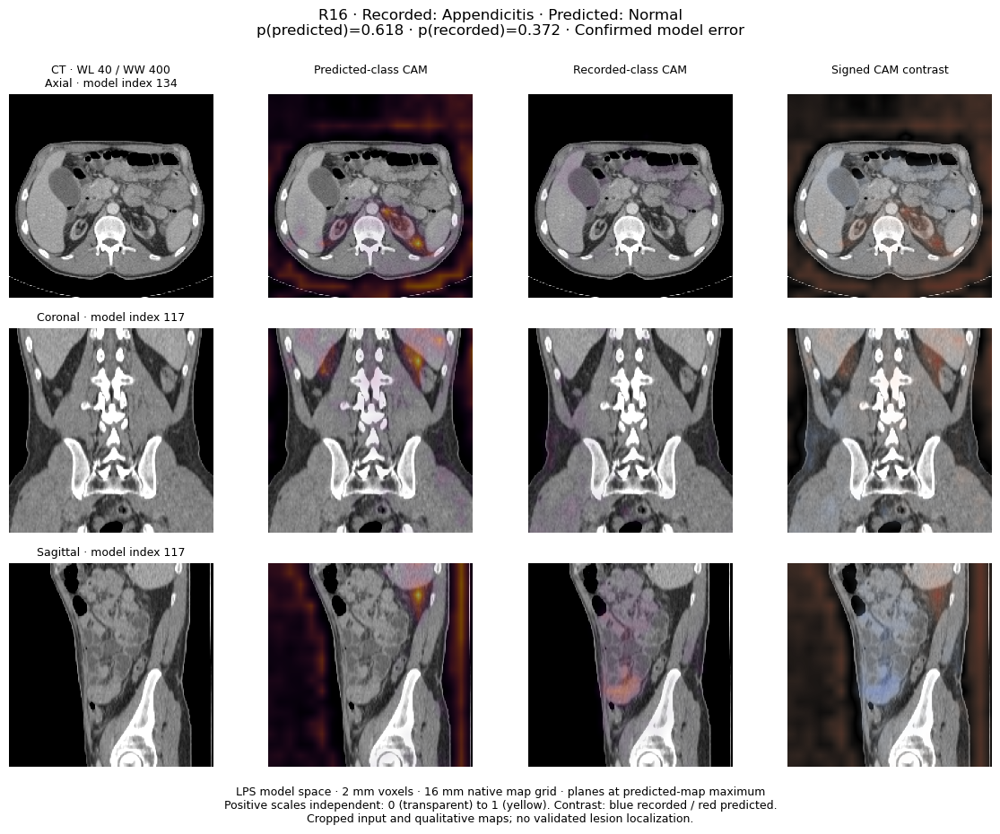

**Caption.** R16: Clear uncomplicated appendicitis; renal transplant changes anatomy. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

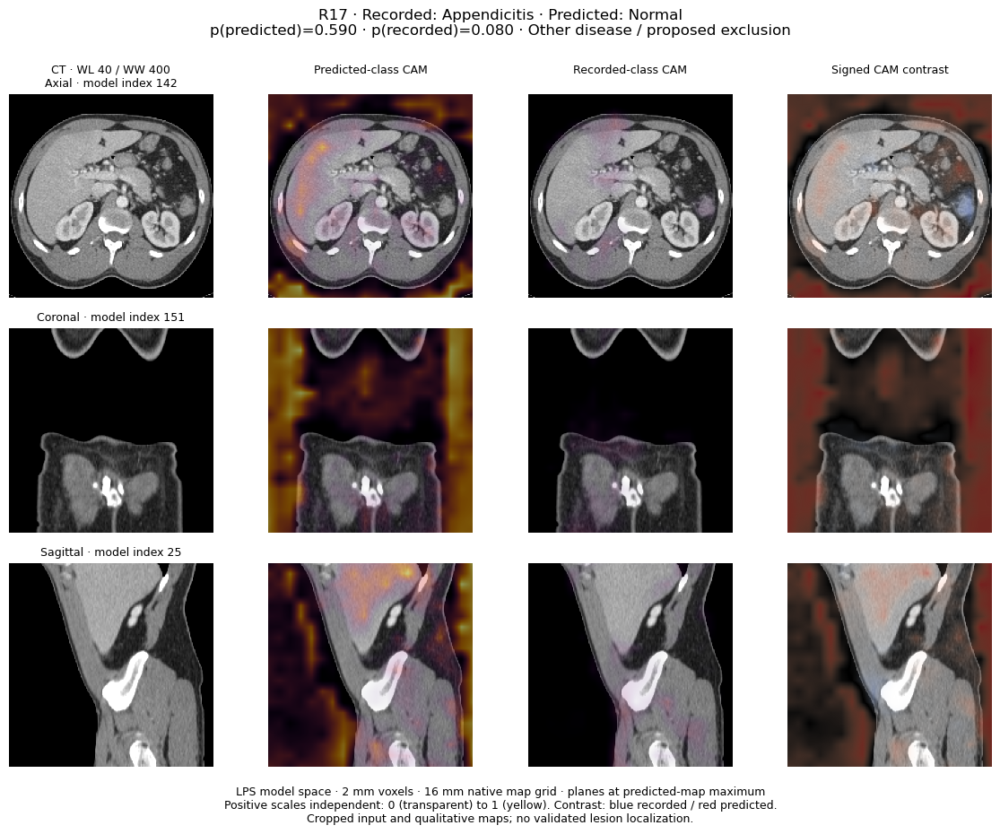

**Caption.** R17: Extensive ulcerative colitis with secondary appendiceal enhancement rather than primary appendicitis. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

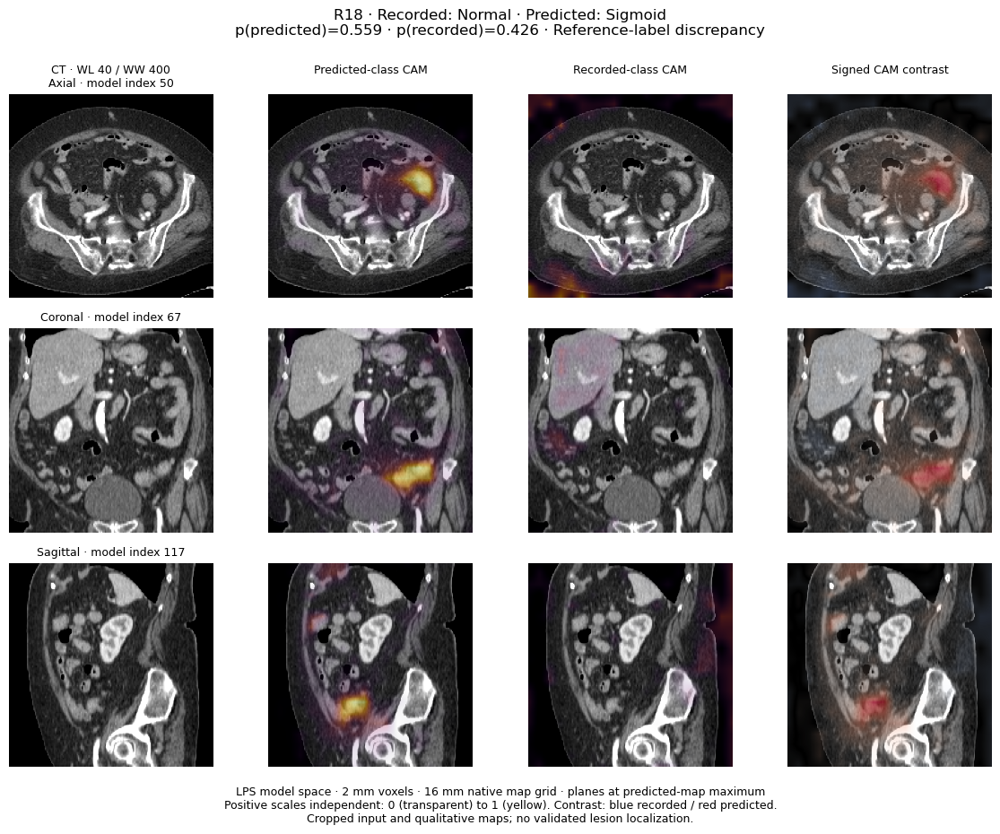

**Caption.** R18: Bacterial colitis with focal sigmoid inflammation and diverticula; diverticulitis considered likely. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

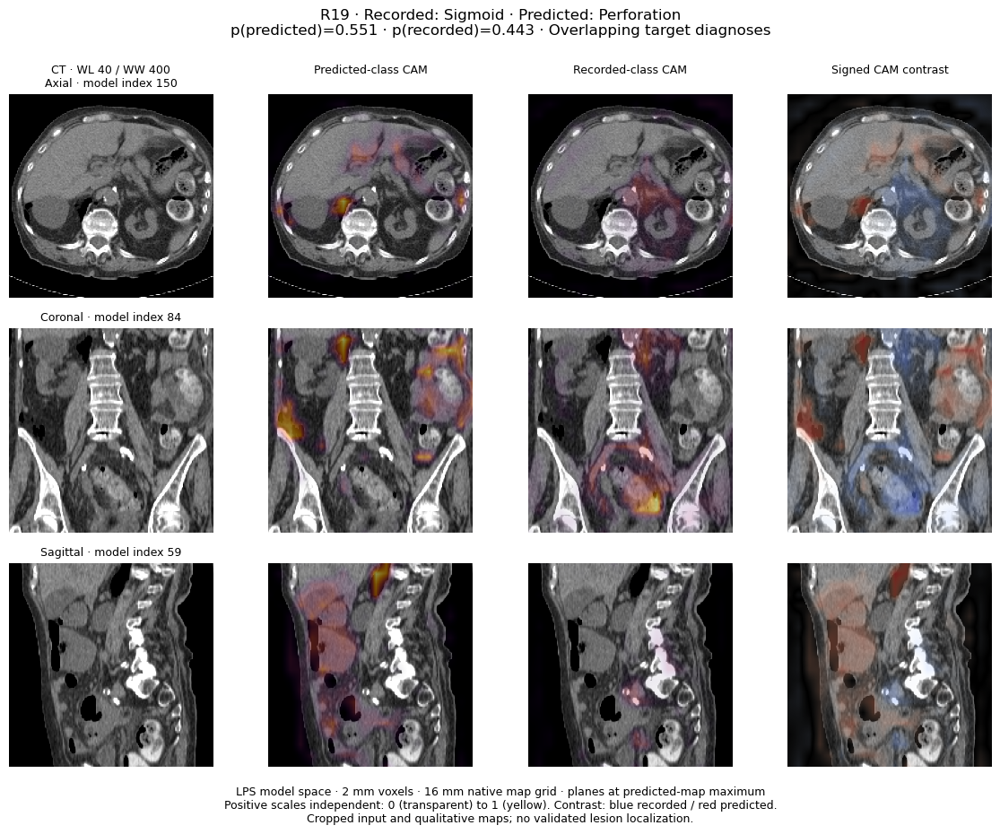

**Caption.** R19: Sigmoid diverticulitis with perforation. Linkage: exact_id. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

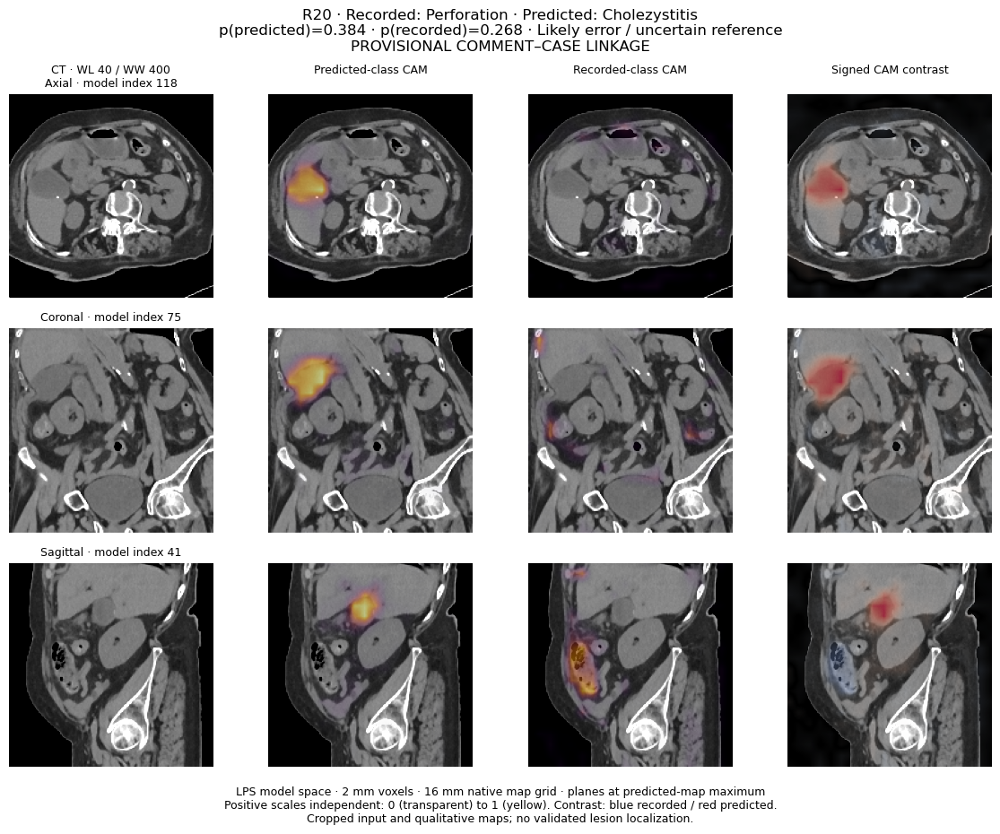

**Caption.** R20: Reviewer describes pyloric perforation with minimal free air and gallbladder hydrops mimicking cholecystitis; exclusion or discussion suggested. Linkage: provisional_user_inference. Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.

In [45]:
for row in review.itertuples():
    fig = rh.orthogonal_panel(row,review_base)
    save_figure(fig,f'Figure_S10_{row.review_id}_three_plane_attribution',
        f'{row.review_id}: {row.radiologist_summary} Linkage: {row.linkage_status}. '
        'Existing model-space maps; independently normalized positive targets and signed contrast; planes through predicted-map maximum, not lesion annotations.')

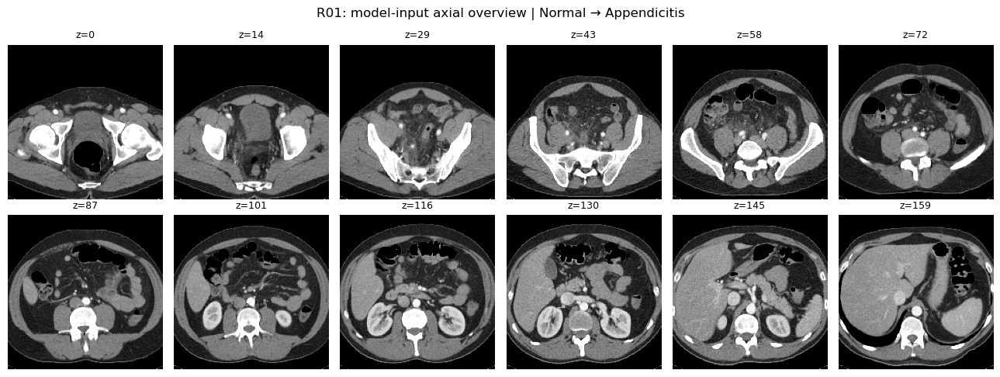

**Caption.** R01: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

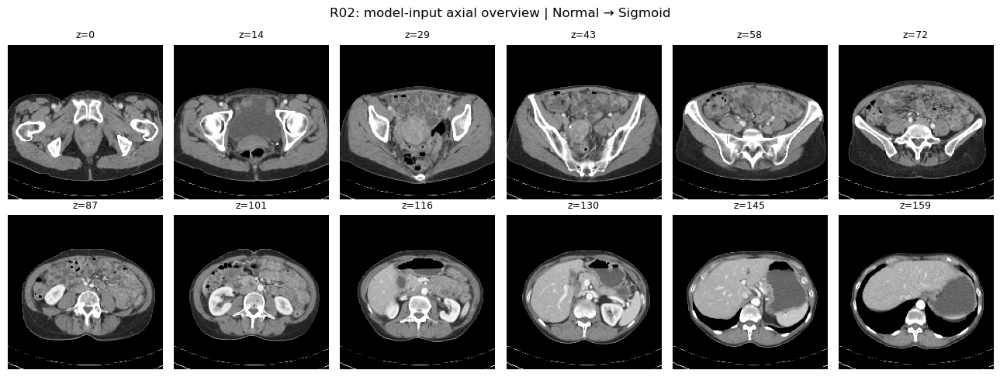

**Caption.** R02: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

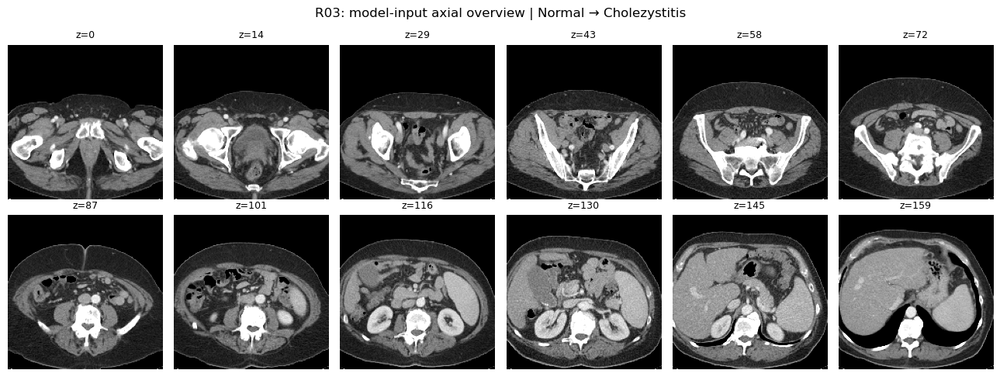

**Caption.** R03: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

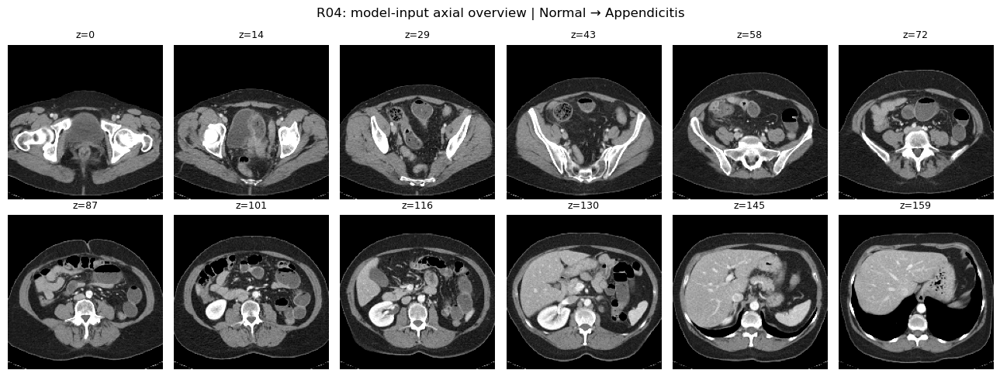

**Caption.** R04: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

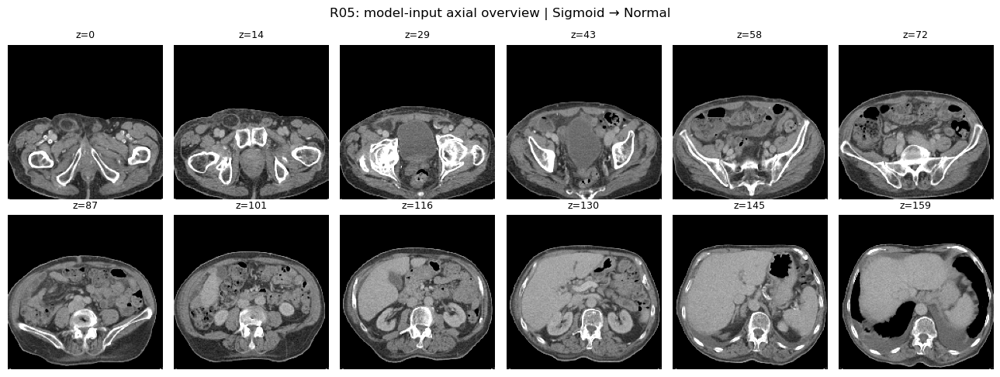

**Caption.** R05: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

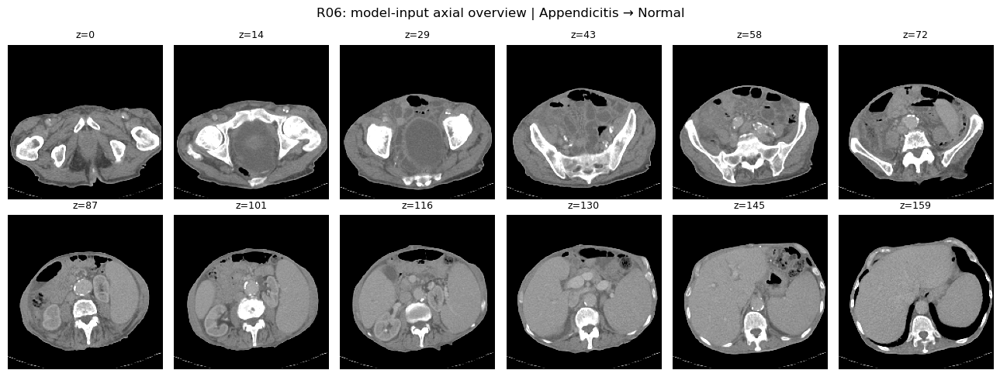

**Caption.** R06: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

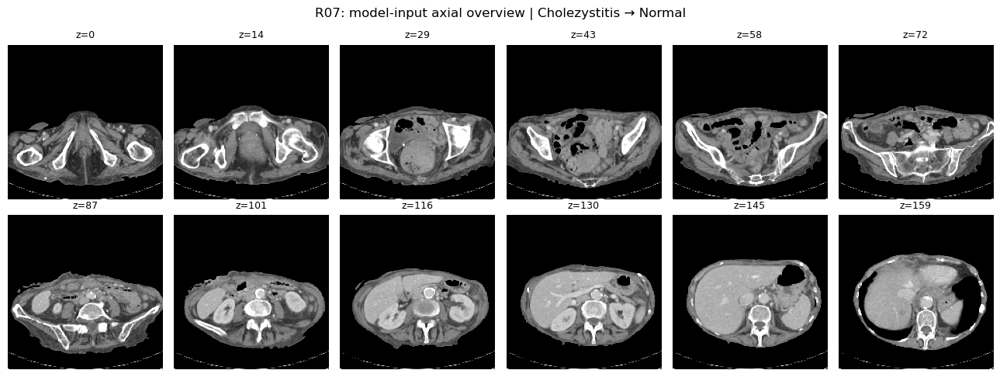

**Caption.** R07: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

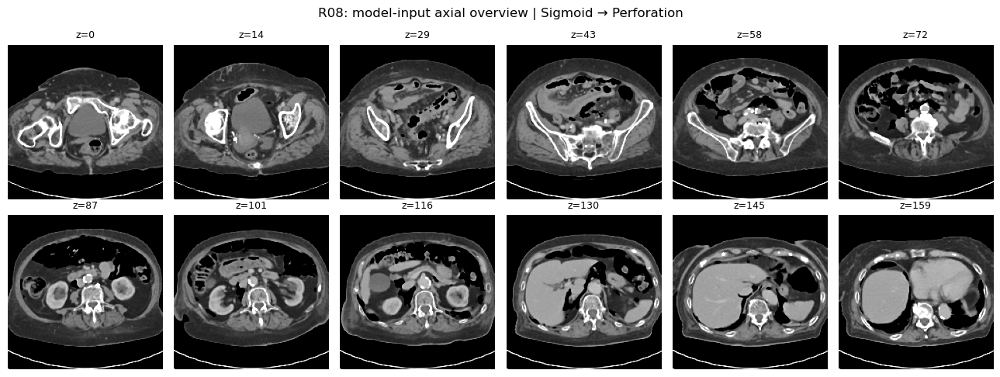

**Caption.** R08: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

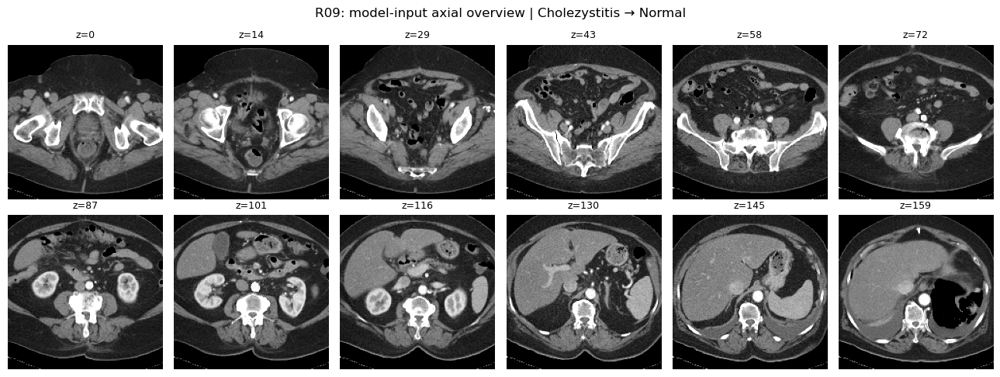

**Caption.** R09: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

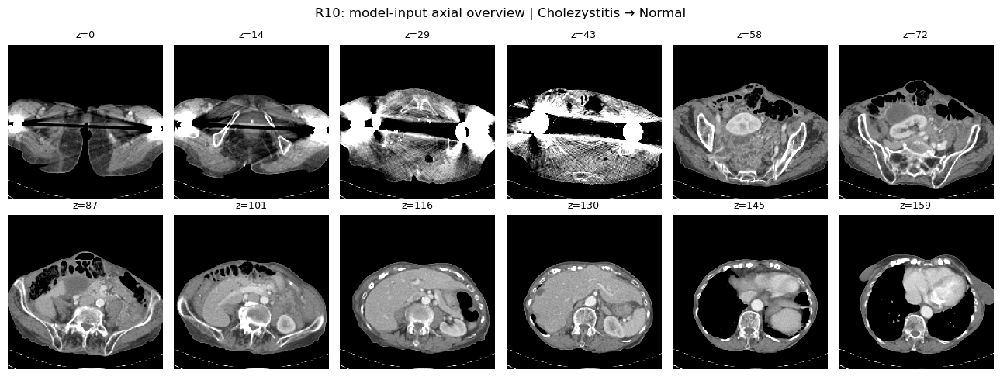

**Caption.** R10: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

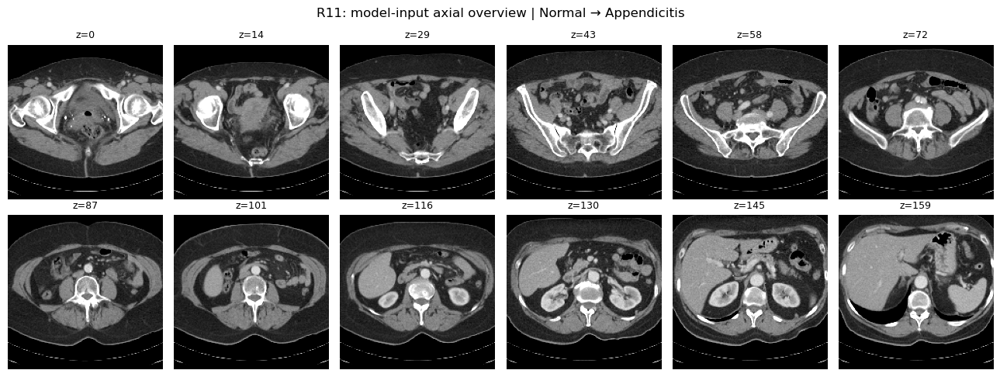

**Caption.** R11: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

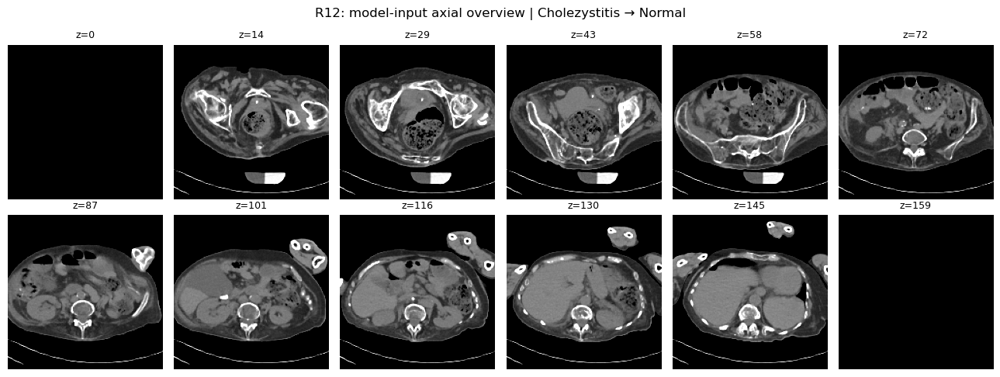

**Caption.** R12: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

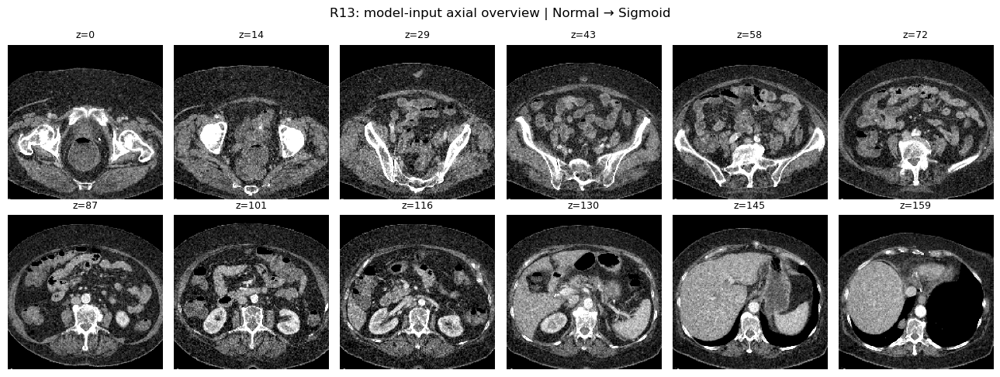

**Caption.** R13: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

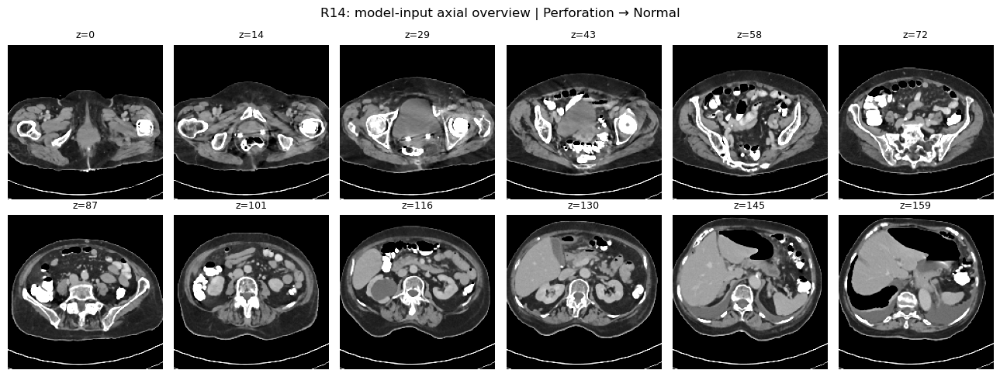

**Caption.** R14: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

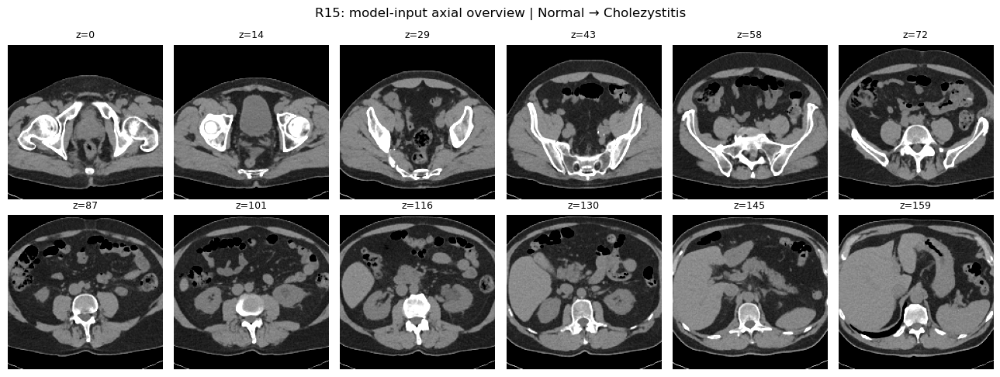

**Caption.** R15: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

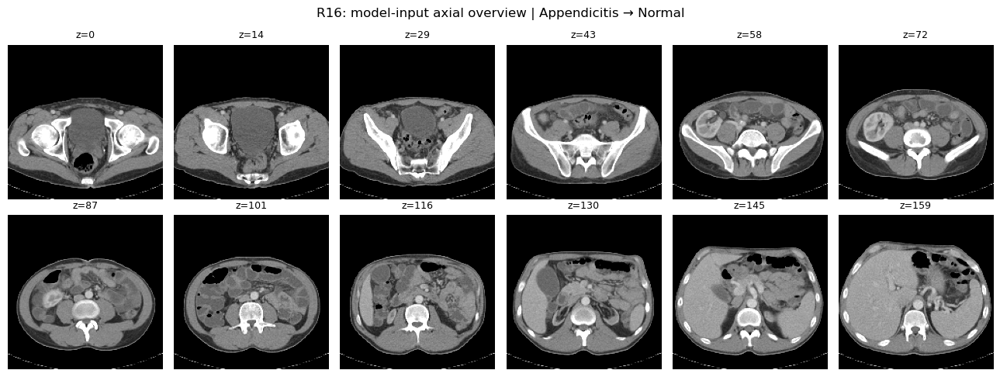

**Caption.** R16: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

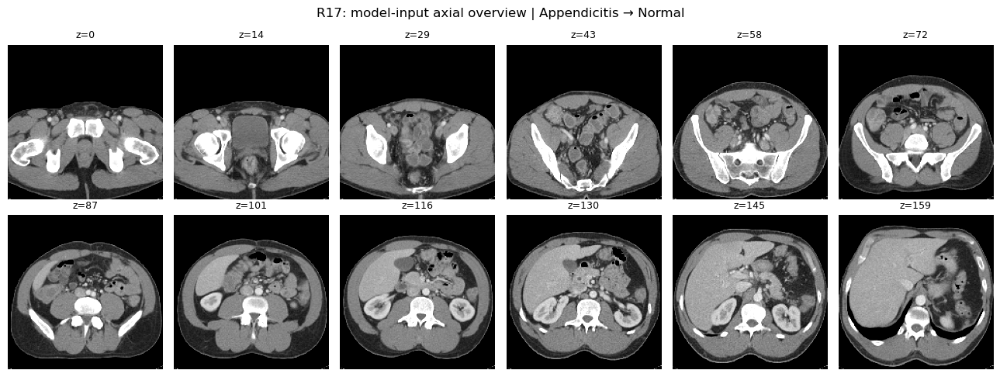

**Caption.** R17: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

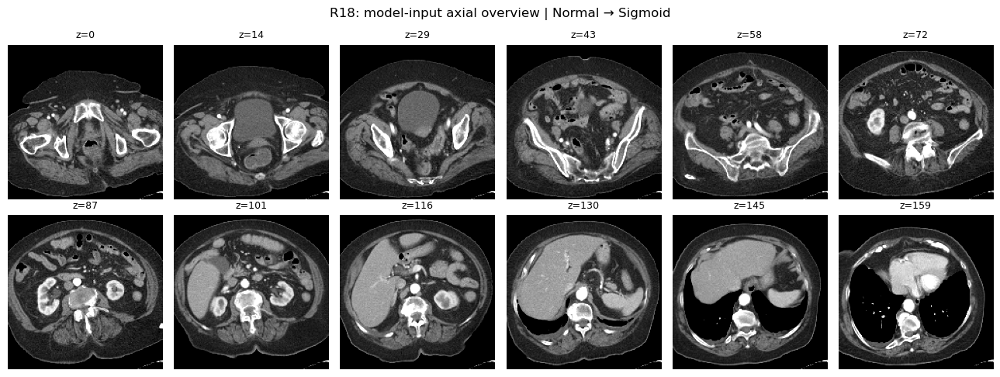

**Caption.** R18: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

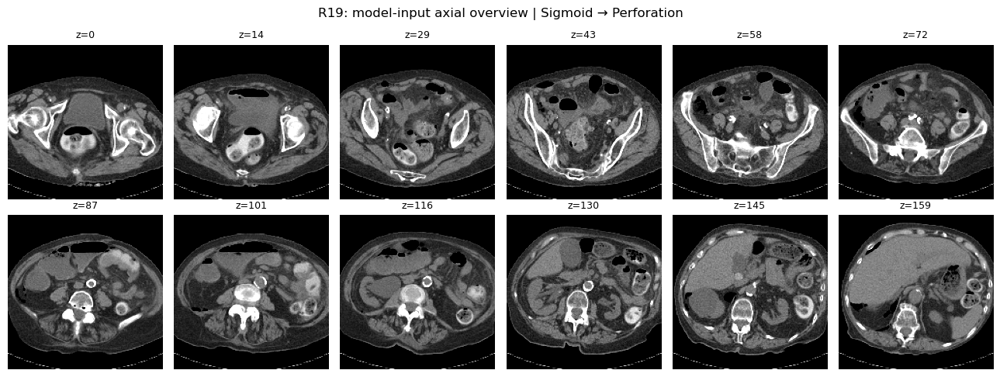

**Caption.** R19: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

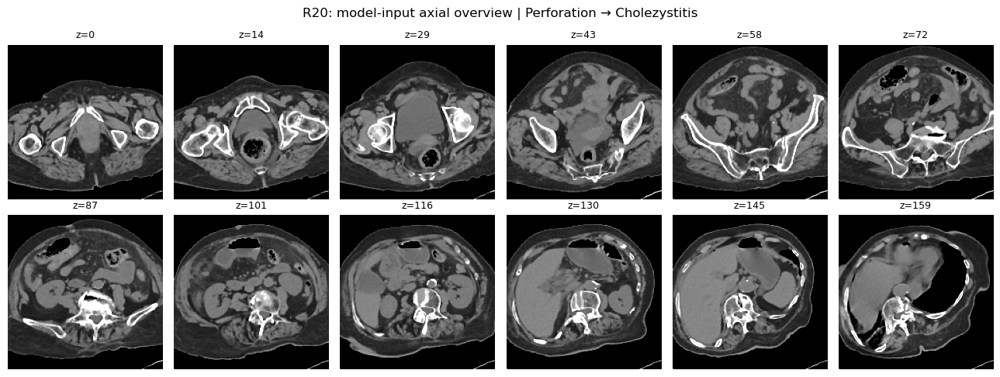

**Caption.** R20: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.

In [46]:
for row in review.itertuples():
    save_figure(rh.ct_overview(row,review_base),f'Figure_S11_{row.review_id}_CT_overview',
        f'{row.review_id}: 12 axial slices through the cropped 2-mm model input, WL 40 / WW 400. Original full-scan anatomy may extend beyond the crop.')

## 22. Proposed Results and Discussion
    This draft separates numerical findings from interpretation. It is generated from this execution,
    with explicit qualifications for retrospective endpoint changes, selected-case review and
    explanatory maps. Clinical recruitment, reference-standard, reader and ethics details require
    author input; the notebook cannot establish them from filenames or predictions.

In [47]:
draft = rh.manuscript_text(main,ensembles,paired,review,main_class,source_sensitivity)
draft_path = EXPORT_ROOT/'Results_and_Discussion_4.txt'
draft_path.write_text(draft,encoding='utf-8')
record_artifact(draft_path,'Proposed Results and Discussion with computed estimates and editorial limitations.')
draft_html = EXPORT_ROOT/'Results_and_Discussion_4.html'
draft_html.write_text('<!doctype html><meta charset="utf-8"><title>Results and Discussion</title><style>body{max-width:900px;margin:45px auto;font:17px/1.6 Georgia;color:#182e3b}p{margin-bottom:1.1em}</style>'+''.join('<p>'+html.escape(p)+'</p>' for p in draft.split('\n\n')),encoding='utf-8')
record_artifact(draft_html,'Readable proposed Results and Discussion; author verification remains necessary.')
display(Markdown(draft))

RESULTS — proposed manuscript text (exploratory retrospective reporting)

Study cohort and completed analyses. The fixed held-out cohort comprised 278 patients: 47 with recorded appendicitis, 37 cholecystitis, 90 Normal, 18 perforation and 86 Sigmoid labels. The development pool contained 1,080 patients. Five nested development pools contained 248, 456, 664, 872 and 1,080 patients; the perforation development pool remained fixed at 40. Thirteen supervised pipelines were compared using the same test patients and five-fold probability ensembles. All 65 method-by-fraction ensemble cells were available (Tables 1–3; Figure 1).

Overall performance. At full development size, FlexiCT final-block adaptation had the highest observed macro-F1 among the evaluated pipelines, 0.920 (95% CI, 0.881–0.954), with balanced accuracy 0.919 and accuracy 0.928. This is an observed ranking, not a prospectively selected winner. Macro-F1 was 0.771 (95% CI, 0.710–0.828) for Pillar-0 final-block adaptation, 0.704 (95% CI, 0.636–0.767) for DenseNet from scratch and 0.646 (95% CI, 0.578–0.712) for corrected Merlin ConvLoRA+LLRD (Table 3; Figure 2).

FlexiCT adaptation increased observed macro-F1 from 0.809 to 0.920; paired difference 0.111 (95% CI, 0.065–0.161; exploratory Holm-adjusted permutation P=0.0019).

Pillar0 adaptation increased observed macro-F1 from 0.724 to 0.771; paired difference 0.047 (95% CI, 0.001–0.090; exploratory Holm-adjusted permutation P=0.2849).

COLIPRI adaptation increased observed macro-F1 from 0.548 to 0.665; paired difference 0.118 (95% CI, 0.058–0.175; exploratory Holm-adjusted permutation P=0.0022).

Merlin adaptation increased observed macro-F1 from 0.299 to 0.646; paired difference 0.347 (95% CI, 0.276–0.417; exploratory Holm-adjusted permutation P=0.0019).

The Pillar-0 adaptation contrast did not meet the 0.05 threshold after multiplicity adjustment. Reported 95% effect intervals are pointwise and unadjusted for the comparison family; they need not agree with multiplicity-adjusted tests.

DenseNet versus corrected Merlin. The observed macro-F1 advantage of DenseNet was 0.058 (paired 95% CI, -0.027–0.141; Holm-adjusted permutation P=0.751). The interval includes zero; these data do not establish superior robustness or a reliable performance advantage over corrected Merlin.

Retrospective full-network addition. Merlin FullFineTune CV_2 achieved macro-F1 0.746 (95% CI, 0.680–0.806), versus 0.704 (95% CI, 0.636–0.767) for DenseNet trained from scratch; paired difference 0.042 (95% CI -0.029–0.114; Holm-adjusted P=0.7507). The interval includes zero. Table S16 shows all five fractions and three matched routes. These data contradict a universal 72% CNN accuracy or macro-F1 ceiling.

3DINO linear probing. The frozen-encoder classifier achieved macro-F1 0.489 (95% CI, 0.416–0.557), versus 0.403 (95% CI, 0.357–0.449) with LoRA. The probe-minus-LoRA difference was 0.086 (95% CI 0.014–0.154; adjusted P=0.3954). Accuracy was 0.525 and 0.543, respectively, illustrating that accuracy and macro-F1 need not rank pipelines identically. All 15 saved probe test cells are included; the earlier omission was a notebook-scope error. Table S17 provides matched-size and matched-route comparisons.

Version-4 inference recalculates all 19 planned full-development ensemble comparisons as one exploratory Holm family. Pointwise paired intervals remain unadjusted. Earlier adjusted P values must not be combined with this release.

Class-specific performance. Perforation sensitivity was FlexiCT final block: 16/18, 0.889 (Wilson 95% CI, 0.672–0.969); Pillar-0 final block: 10/18, 0.556 (Wilson 95% CI, 0.337–0.754); DenseNet: 7/18, 0.389 (Wilson 95% CI, 0.203–0.614); corrected Merlin: 9/18, 0.500 (Wilson 95% CI, 0.290–0.710). The 3DINO LoRA pipeline correctly classified 0/18 perforation cases; these small denominators require cautious interpretation (Table 4; Figure 5).

Data efficiency. Macro-F1 at the smallest and largest development pools was: FlexiCT, 0.867 to 0.920; Pillar0, 0.707 to 0.771; DenseNet, 0.430 to 0.704. Intermediate fractions are shown as point estimates without bands in Figures 3a and 3b; numerical intervals appear in Table S1. These nested-sample curves do not estimate robustness to external hospitals or acquisition protocols.

Checkpoint-source sensitivity. Ensemble-minus-refit macro-F1 differences at full development size ranged from -0.039 to 0.490 across 13 matched pipelines; 10 had a higher ensemble point estimate. Source-specific results and paired intervals are supplied in Tables S1 and S9 and Figure S6. The main table consistently uses ensembles rather than choosing each pipeline's best-performing test route. The overall emphasis on ensembles remains a retrospective reporting change.

Exploratory error reread. FlexiCT final-block ensemble predictions disagreed with the original labels in 20 of 278 patients (7.2%). A radiologist provided narrative comments on these selected disagreements; 19 case IDs matched directly and one was linked provisionally by elimination and user confirmation of plausibility. An analyst coding of the comments grouped 6 as confirmed errors, 2 as reference-label discrepancies, 2 as absence of support for the recorded target diagnosis, 2 as overlapping target diagnoses, 5 as other disease or proposed exclusion, and 3 as likely errors or uncertain references. These categories are editorial synthesis, not a second adjudicated reference standard (Figure 6; Table S12). Original labels, cohort membership and headline metrics were retained.

Within the same FlexiCT-selected 20 cases, Pillar-0 final-block ensemble predictions matched the original label in 8/20 and agreed with FlexiCT in 10/20 (Table S13). These conditional counts do not estimate relative full-cohort performance or radiologist-confirmed accuracy. Saved predictions superseded transcription discrepancies in the supplied comparison table.

Attribution diagnostics. All 20 saved explanation runs reproduced the ensemble probabilities within 1e-4. Targeted occlusion reduced predicted-class probability more than the mean of random occlusions with a positive decrease in 14/20 cases; targeted occlusion increased predicted-class probability in 6/20. Median targeted and random probability changes were 0.152 and 0.023. These perturbations and coarse token Grad-CAM maps are exploratory model diagnostics, not validated lesion localization (Figures S9–S10).

DISCUSSION — proposed manuscript text

The comparison suggests that task-specific adaptation can materially improve the utility of pretrained CT representations for this five-class endpoint. FlexiCT had the highest observed ensemble performance, while DenseNet trained from scratch remained a competitive reference pipeline. This does not establish that transformers outperform CNNs, or that pretraining itself caused the differences: preprocessing, pretraining corpora, adaptation scope, optimization and search budgets differed across pipelines. DenseNet comparisons with both corrected Merlin adapters and full-network Merlin remained statistically uncertain; full-network Merlin had the higher ensemble point estimate. The 3DINO probe result also shows that task adaptation is not guaranteed to improve macro-F1 over a frozen representation. Architecture-family and robustness claims require controlled experiments and external validation.

The reread illustrates why a model–label disagreement is not automatically a diagnostic failure. Some recorded Normal cases contained inflammatory disease; sigmoid diverticulitis and perforation coexisted in two narratives; other patients had disorders outside the mutually exclusive label set. Conversely, proven subtle cholecystitis, appendicitis and covered perforation remained clinically meaningful misses. A model can recognize inflammation yet choose an incorrect specific diagnosis. Absence of a particular target disease must not be interpreted as a disease-free Normal abdomen.

The reread should be presented as an exploratory error analysis in Results, with its implications for reference-standard quality and label design developed here in Discussion. It cannot establish radiologist superiority, model superiority or corrected overall accuracy: cases were selected on FlexiCT error status after evaluation; review blinding and structured adjudication were not documented; remaining test cases were not reread. Proposed exclusions or label revisions would require a separate, consistently applied adjudication protocol for the entire cohort before a new sensitivity analysis. The provisional original-source/cohort provisional linkage linkage also needs author verification.

Grad-CAM and occlusion help inspect model behavior but cannot prove that the model localized the lesion or used a radiologist-proposed mimic. The stored maps have a coarse 16-mm grid; smoothing adds no anatomical information. Display scales are independent across targets, slices are selected at the predicted-map maximum rather than a lesion annotation, and masking changes input distribution. Negative occlusion changes and limited randomization checks further caution against causal interpretation. Representative images should illustrate complementary failure mechanisms, with all 20 cases supplied transparently in the supplement.

The Pillar-0 comparison belongs in the supplement as a conditional case audit. Its complete-cohort result already appears in the main table. Selection of cases solely because FlexiCT failed creates an asymmetric comparison and favors apparent rescues by the comparator; a general head-to-head claim must use all 278 paired predictions. Neither model should receive post-hoc diagnostic credit solely because a narrative mentions related inflammation.

Limitations include retrospective endpoint/reporting changes after results were available, repeated inspection of the same held-out cohort, a small perforation test sample, enriched class prevalence, fixed perforation training support, missing external validation and repeated training seeds, and incomplete demographic/acquisition metadata. Patient-bootstrap intervals condition on the fitted models and do not capture training variability. Probability calibration, attribution plausibility and internal performance do not establish prospective clinical utility.

AUTHOR ITEMS BEFORE SUBMISSION: verify the clinical meaning of Sigmoid and Normal; document reference-standard construction, reader experience, reread timing and blinding; confirm the provisional ID linkage; supply recruitment/exclusion, demographic/scanner and ethics information. Preserve the distinction between the original endpoint and retrospective commentary.

## 23. Main-paper versus supplementary allocation
    The proposed package respects the journal's Original Research allowance of six main figures and
    four main tables. One paired-effects plot could be moved to the supplement if the journal/editor
    prefers more clinical imagery. Complete case review, calibration, alternative checkpoint routes,
    zero-shot and sensitivity details are supplementary. The Pillar-0 case comparison stays supplementary.
    The complete notebook and local audit are reproducibility materials, not a submission-ready supplement:
    clinical authors must confirm deidentification, permissions and the journal's final packaging format.

In [48]:
placement = pd.DataFrame([
 ('Main','Table 1','Cohort composition','Defines all denominators; add demographics when available'),
 ('Main','Table 2','Methods and initialization','Makes recipe / adaptation differences explicit'),
 ('Main','Table 3','Full-development ensemble performance','Primary comparative evidence with 95% CIs'),
 ('Main','Table 4','Class-specific sensitivity','Makes perforation and minority-class performance visible'),
 ('Main','Figure 1','Partition and development sizes','Available cohort design; not recruitment flow'),
 ('Main','Figure 2','Overall performance intervals','Macro-F1 and supporting endpoints'),
 ('Main','Figure 3','Panels 3a and 3b: data-efficiency curves','Partial adaptation/probes and full-network comparisons; five sizes'),
 ('Main','Figure 4','Paired effect sizes','Exploratory paired differences'),
 ('Main','Figure 5','Class performance','Sensitivity and class AP'),
 ('Main','Figure 6','Four CT / Grad-CAM examples','Illustrates differing error mechanisms, without localization claims'),
 ('Supplement','Tables S1–S11; S15–S17','Full numeric / statistical evidence','Other routes, calibration, zero-shot, paired sizes and uncertainty'),
 ('Supplement','Table S12','All 20 narrative rereads','Original labels and provisional linkage remain visible'),
 ('Supplement','Table S13','Pillar-0 selected-case comparison','Conditional descriptive comparison, not superiority analysis'),
 ('Supplement','Table S14','Attribution diagnostics','Occlusion, fold stability, limited randomization, crop context'),
 ('Supplement','Figures S1–S8','Performance sensitivities','Confusion, ROC/PR, overlap, routes, zero-shot and calibration'),
 ('Supplement','Figure S9','Occlusion / map diagnostics','Quantitative evidence and counterexamples'),
 ('Supplement','Figures S10–S11','All 20 image cases','Three-plane maps and cropped-input overviews'),
 ('Discussion','Narrative','Reference standard, overlapping labels, difficult anatomy','Interpret the exploratory findings; do not retrospectively improve accuracy'),
 ('Local audit','Provenance and verbatim comments','Source IDs, email excerpts, transcription discrepancies and hashes','Retain locally; do not submit as public supplementary material'),
],columns=['placement','item','content','rationale'])
display(save_table(placement,'manuscript_placement','Proposed editorial allocation for Radiology: Artificial Intelligence.','audit'))
main_figures = {__import__('re').match(r'Figure_(\d+)',Path(a['path']).name).group(1) for a in ARTIFACTS if a['path'].startswith('main/figures/')}
main_tables = {Path(a['path']).stem for a in ARTIFACTS if a['path'].startswith('main/tables/')}
assert len(main_figures)==6 and len(main_tables)==4
assert len(review)==20 and replay_checks.source_volume_hash_verified.all()
print(f'Editorial allocation verified: {len(main_figures)} main figures, {len(main_tables)} main tables; all 20 error cases included.')

## 24. Detailed interpretation for Results and Discussion
The following companion updates all 13 pipelines, all checkpoint routes, the expanded paired
family and the architectural claims. It is generated from this execution's validated results.

In [49]:
import detailed_notes_4 as dn
detailed=dn.generate(main,ensembles,chosen_results,paired,main_class,review,probe_comparison,full_network_comparison)
for suffix,content in [('txt',detailed),('html',dn.as_html(detailed))]:
    path=EXPORT_ROOT/f'Detailed_Results_and_Interpretation_4.{suffix}'
    path.write_text(content,encoding='utf-8')
    record_artifact(path,'Detailed version-4 results, pipeline interpretation and discussion guidance.')
display(Markdown(detailed))

# Detailed Results, interpretation and Discussion · version 4

This companion is generated from the executed version-4 analysis. It includes 13 supervised pipelines, 65 ensemble cells, all 188 available supervised test cells and four separate zero-shot protocols. The 15 completed 3DINO linear-probe cells and 15 publication-derived full-network Merlin cells are included throughout. Earlier releases are preserved as historical outputs, not combined with current adjusted P values. The concise manuscript draft remains available separately as Results_and_Discussion_4.txt/html. Main versus supplementary allocation is in the notebook’s editorial table.

## 1. What the denominators and metrics establish

The fixed test cohort comprises 278 patients: appendicitis 47, cholecystitis 37, Normal 90, perforation 18 and Sigmoid 86. Normal and Sigmoid together account for 63.3% of patients. Accuracy weights every patient equally; balanced accuracy gives each class equal weight through mean sensitivity; macro-F1 gives each class equal weight through precision and recall. Thus accuracy, macro-F1 and balanced accuracy can rank methods differently. Macro AP measures probability ranking at the observed class prevalence; macro OvR AUROC summarizes pairwise ranking and should not replace the multiclass decision endpoint. Brier score, log loss and top-label ECE address different aspects of probabilistic prediction; lower is better for these three measures. None is a clinical utility measure.

Development pools contain 248, 456, 664, 872 and 1,080 patients. Perforation support remains 40 at every size, so both class composition and total sample size change. Each CV ensemble averages five fold-model probability vectors; its members individually train on four folds. Full-development refits and validation-selected best-fold models are separate routes. The same original test labels are retained for every model and after the reread.

The 10,000 class-stratified bootstrap draws are shared across models, preserving paired comparisons and observed test-class counts. Intervals condition on the fitted models; they do not measure training-seed variation, external-site variation or different prevalence. Version 4 recalculates the 19 planned full-development ensemble macro-F1 permutation tests and their Holm adjustment. Pointwise confidence intervals are unadjusted and need not agree with adjusted tests. All inference is exploratory because the reporting emphasis and scope were revised after results were available.

## 2. Overall ensemble results and manuscript emphasis

At the full development size, the observed macro-F1 ordering is: FlexiCT Final block, 92.0%; FlexiCT Frozen features, 80.9%; Pillar0 Final block, 77.1%; Merlin Full fine-tuning, 74.6%; Pillar0 Frozen features, 72.4%; DenseNet 3D DenseNet121 from scratch, 70.4%; COLIPRI Final block, 66.5%; Merlin ConvLoRA + LLRD, 64.6%; MedicalNet Full fine-tuning, 59.4%; COLIPRI Frozen + native pooling, 54.8%; 3DINO Frozen features, 48.9%; 3DINO LoRA, 40.3%; Merlin Frozen features, 29.9%. The ordering describes this completed set and is not a prospective winner-selection procedure. Table 3 and Figure 2 should carry the main estimates and uncertainty. Table 4 and Figure 5 add the classwise clinical context. Figure 3a shows partial adaptation and frozen comparators; Figure 3b shows full-network Merlin/MedicalNet versus scratch DenseNet. Both panels display observed estimates without confidence bands, smoothing or extrapolation. Numerical intervals remain available in Table S1.

The useful main-paper message is the combination of strong FlexiCT transfer, heterogeneous effects of adaptation, and meaningful conventional CNN performance. Avoid reducing it to “transformers beat CNNs.” 3DINO linear probing exceeds its LoRA macro-F1 endpoint, while Merlin full-network adaptation materially improves the interpretation of Merlin compared with its frozen or corrected-adapter results. These differences make the adaptation recipe part of the result, not a detail that can be omitted.

## 3. Complete pipeline-by-pipeline interpretation

Each paragraph reports the same 100% ensemble endpoint, the observed five-size curve and available full-development routes. Curve values are ordered by 248, 456, 664, 872 and 1,080 development patients. Differences across sizes are descriptive; the largest observed point is not used to choose a fraction.

### 3DINO — Frozen features

Observed results: macro-F1 48.9% (95% CI 41.6–55.7); accuracy 52.5% (95% CI 46.8–58.3); balanced accuracy 47.3% (95% CI 40.8–54.1); macro AP 0.522; macro OvR AUROC 0.786. Multiclass Brier score is 0.640, log loss 1.306 and top-label ECE 0.137. The macro-F1 curve is 36.8%, 46.4%, 42.4%, 44.9%, 48.9%, a smallest-to-largest change of +12.0 percentage points. At 100%, the refit macro-F1 is 47.8% and the best-fold macro-F1 is 42.7%. Perforation sensitivity is 6/18 (33.3%; Wilson 95% CI 16.3–56.3%).

Interpretation and Discussion: The frozen representation supports a better macro-F1 endpoint than this LoRA recipe, although its accuracy is lower. A classifier can improve minority-class precision/recall balance while classifying fewer patients correctly overall. Native classifier/readout selection and LoRA optimization differ, so this contrast does not identify why adaptation underperformed. The probe was missing from the prior notebook method list, not from the completed experiment. Include both methods wherever 3DINO is discussed.

### 3DINO — LoRA

Observed results: macro-F1 40.3% (95% CI 35.7–44.9); accuracy 54.3% (95% CI 49.3–59.4); balanced accuracy 42.3% (95% CI 37.7–47.0); macro AP 0.543; macro OvR AUROC 0.819. Multiclass Brier score is 0.579, log loss 1.118 and top-label ECE 0.069. The macro-F1 curve is 39.1%, 43.0%, 44.4%, 38.3%, 40.3%, a smallest-to-largest change of +1.2 percentage points. At 100%, the refit macro-F1 is 38.4% and the best-fold macro-F1 is 40.1%. Perforation sensitivity is 0/18 (0.0%; Wilson 95% CI 0.0–17.6%).

Interpretation and Discussion: This task-adapted LoRA pipeline has a nonmonotonic curve and weak multiclass decisions. No perforation case is correctly identified at 100%. The linear-probe comparison rules out describing this curve as the only evidence about the frozen representation. Higher ranking metrics do not resolve poor argmax classification; a different tuning or full-network recipe would be a different experiment, not an explanation established here.

### COLIPRI — Frozen + native pooling

Observed results: macro-F1 54.8% (95% CI 47.8–61.3); accuracy 56.1% (95% CI 50.4–61.9); balanced accuracy 54.1% (95% CI 47.2–60.8); macro AP 0.595; macro OvR AUROC 0.837. Multiclass Brier score is 0.590, log loss 1.172 and top-label ECE 0.139. The macro-F1 curve is 43.7%, 44.6%, 53.4%, 55.0%, 54.8%, a smallest-to-largest change of +11.1 percentage points. At 100%, the refit macro-F1 is 52.8% and the best-fold macro-F1 is 52.5%. Perforation sensitivity is 8/18 (44.4%; Wilson 95% CI 24.6–66.3%).

Interpretation and Discussion: Native pooling and classifier search should be named explicitly: this comparator is not uniformly a strict linear probe. Modest performance does not show that all pretrained features are uninformative. Spatial preprocessing, pooling, classifier selection and task alignment are intertwined. A local flattening of this curve is not an intrinsic representation ceiling.

### COLIPRI — Final block

Observed results: macro-F1 66.5% (95% CI 59.4–72.8); accuracy 68.3% (95% CI 62.9–73.7); balanced accuracy 64.3% (95% CI 57.4–71.0); macro AP 0.737; macro OvR AUROC 0.903. Multiclass Brier score is 0.455, log loss 1.114 and top-label ECE 0.106. The macro-F1 curve is 48.5%, 54.9%, 52.6%, 57.5%, 66.5%, a smallest-to-largest change of +18.1 percentage points. At 100%, the refit macro-F1 is 58.8% and the best-fold macro-F1 is 68.8%. Perforation sensitivity is 9/18 (50.0%; Wilson 95% CI 29.0–71.0%).

Interpretation and Discussion: Final-block adaptation improves the full-development endpoint relative to the native frozen-encoder pooling/classifier procedure. This is a comparison of model-specific pipelines rather than identical linear classifiers. The intermediate nonmonotonicity and minority-class uncertainty preclude a claim of uniform improvement for every training increment or diagnosis.

### FlexiCT — Frozen features

Observed results: macro-F1 80.9% (95% CI 75.0–86.3); accuracy 84.9% (95% CI 80.6–88.8); balanced accuracy 80.2% (95% CI 74.2–86.0); macro AP 0.888; macro OvR AUROC 0.968. Multiclass Brier score is 0.235, log loss 0.658 and top-label ECE 0.074. The macro-F1 curve is 75.9%, 78.7%, 79.7%, 79.2%, 80.9%, a smallest-to-largest change of +5.0 percentage points. At 100%, the refit macro-F1 is 83.4% and the best-fold macro-F1 is 80.4%. Perforation sensitivity is 12/18 (66.7%; Wilson 95% CI 43.7–83.7%).

Interpretation and Discussion: Strong frozen-feature performance indicates useful transferred information for this endpoint. The additional final-block gain shows that a useful representation and useful task adaptation can coexist. It does not isolate pretraining corpus size, architecture or multimodal supervision as the cause. Do not compare its downstream sample count directly with the source model pretraining data size.

### FlexiCT — Final block

Observed results: macro-F1 92.0% (95% CI 88.1–95.4); accuracy 92.8% (95% CI 89.6–95.7); balanced accuracy 91.9% (95% CI 87.6–95.6); macro AP 0.957; macro OvR AUROC 0.988. Multiclass Brier score is 0.132, log loss 0.294 and top-label ECE 0.044. The macro-F1 curve is 86.7%, 92.2%, 90.8%, 91.8%, 92.0%, a smallest-to-largest change of +5.3 percentage points. At 100%, the refit macro-F1 is 89.0% and the best-fold macro-F1 is 91.0%. Perforation sensitivity is 16/18 (88.9%; Wilson 95% CI 67.2–96.9%).

Interpretation and Discussion: This is the highest observed macro-F1 pipeline among those evaluated. Strong performance with the smallest development pool supports labeled-data efficiency of this transferred pipeline. Its intermediate maximum must not be used to select a test-optimal training fraction. The 20 original-label disagreements remain in the denominator after the radiologist reread.

### Merlin — Frozen features

Observed results: macro-F1 29.9% (95% CI 25.9–34.2); accuracy 52.5% (95% CI 48.6–56.5); balanced accuracy 34.6% (95% CI 31.5–38.0); macro AP 0.543; macro OvR AUROC 0.830. Multiclass Brier score is 0.653, log loss 1.265 and top-label ECE 0.139. The macro-F1 curve is 24.2%, 25.4%, 26.2%, 30.6%, 29.9%, a smallest-to-largest change of +5.7 percentage points. At 100%, the refit macro-F1 is 33.8% and the best-fold macro-F1 is unavailable under the eligible protocol. Perforation sensitivity is 0/18 (0.0%; Wilson 95% CI 0.0–17.6%).

Interpretation and Discussion: The frozen task classifier has substantially lower macro-F1 than either adaptation route. Its higher accuracy must be interpreted alongside class support and minority-class recall; accuracy weights prevalent classes more strongly. This result concerns the saved image-only five-class classifier, not every task or representation accessible to Merlin.

### Merlin — ConvLoRA + LLRD

Observed results: macro-F1 64.6% (95% CI 57.8–71.2); accuracy 68.7% (95% CI 63.3–74.1); balanced accuracy 63.1% (95% CI 56.5–69.9); macro AP 0.720; macro OvR AUROC 0.901. Multiclass Brier score is 0.438, log loss 0.858 and top-label ECE 0.061. The macro-F1 curve is 52.8%, 60.3%, 60.4%, 63.2%, 64.6%, a smallest-to-largest change of +11.8 percentage points. At 100%, the refit macro-F1 is 58.8% and the best-fold macro-F1 is 63.4%. Perforation sensitivity is 9/18 (50.0%; Wilson 95% CI 29.0–71.0%).

Interpretation and Discussion: Corrected adapters improve markedly over this frozen-feature classifier but do not match full-network adaptation at the largest size. The earlier pre-gradient-fix adapter recipe remains excluded. Limited trainable capacity and optimization differences are plausible hypotheses, not measured causes. The small-data ordering differs from the full-development ordering.

### Merlin — Full fine-tuning

Observed results: macro-F1 74.6% (95% CI 68.0–80.6); accuracy 78.8% (95% CI 74.1–83.5); balanced accuracy 73.0% (95% CI 66.8–79.3); macro AP 0.815; macro OvR AUROC 0.941. Multiclass Brier score is 0.327, log loss 0.654 and top-label ECE 0.058. The macro-F1 curve is 50.1%, 51.5%, 65.4%, 72.1%, 74.6%, a smallest-to-largest change of +24.5 percentage points. At 100%, the refit macro-F1 is 72.8% and the best-fold macro-F1 is 67.0%. Perforation sensitivity is 8/18 (44.4%; Wilson 95% CI 24.6–66.3%).

Interpretation and Discussion: Full-network adaptation changes the interpretation of Merlin substantially. Its ensemble point estimate exceeds DenseNet at each sampled size and exceeds corrected adapters at the larger sizes. The full-development paired ensemble interval versus DenseNet includes zero. The evidence supports higher observed performance, not a definitive superiority or robustness claim. FullFineTune CV_2 is method-specific and must not be confused with corrected ConvLoRA_LLRD CV_2.

### Pillar0 — Frozen features

Observed results: macro-F1 72.4% (95% CI 66.7–78.1); accuracy 75.5% (95% CI 70.5–80.2); balanced accuracy 74.2% (95% CI 68.1–80.2); macro AP 0.797; macro OvR AUROC 0.939. Multiclass Brier score is 0.433, log loss 0.874 and top-label ECE 0.249. The macro-F1 curve is 68.5%, 67.5%, 71.3%, 73.0%, 72.4%, a smallest-to-largest change of +3.9 percentage points. At 100%, the refit macro-F1 is 73.7% and the best-fold macro-F1 is 72.7%. Perforation sensitivity is 12/18 (66.7%; Wilson 95% CI 43.7–83.7%).

Interpretation and Discussion: The frozen-feature result supports transferable task information. Calibration and classwise performance must accompany aggregate discrimination: relatively good F1 does not mean numerical confidence is reliable. Cases correctly classified among another model’s errors are a selected subset and cannot establish overall superiority.

### Pillar0 — Final block

Observed results: macro-F1 77.1% (95% CI 71.0–82.8); accuracy 80.2% (95% CI 75.5–84.9); balanced accuracy 76.4% (95% CI 70.4–82.4); macro AP 0.823; macro OvR AUROC 0.952. Multiclass Brier score is 0.313, log loss 0.605 and top-label ECE 0.069. The macro-F1 curve is 70.7%, 72.3%, 74.9%, 75.3%, 77.1%, a smallest-to-largest change of +6.4 percentage points. At 100%, the refit macro-F1 is 71.5% and the best-fold macro-F1 is 74.0%. Perforation sensitivity is 10/18 (55.6%; Wilson 95% CI 33.7–75.4%).

Interpretation and Discussion: Final Atlas block adaptation has a higher aggregate endpoint than the frozen probe, but the gain is modest relative to paired uncertainty and multiplicity. Aggregate improvement is not improvement in every class. The selected FlexiCT-error comparison is supplementary evidence only; the full 278-patient paired comparison is the basis for head-to-head conclusions.

### MedicalNet — Full fine-tuning

Observed results: macro-F1 59.4% (95% CI 52.6–65.9); accuracy 62.2% (95% CI 56.8–67.6); balanced accuracy 59.1% (95% CI 52.3–65.9); macro AP 0.646; macro OvR AUROC 0.857. Multiclass Brier score is 0.522, log loss 1.022 and top-label ECE 0.097. The macro-F1 curve is 35.5%, 40.3%, 40.2%, 46.9%, 59.4%, a smallest-to-largest change of +23.9 percentage points. At 100%, the refit macro-F1 is 10.5% and the best-fold macro-F1 is 55.1%. Perforation sensitivity is 8/18 (44.4%; Wilson 95% CI 24.6–66.3%).

Interpretation and Discussion: This is full-network transfer from pretrained weights. Improvement across the available development range does not bring the endpoint to the strongest transferred models. Its large ensemble/refit discrepancy warrants training and selection analysis before attributing weakness to architecture. The notebook preserves each completed route rather than selecting the best test outcome.

### DenseNet — 3D DenseNet121 from scratch

Observed results: macro-F1 70.4% (95% CI 63.6–76.7); accuracy 74.5% (95% CI 69.4–79.5); balanced accuracy 68.7% (95% CI 62.3–75.2); macro AP 0.771; macro OvR AUROC 0.920. Multiclass Brier score is 0.369, log loss 0.805 and top-label ECE 0.055. The macro-F1 curve is 43.0%, 47.9%, 60.4%, 66.6%, 70.4%, a smallest-to-largest change of +27.4 percentage points. At 100%, the refit macro-F1 is 43.0% and the best-fold macro-F1 is 66.5%. Perforation sensitivity is 7/18 (38.9%; Wilson 95% CI 20.3–61.4%).

Interpretation and Discussion: This model trains all parameters from random initialization; calling it pretrained full fine-tuning would be incorrect. Its improvement across development sizes contradicts a universal early CNN plateau in this experiment. The refit discrepancy is reported separately from the ensemble. Neither a favorable ensemble score nor internal calibration establishes robustness across hospitals or scanner protocols.

## 4. Every planned paired ensemble comparison

The direction below is method A minus method B. Positive values favor A. These are matched-patient macro-F1 differences with 95% pointwise bootstrap intervals and two-sided permutation P values Holm-adjusted across all 19 configured comparisons. A positive point estimate alone does not establish a reliable advantage. A nonsignificant test does not establish equivalence.

3DINO Frozen features − DenseNet 3D DenseNet121 from scratch: -21.5 percentage points (95% CI -30.2 to -13.0); adjusted P=0.0019.
3DINO LoRA − 3DINO Frozen features: -8.6 percentage points (95% CI -15.4 to -1.4); adjusted P=0.3954.
3DINO LoRA − DenseNet 3D DenseNet121 from scratch: -30.1 percentage points (95% CI -37.2 to -22.5); adjusted P=0.0019.
COLIPRI Frozen + native pooling − DenseNet 3D DenseNet121 from scratch: -15.6 percentage points (95% CI -22.9 to -8.0); adjusted P=0.0019.
COLIPRI Final block − COLIPRI Frozen + native pooling: +11.8 percentage points (95% CI +5.8 to +17.5); adjusted P=0.0022.
COLIPRI Final block − DenseNet 3D DenseNet121 from scratch: -3.9 percentage points (95% CI -10.6 to +2.7); adjusted P=0.7507.
FlexiCT Frozen features − DenseNet 3D DenseNet121 from scratch: +10.5 percentage points (95% CI +3.7 to +17.7); adjusted P=0.0333.
FlexiCT Final block − FlexiCT Frozen features: +11.1 percentage points (95% CI +6.5 to +16.1); adjusted P=0.0019.
FlexiCT Final block − DenseNet 3D DenseNet121 from scratch: +21.6 percentage points (95% CI +15.3 to +28.6); adjusted P=0.0019.
Merlin Frozen features − DenseNet 3D DenseNet121 from scratch: -40.5 percentage points (95% CI -47.8 to -32.6); adjusted P=0.0019.
Merlin ConvLoRA + LLRD − Merlin Frozen features: +34.7 percentage points (95% CI +27.6 to +41.7); adjusted P=0.0019.
Merlin ConvLoRA + LLRD − DenseNet 3D DenseNet121 from scratch: -5.8 percentage points (95% CI -14.1 to +2.7); adjusted P=0.7507.
Pillar0 Frozen features − DenseNet 3D DenseNet121 from scratch: +2.0 percentage points (95% CI -5.0 to +9.4); adjusted P=0.7507.
Pillar0 Final block − Pillar0 Frozen features: +4.7 percentage points (95% CI +0.1 to +9.0); adjusted P=0.2849.
Pillar0 Final block − DenseNet 3D DenseNet121 from scratch: +6.7 percentage points (95% CI -0.6 to +14.2); adjusted P=0.3954.
MedicalNet Full fine-tuning − DenseNet 3D DenseNet121 from scratch: -11.0 percentage points (95% CI -18.9 to -2.6); adjusted P=0.07279.
Merlin Full fine-tuning − DenseNet 3D DenseNet121 from scratch: +4.2 percentage points (95% CI -2.9 to +11.4); adjusted P=0.7507.
Merlin Full fine-tuning − Merlin ConvLoRA + LLRD: +9.9 percentage points (95% CI +3.4 to +16.2); adjusted P=0.02.
Merlin Full fine-tuning − Merlin Frozen features: +44.6 percentage points (95% CI +37.3 to +51.8); adjusted P=0.0019.

## 5. Why the 3DINO probe changes the interpretation

At 100%, linear probing has macro-F1 48.9% versus 40.3% for LoRA, a paired probe-minus-LoRA difference of +8.6 points (95% CI +1.4 to +15.4). Accuracy is 52.5% versus 54.3%, so a claim that the probe is uniformly better across endpoints would be wrong. Table S17 reports all five sizes and three routes for macro-F1, accuracy and balanced accuracy. The probe curve is not monotonic and LoRA has higher macro-F1 at some smaller sizes.

The Holm-adjusted permutation P value for this contrast is 0.3954. The unadjusted bootstrap interval and the multiplicity-adjusted permutation test answer different questions; the latter does not establish a difference at the 0.05 threshold.

Suggested Results wording: “The 3DINO frozen-encoder linear probe achieved a higher full-development macro-F1 point estimate than the evaluated LoRA pipeline, despite lower overall accuracy; the comparison was not significant after multiplicity adjustment.” Suggested Discussion wording: “Adaptation gains were model- and recipe-dependent. The 3DINO result cautions against assuming that increasing the number of trainable parameters necessarily improves downstream classification.” Class-specific decisions, native classifier/readout selection and LoRA tuning would need controlled follow-up to explain the contrast. No mechanistic explanation is established by these predictions.

## 6. Merlin full-network adaptation versus DenseNet

Merlin full-network CV_2 has higher ensemble macro-F1 point estimates at each sampled development size. At 100%, the values are 74.6% and 70.4%; difference +4.2 points (95% CI -2.9 to +11.4). The interval includes zero. Table S16 is the requested complete comparison, with 45 rows covering three metrics, five sizes and three matched routes. Merlin and MedicalNet are pretrained full-network fine-tuning; DenseNet is full-network training from random initialization.

Do not generalize the ensemble ordering to every route. For example, DenseNet’s 60% refit is above the corresponding Merlin full-network refit, and the 100% best-fold estimates are close. The large 100% refit difference favors Merlin partly in the setting of DenseNet’s much weaker refit than ensemble. Preserve the route-specific results instead of describing a single architecture as robust. Suggested manuscript wording: “Full-network Merlin achieved higher ensemble point estimates than DenseNet trained from scratch, although the paired full-development interval did not establish a clear ensemble advantage.”

## 7. Fact check: CNN performance and data requirements

The proposed claim that CNNs never exceed 72% accuracy or F1 is false. Eligible full-network Merlin reaches 78.8% accuracy and 74.6% macro-F1; DenseNet reaches 74.5% accuracy. Do not conflate accuracy and macro-F1 or omit the full-network Merlin recipe when describing CNN performance.

The proposed transformer data claim needs two distinctions: pretraining data versus labeled downstream development data, and a particular training recipe versus an intrinsic architecture property. Here the transferred FlexiCT pipeline is already strong at 248 development patients, whereas 3DINO is substantially weaker despite also using a transformer encoder. This study cannot identify an architecture-only data requirement.

The proposed CNN saturation claim is also unsupported as a general conclusion. DenseNet and full-network Merlin continue to improve over the sampled development range. A model can plateau under a fixed capacity or optimization schedule without establishing a universal ceiling. The cited studies support conditional inductive-bias and scale arguments, not a guarantee that all CNNs are better with small clinical datasets or that ViTs always require many labeled CT cases.

[Dosovitskiy et al., ICLR 2021](https://arxiv.org/html/2010.11929v2). The original ViT experiments support a benefit of large-scale pretraining and report earlier ResNet saturation in a particular comparison. This concerns natural-image pretraining regimes, not a universal minimum number of labeled downstream CT patients.

[Touvron et al., ICML 2021 (DeiT)](https://proceedings.mlr.press/v139/touvron21a.html). Data-efficient training and distillation produced competitive transformers using ImageNet without external training data. This qualifies an absolute claim that every ViT requires enormous external pretraining datasets; ImageNet itself is much larger than this clinical cohort.

[Kolesnikov et al., ECCV 2020 (BiT)](https://arxiv.org/html/1912.11370v3). ResNet-based transfer benefits depend on model capacity, pretraining data and training duration. CNNs can benefit from additional data and transfer across small and large downstream regimes.

[Liu et al., CVPR 2022 (ConvNeXt)](https://arxiv.org/abs/2201.03545). Competitive and scalable pure convolutional models counter an intrinsic CNN ceiling. Natural-image benchmark scores are not numerically comparable with this five-class CT test cohort.

## 8. Learning curves, route sensitivity and uncertainty

Report actual development counts rather than implying that nominal 20% is exactly one fifth of 1,080. The fixed 40-case perforation pool means relative class support decreases as other classes are added. Native hyperparameters may also change with development selection. The curves therefore compare complete training pipelines across these nested subsets, not a pure sample-size intervention with fixed class composition and fixed optimization.

Table S2 reports within-pipeline differences from 100%; Table S3 gives normalized trapezoidal macro-F1 area over the observed count range. AULC is a descriptive summary of the five measured points and does not interpolate missing runs or estimate a minimum clinically sufficient sample size. Table S15 extends paired pipeline contrasts across smaller sizes. It does not add significance tests for every observed difference.

Table S9 compares checkpoint routes only where model, method, percentage, CV identity and effective parameter signature match. Table S1 retains all eligible routes regardless of whether that matching gate is satisfied. The seven unavailable best-fold cells are five Merlin frozen-probe cells and two COLIPRI native-pooling cells; they are explicit gaps, not zeros. Completion means all available outputs were analyzed, not that missing experimental routes were fabricated.

Ensemble/refit differences do not by themselves prove bagging robustness, checkpoint failure, overfitting or data leakage. Training histories and repeated controlled runs would be needed to distinguish hypotheses. Test-time route selection would bias the comparison; the main analysis consistently uses ensembles. Bootstrap rank stability in Table S8 measures resampling sensitivity among the 13 included pipelines, not the probability that a model is truly best in another population.

## 9. Classwise discrimination, calibration and shared failures

Perforation has only 18 test cases; one patient changes sensitivity by 5.6 percentage points. Report numerator, denominator and interval, especially when a model correctly identifies zero cases. A high aggregate macro-F1 does not guarantee adequate perforation sensitivity, and an increase in class precision can accompany a sensitivity decrease. Table S5 retains the full confusion-derived metrics, AP and AUROC; Figure S3 displays confusion matrices and Figure S4 ranking curves.

Calibration and discrimination must be separated. Raw probabilities are evaluated without test-set recalibration. Top-label ECE uses ten fixed bins and is sensitive to bin support; Brier and log loss penalize probability error differently. These values are prevalence-dependent and cannot establish calibrated deployment risk at another institution. Figure S8 and Table S6 belong in the supplement unless probability reliability is a main study objective.

Shared-error counts in Table S7/Figure S5 reveal overlap on the same cohort. Complementary errors may motivate a future cross-model ensemble, but choosing its weights using these test labels would invalidate the held-out comparison. The four zero-shot protocols remain a separate supplement because prompts, normalization and task adaptations differ. Their relative scores must not be assumed calibrated; Pillar-0’s prompt-similarity task is experimental.

## 10. Radiologist reread: Results content and Discussion implications

All 20 FlexiCT final-block ensemble disagreements remain reported as errors against the original labels: 20/278, or 7.2%. The radiologist reviewed a model-selected subset, not an independent sample of all test patients. Nineteen comment IDs match exactly; the 8701-to-Perforation_R20 link remains provisional despite the user’s confirmation of plausibility by elimination. The notebook does not silently convert that linkage into certainty.

The analyst-coded narrative categories are Confirmed model error: 6, Other disease / proposed exclusion: 5, Likely error / uncertain reference: 3, Reference-label discrepancy: 2, Target diagnosis not supported: 2, Overlapping target diagnoses: 2. This coding summarizes prose, not a blinded adjudicated reference standard. Some disagreements involve overlapping target diagnoses, unsupported recorded targets or disease outside the five mutually exclusive categories. Others remain genuine clinically consequential misses. A case with no supported target diagnosis is not necessarily a normal abdomen.

Pillar-0 matches the original label in 8/20 selected cases and makes the same prediction as FlexiCT in 10/20. This selection is asymmetric and cannot estimate overall superiority or radiologist-confirmed accuracy. Use canonical saved predictions; the supplied manual table differs for Sigmoid_R08. The comparison belongs in Table S13, alongside the full-cohort result already in Table 3.

Put a short quantitative reread description and representative error mechanisms in Results. In Discussion, address reference-standard uncertainty, overlapping diagnoses and label ontology; do not claim corrected accuracy or retrospectively exclude inconvenient cases. A defensible relabeling sensitivity analysis would require a consistent adjudication procedure applied to the full cohort, with reader details and blinding documented.

## 11. Grad-CAM, CT panels and perturbation evidence

All 20 existing explanation runs reproduce the stored ensemble probabilities within tolerance. Targeted masking produces a positive probability decrease exceeding the mean of three random masks in 14/20 cases, and increases the predicted-class probability in 6/20. Median targeted and random probability drops are 0.152 and 0.023. Preserve these counterexamples when discussing attribution rather than showing only convincing heatmaps.

The saved token maps are coarse: 20³ tokens at 16-mm spacing from 160³ inputs at 2-mm spacing. Positive targets are independently normalized; signed contrast can compare direction but does not create an anatomical lesion annotation. Displayed planes pass through the predicted-map maximum, not a verified lesion coordinate. Six 40³-voxel cubes occupy 9.375% of the model input and span 80 mm each, potentially masking multiple structures. Mean- and air-filled occlusions change the input distribution. Only one fold’s classifier head was randomized, so that diagnostic does not validate lesion localization.

Figure 6 should illustrate distinct clinical disagreement mechanisms using four examples, with radiologist comments clearly attributed. Figures S9–S11 preserve quantitative diagnostics, all 20 three-plane attributions and all 20 CT overviews. No lesion arrows are added without verified coordinates. These materials support inspection of model behavior, not proof that the network used the appendix, gallbladder or a proposed mimic causally.

## 12. Suggested Discussion synthesis and editorial placement

The main interpretation is that transfer performance in this five-class abdominal CT task depends strongly on the pretrained model and the adaptation recipe. FlexiCT performs well with both frozen features and final-block adaptation, while 3DINO does not benefit uniformly from LoRA. Merlin’s full-network result changes conclusions drawn from its frozen or limited-adapter variants. Conventional DenseNet training remains competitive, and the observed CNN curves do not support an intrinsic low performance ceiling. These findings motivate controlled optimization and transfer studies rather than architecture-wide superiority claims.

The radiologist reread provides a complementary clinical interpretation of model–label disagreement. Ambiguous or overlapping categories can make an apparently simple multiclass endpoint clinically imperfect, yet true misses of subtle disease remain important. Uncertain reference labels, non-target inflammation and complex anatomy should be described without retrospectively redefining the test endpoint. Attribution maps provide examples and limitations of model inspection, not a substitute for lesion annotations or reader studies.

Main paper: Tables 1–4 for cohort, methods, full-development performance and class sensitivity; Figures 1–6 for design, interval comparisons, Figure 3a/b learning curves, paired effects, class performance and selected clinical images. Supplement: all numeric runs, uncertainty, calibration, confusion/ranking, routes, zero-shot, all rereads, Pillar-0 selected-case comparison, all attribution images and Tables S16–S17. Detailed model-by-model prose is an author resource; select only findings that advance the main argument for the journal manuscript.

Limitations to retain: retrospective emphasis on ensembles and expanded comparison scope after result inspection; repeated use of the same test cohort; model-specific preprocessing, pretraining and search budgets; small perforation support; changing training composition; absent repeated training seeds and external cohorts; incomplete clinical demographics, acquisition, recruitment and reader-protocol metadata. None of these internal estimates establishes external robustness, fairness, prospective utility or a causal effect of architecture. Clinical authors must verify label definitions, ethics and reference-standard construction, finalize the provisional case linkage, and approve deidentified image selection before submission.


## 25. Verify and freeze this execution's export manifest
The manifest stores exact inputs, settings, selected run IDs, software versions, companion-code hashes,
and every current output checksum. New results are discovered on rerun; cached computations are never
reused across changed source hashes. Raw results and other notebooks remain untouched.

In [50]:
assert not discovery_audit[discovery_audit.status=='accepted'].run_id.duplicated().any()
assert all(len(predictions[r][0]) == N_TEST for r in inventory.run_id)
assert set(main.source) <= {PRIMARY_SOURCE}
assert not main.duplicated(['model','method','percentage']).any()
assert set(zero_shot.model) <= set(ah.FOUNDATION_MODELS)
assert all(r.method in ah.METHODS[r.model] for r in inventory[~inventory.zero_shot].itertuples())
assert (inventory[(~inventory.zero_shot)&inventory.model.isin(ah.FOUNDATION_MODELS)].source_family == 'publication').all()
assert all((EXPORT_ROOT / artifact['path']).is_file() for artifact in ARTIFACTS)
configuration = {'version':ANALYSIS_VERSION,'bootstrap_replicates':BOOTSTRAP_REPLICATES,
    'permutation_replicates':PERMUTATION_REPLICATES,'seed':SEED,'calibration_bins':CALIBRATION_BINS,
    'main_source':PRIMARY_SOURCE,'main_percentage':MAIN_PERCENTAGE,'run_overrides':RUN_OVERRIDES,
    'class_order':ah.CLASSES,'selection_policy':'foundation publication-only; baselines publication then grid then default; unresolved ties excluded',
    'allowed_supervised_methods':ah.METHODS,'zero_shot_models':list(ah.FOUNDATION_MODELS),
    'comparison_plan':pair_plan.to_dict('records'),'inferential_status':'exploratory, retrospective reporting amendment'}
manifest = {'generated_at_utc':datetime.now(timezone.utc).isoformat(),'configuration':configuration,
    'python':platform.python_version(),'packages':{p:version(p) for p in ['numpy','pandas','matplotlib','scipy','scikit-learn','nbformat']},
    'code_hashes':{p.name:ah.digest(p) for p in [NOTEBOOK_DIR/'analysis_helpers_4.py',NOTEBOOK_DIR/'plot_helpers_4.py',NOTEBOOK_DIR/'build_notebook_4.py',NOTEBOOK_DIR/'execute_notebook_4.py',NOTEBOOK_DIR/'review_helpers_4.py',NOTEBOOK_DIR/'review_cells_4.py',NOTEBOOK_DIR/'detailed_notes_4.py']},
    'notebook_source_hash':ah.fingerprint([(''.join(c.get('source',[])),c['cell_type']) for c in ah.read_json(NOTEBOOK_DIR/'Publication_Results_4.ipynb')['cells']]),
    'split_hashes':split_audit.to_dict('records'),'input_hashes':input_hashes,'review_input_hashes':review_input_hashes,
    'selected_runs':selected.run_id.tolist(),'current_artifacts':ARTIFACTS,
    'counts':{'valid_runs':len(inventory),'excluded_runs':int((discovery_audit.status=='excluded').sum()),
              'scope_excluded_runs':int((discovery_audit.status=='scope_excluded').sum()),
              'selected_main_runs':len(main),'heldout_patients':N_TEST}}
manifest_path = EXPORT_ROOT / 'analysis_manifest_4.json'
manifest_path.write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')

### Export index and manuscript-ready observations
The numerical observations below are generated from available results, without selecting or declaring
a test-score winner. Clinical reporting gaps and the provisional case link require author review.

In [51]:
index_lines = ['# Publication results · version 4', '',
    f'Generated: {manifest["generated_at_utc"]}', '',
    'Current output set is defined by analysis_manifest_4.json. Prior unlisted files are not current results.', '',
    '## Analysis status', '',
    f'- {len(inventory)} valid stored runs; {len(main)} full-development ensemble results; {N_TEST} held-out patients.',
    '- Retrospective ensemble-centered reporting; paired inference is exploratory.', '', '## Deliverables', '']
for item in ARTIFACTS:
    index_lines.append(f'- [{item["path"]}]({item["path"]}): {item["caption"]}')
(EXPORT_ROOT/'README_4.md').write_text('\n'.join(index_lines),encoding='utf-8')
observations = [f'Of {DEVELOPMENT_COUNTS[100]+N_TEST:,} included patients, {DEVELOPMENT_COUNTS[100]:,} were assigned to development and {N_TEST} to fixed held-out testing.']
for run in main.itertuples():
    observations.append(f'{run.label}: macro F1 {run.f1_macro:.3f} (95% CI {run.f1_macro_low:.3f}, {run.f1_macro_high:.3f}); balanced accuracy {run.balanced_accuracy:.3f} (95% CI {run.balanced_accuracy_low:.3f}, {run.balanced_accuracy_high:.3f}).')
observations.append('These are retrospective comparative estimates; they do not establish external generalizability or clinical utility.')
(EXPORT_ROOT/'results_observations_4.md').write_text('\n\n'.join(observations),encoding='utf-8')
record_artifact(EXPORT_ROOT/'results_observations_4.md','Numerical manuscript observations without test-score winner selection.')
record_artifact(EXPORT_ROOT/'README_4.md','Captioned index of this execution.')
manifest['current_artifacts'] = ARTIFACTS
manifest_path.write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
display(Markdown(f'**Complete:** {len(inventory)} validated runs, {len(main)} main ensemble rows, '
                 f'{len(ARTIFACTS)} registered artifacts. Outputs: `{EXPORT_ROOT}`.'))
display(pending_main[['model','method','status']])